# Does any metric work on a single stock? NVIDIA vs Micron (v6)

**v6 adds Part D:** an out-of-sample test of the "crash insurance" result on 2000–2004 (the dot-com crash), which the analysis never saw. The prediction is written down before running. Also fixed: figure 17's legend no longer covers a point, and figure 10's title now says "beat random timing". Parts A–C are unchanged.

**v5 adds Part C** (after Part B), from an outside review of v4: an audit of Micron's fundamentals against its 10-K, one extra day of execution delay (C0), the 200-day rule vs a fixed stock/T-bill mix with the same exposure or volatility (C1), every "sell" episode (C2), and whether valuation predicts 12- and 36-month returns (C3). The "EPS beat" rule is renamed: it compares EPS with the same quarter a year earlier, not with analyst expectations. Figures 15–17 are new; the brief gains sections 20–23. Parts A and B are unchanged.

**v4 changes (after the v3 run):** B3's correction for picking the best of 19 now uses Westfall–Young min-p, with 999 draws; v3's max-statistic version is still printed. B4 scores R² against the historical mean instead of zero, and adds a "same rules + each stock's own average" model to separate stock-specific signals from stock-specific average returns. Figure fixes: the 08 legend no longer covers the last row, and 09 and 14 have new titles and bars. Part A and B1, B2, B5–B8 are unchanged.

**v3 adds Part B** (after section 10): shrinkage of each stock's estimates (B1), selection bias (B2), each stock's best rule vs random timing (B3), pooled vs stock-specific vs partially pooled forecast models (B4), year-by-year dependence on 2008/2022 (B5), moving-average lookback sensitivity (B6), trading costs (B7), and a memory gross-margin case study (B8). Part A is unchanged from v2, so its numbers should reproduce exactly. New figures 08–14; the brief gains sections 10–17.


**v2 changes (after the v1 run on data through Nov 6, 2026):**
1. Pure Storage is now ticker **P** (renamed Everpure, ticker changed Apr 17, 2026). Qorvo is gone: acquired by Skyworks on Oct 5, 2026 and delisted, so free data no longer has it (another survivorship case, listed in the brief).
2. Fixed the crash in the final checks cell, so `results.json` and the recording brief now get written.
3. **H3 p-value fix:** v1 permuted each metric's stock labels independently, which ignores that the 19 metrics are correlated within a stock (the trend rules move together), so its p for the average rho was too small. v2 permutes whole stocks jointly across metrics. The v1 version is still printed.
4. **Scale-free robustness for H3 and H4:** effects divided by the stock's volatility. A high-volatility stock has bigger raw effects in both halves, which can create persistence (H3) or a memory gap (H4) that's really just volatility. The pre-registered raw versions are unchanged and reported first.
5. **Single-stock alpha vs the stock itself.** v1's "alpha vs SPY" for an NVDA rule mostly measured NVDA's own run, not the rule. v2 adds timing alpha against buy & hold of the same stock, and the brief uses it.
6. Pick-your-metric test: adds a second "one rule for everyone", chosen by the best pre-2016 Sharpe gain across stocks (v1 chose by the biggest ON-vs-OFF effect, which picked RSI < 30, a rule that's in the market ~11% of the time).
7. Equity-curve figure: fundamental rules start at buy & hold's level on their first day, not at $1.
8. New descriptive section 9b (outside every test): NVDA and MU since the Oct 28, 2026 close (the day before the NYT report on Huang), vs SMH and vs beta x SPY.

**Question for the video:** traders and regular investors judge stocks with a handful of popular numbers: the 200-day moving average, golden crosses, RSI, MACD, P/E, PEG and so on. Do any of them actually tell you when to own NVIDIA or Micron? And if a metric "works" on one stock and not the other, is that real or luck?

**Design (fixed before looking at any results):**

- **Universe:** 52 US-listed (53 planned; Qorvo acquired) semiconductor, memory/storage, equipment and hardware stocks, 2005 to today. NVDA and MU are highlighted, not the whole sample.
- **19 metrics**, each turned into a simple rule: own the stock when the signal is ON, hold T-bills when it's OFF. Signals use the day's close and the position earns the next day's close-to-close return, i.e. it assumes you trade at the signal day's close (C0 adds a day of delay as a check). Fundamentals count only from the trading day after the SEC filing date.
- **Primary effect per stock × metric:** extra annual return on days the signal is ON vs OFF (next-day returns), with Newey-West standard errors (20 lags).
- **H1, does the metric work at all?** Random-effects pooled effect across stocks. Null: circular shifts of the return panel (the same shift for every stock, which keeps autocorrelation and cross-stock correlation). BH across the 19 metrics.
- **H2, "it depends on the stock":** Cochran's Q / I² across stocks, against the same circular-shift null (the chi-square p-value is too optimistic because the stocks move together). BH across the 19 metrics.
- **H3, can you know in advance?** Does a stock's effect in the first half of the data predict its effect in the second half? Spearman across stocks per metric, stock-label permutation null. Plus a practical test: pick each stock's best technical metric before 2016 and see how it did after.
- **H4, the cyclical P/E trap:** valuation signals (P/E, P/S, FCF yield, PEG) should work worse, or flip, for memory/storage (MU, WDC, STX). One primary test: average valuation effect, memory minus the rest, exact label-permutation p. Secondary: correlation with each stock's revenue cyclicality.
- **Strategy level:** CAGR, Sharpe, max drawdown, CAPM alpha vs SPY and Sharpe difference vs buy & hold (stationary block bootstrap), after 10 bps per switch.

**Before running:** `pip install yfinance pandas numpy scipy matplotlib requests`, then set `SEC_USER_AGENT` in the config cell ("Name email", SEC rule). First run downloads ~53 price histories and SEC company facts (about 10–20 minutes, mostly the circular-shift null). Later runs use the cache.

**Known limits:** survivors only (acquired or delisted chip companies aren't in free Yahoo data); SEC company facts can lag a quarter (the checks flag stale filers); the 10-Q filing date is usually a few weeks after the earnings release, so the earnings-drift rule is conservative; Q4 values are derived as annual minus nine months.

In [1]:
import io, json, time, math, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
try:
    import yfinance as yf
except ImportError as e:
    raise ImportError("Run: pip install yfinance") from e

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)

pandas 3.0.0 | numpy 2.4.4 | yfinance 1.7.0


## 1. Config

In [2]:
SEC_USER_AGENT = ""   # SEC asks every script to identify itself: "Your Name you@example.com"

START = "2005-01-01"
END = None                    # None = through the last completed trading day
CACHE_DIR = Path("cache_metrics")
OUT_DIR = Path("outputs_metrics_v6")
CAM_DIR = OUT_DIR / "camera"
REFRESH_DAYS = 2              # re-download prices older than this
SEC_REFRESH_DAYS = 7

COST_BPS = 10                 # one-way cost per switch
NW_LAGS = 20
MIN_DAYS_EACH = 250           # a stock needs >= 250 days ON and >= 250 days OFF for a metric
MIN_DAYS_EACH_HALF = 125      # same, within each half (H3)
OWN_HIST_DAYS, OWN_HIST_MIN = 5 * 252, 3 * 252   # "cheap vs its own history" window
STALE_DAYS = 200              # fundamentals older than this (by period end) are treated as missing
N_SHIFT = 999                 # circular-shift null draws
N_PERM = 9999                 # stock-label permutations (H3)
N_BOOT = 1000                 # bootstrap draws for Sharpe differences
BOOT_BLOCK = 20               # mean block length (trading days)
PICK_SPLIT = "2016-01-01"     # H3 practical test: pick on data before, judge on data after
SEED = 20261109

FOCUS = ["NVDA", "MU"]
GROUPS = {
    "design": ["NVDA", "AMD", "INTC", "QCOM", "AVGO", "TXN", "ADI", "MCHP", "ON", "NXPI", "MRVL", "MPWR", "SWKS",
               "LSCC", "SLAB", "SMTC", "POWI", "DIOD", "SYNA", "CRUS", "AMBA", "MXL", "RMBS", "SITM", "ALGM"],
    "memory_storage": ["MU", "WDC", "STX"],
    "equipment": ["AMAT", "LRCX", "KLAC", "TER", "ENTG", "MKSI", "ONTO", "FORM", "COHU", "ACLS", "UCTT", "ICHR", "KLIC", "AMKR"],
    "hardware": ["SMCI", "HPQ", "NTAP", "ANET", "CSCO", "AAPL", "DELL", "P"],
    "adr_technical_only": ["TSM", "ASML"],     # file IFRS 20-Fs, so no us-gaap fundamentals
}
GONE = {"QRVO": "acquired by Skyworks Oct 5, 2026 (0.960 SWKS + $32.50 cash), delisted; no free price history"}
RENAMED = {"P": "Everpure, formerly Pure Storage (PSTG until Apr 17, 2026)"}
EVENT_DATE = "2026-10-28"     # last close before the NYT report on Huang (Oct 29); section 9b only
TICKERS = [t for g in GROUPS.values() for t in g]
GROUP_OF = {t: g for g, ts in GROUPS.items() for t in ts}
BENCH = ["SPY", "SMH"]

TECH = ["above_200dma", "golden_cross", "macd", "rsi_oversold", "rsi_overbought_exit", "bollinger_dip",
        "buy_the_dip", "momentum_12_1", "near_52w_high", "rel_strength_6m"]
FUND = ["pe_cheap_own", "pe_below_20", "ps_cheap_own", "fcf_cheap_own", "peg_below_1",
        "rev_accel", "gm_up", "inv_days_falling", "earnings_beat_drift"]
METRICS = TECH + FUND
VALUATION = ["pe_cheap_own", "pe_below_20", "ps_cheap_own", "fcf_cheap_own", "peg_below_1"]

LABEL = {
    "above_200dma": "Price above 200-day average", "golden_cross": "Golden cross (50d > 200d)",
    "macd": "MACD above signal line", "rsi_oversold": "Buy RSI < 30, sell RSI > 50",
    "rsi_overbought_exit": "Sell RSI > 70, rebuy RSI < 50", "bollinger_dip": "Buy below lower Bollinger band",
    "buy_the_dip": "Buy 10% off 20-day high (hold 20d)", "momentum_12_1": "12-month momentum positive",
    "near_52w_high": "Within 10% of 52-week high", "rel_strength_6m": "Beating SMH over 6 months",
    "pe_cheap_own": "P/E below its 5-year median", "pe_below_20": "P/E under 20",
    "ps_cheap_own": "P/S below its 5-year median", "fcf_cheap_own": "FCF yield above its 5-year median",
    "peg_below_1": "PEG under 1", "rev_accel": "Revenue growth accelerating",
    "gm_up": "Gross margin up year over year", "inv_days_falling": "Inventory days falling",
    "earnings_beat_drift": "Hold 3 months after EPS up vs last year",
}

END_FETCH = (pd.Timestamp(END) + pd.Timedelta(days=1)) if END else pd.Timestamp.today().normalize()
for d in [CACHE_DIR / "prices", CACHE_DIR / "sec", OUT_DIR, CAM_DIR]:
    d.mkdir(parents=True, exist_ok=True)
rng_master = np.random.default_rng(SEED)
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append(dict(check=name, passed=bool(ok), detail=str(detail)))
    print(("PASS " if ok else "FAIL ") + name + (f"  ({detail})" if detail else ""))
print(len(TICKERS), "stocks,", len(METRICS), "metrics")

52 stocks, 19 metrics


## 2. Prices and T-bills

In [3]:
def fresh(p, days=REFRESH_DAYS):
    return p.exists() and (time.time() - p.stat().st_mtime) < days * 86400

def load_prices(tickers):
    out, failed = {}, []
    for t in tickers:
        p = CACHE_DIR / "prices" / f"{t}.pkl"
        if fresh(p):
            out[t] = pd.read_pickle(p); continue
        df = None
        for attempt in range(4):
            try:
                df = yf.Ticker(t).history(start=START, end=END_FETCH, auto_adjust=False, actions=True)
                if df is not None and len(df) > 0:
                    break
            except Exception as e:
                print(f"  {t}: attempt {attempt + 1} failed ({type(e).__name__})")
            time.sleep(3 * (attempt + 1))
        if df is None or len(df) == 0 or not {"Close", "Adj Close"}.issubset(df.columns):
            if p.exists():
                out[t] = pd.read_pickle(p); print(f"  {t}: download failed, using stale cache")
            else:
                failed.append(t)
            continue
        idx = pd.to_datetime(df.index)
        if idx.tz is not None:
            idx = idx.tz_localize(None)
        df.index = idx.normalize()
        if "Stock Splits" not in df.columns:
            df["Stock Splits"] = 0.0
        df = df[["Close", "Adj Close", "Volume", "Stock Splits"]]
        df = df[~df.index.duplicated(keep="last")]
        df.to_pickle(p); out[t] = df
        time.sleep(0.6)
    return out, failed

PX, failed = load_prices(TICKERS + BENCH)
today = pd.Timestamp.today().normalize()
for t in PX:   # drop a partial row for today
    PX[t] = PX[t][PX[t].index < today] if END is None else PX[t]
check("All benchmarks downloaded", all(b in PX for b in BENCH), f"missing: {[b for b in BENCH if b not in PX]}")
check("All stocks downloaded", len(failed) == 0, f"failed: {failed}")
TICKERS = [t for t in TICKERS if t in PX]
check("Renamed tickers carry their full history", all(PX[t].index.min() < pd.Timestamp("2016-01-01") for t in RENAMED if t in PX),
      {t: str(PX[t].index.min().date()) for t in RENAMED if t in PX})

CAL = PX["SPY"].index[PX["SPY"].index >= pd.Timestamp(START)]
print("Calendar:", CAL[0].date(), "to", CAL[-1].date(), f"({len(CAL)} days)")

def load_rf(idx):
    p = CACHE_DIR / "rf.pkl"
    if fresh(p):
        s, src = pd.read_pickle(p)
    else:
        s, src = None, None
        try:
            r = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3", timeout=60)
            r.raise_for_status()
            df = pd.read_csv(io.StringIO(r.text))
            s = pd.Series(pd.to_numeric(df.iloc[:, 1], errors="coerce").values, index=pd.to_datetime(df.iloc[:, 0])).dropna()
            src = "FRED DTB3"
        except Exception as e:
            print("FRED failed:", type(e).__name__, "- falling back to Yahoo ^IRX")
            h = yf.Ticker("^IRX").history(start=START, auto_adjust=False)
            hi = pd.to_datetime(h.index)
            s = pd.Series(h["Close"].values, index=(hi.tz_localize(None) if hi.tz is not None else hi).normalize())
            src = "Yahoo ^IRX"
        pd.to_pickle((s, src), p)
    return (s / 100 / 252).reindex(idx).ffill().bfill(), src

RF, RF_SRC = load_rf(CAL)
check("T-bill series loaded", RF.notna().all() and RF.between(-0.0001, 0.001).all(), RF_SRC)

# Daily total returns (Adj Close) and charting prices (split-adjusted Close) on the common calendar
ADJ = pd.DataFrame({t: PX[t]["Adj Close"] for t in TICKERS + BENCH}).reindex(CAL)
CLOSE = pd.DataFrame({t: PX[t]["Close"] for t in TICKERS + BENCH}).reindex(CAL)
RET = ADJ.ffill(limit=5).pct_change(fill_method=None).where(ADJ.ffill(limit=5).notna())
bad = (RET > 3.0) | (RET < -0.95)
n_bad = int(bad.sum().sum())
RET = RET.mask(bad)
check("Few impossible daily returns (> +300% or < -95%, set to missing)", n_bad < 10,
      f"{n_bad}: {bad.sum()[bad.sum() > 0].to_dict()}")
SPY_R, SMH_R = RET["SPY"], RET["SMH"]
first_day = {t: ADJ[t].first_valid_index() for t in TICKERS}
print(pd.Series({t: d.date() for t, d in first_day.items()}).sort_values().tail(10))

PASS All benchmarks downloaded  (missing: [])
PASS All stocks downloaded  (failed: [])
PASS Renamed tickers carry their full history  ({'P': '2015-10-06'})
Calendar: 2005-01-03 to 2026-11-06 (5497 days)
PASS T-bill series loaded  (FRED DTB3)
PASS Few impossible daily returns (> +300% or < -95%, set to missing)  (0: {})
MXL     2010-03-24
NXPI    2010-08-06
AMBA    2012-10-10
ANET    2014-06-06
P       2015-10-06
DELL    2016-08-17
ICHR    2016-12-09
ONTO    2019-10-28
SITM    2019-11-20
ALGM    2020-10-29
dtype: object


## 3. SEC fundamentals (point in time)

In [4]:
REV = ["Revenues", "RevenueFromContractWithCustomerExcludingAssessedTax", "SalesRevenueNet",
       "RevenueFromContractWithCustomerIncludingAssessedTax", "SalesRevenueGoodsNet"]
GP = ["GrossProfit"]
COGS = ["CostOfRevenue", "CostOfGoodsAndServicesSold", "CostOfGoodsSold"]
EPS = ["EarningsPerShareDiluted", "EarningsPerShareBasicAndDiluted"]
OCF = ["NetCashProvidedByUsedInOperatingActivities", "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations"]
CAPEX = ["PaymentsToAcquirePropertyPlantAndEquipment", "PaymentsToAcquireProductiveAssets"]
INV = ["InventoryNet"]
SHARES = ["WeightedAverageNumberOfDilutedSharesOutstanding"]
FORMS = {"10-K", "10-Q", "10-K/A", "10-Q/A", "10-KT", "10-QT"}

def sec_json(url, path):
    if fresh(path, SEC_REFRESH_DAYS):
        return json.loads(path.read_text())
    if not SEC_USER_AGENT.strip():
        raise ValueError('Set SEC_USER_AGENT in the config cell, e.g. "Jane Doe jane@example.com"')
    r = requests.get(url, headers={"User-Agent": SEC_USER_AGENT}, timeout=90)
    time.sleep(0.2)
    if r.status_code == 404:
        return None
    r.raise_for_status()
    path.write_text(r.text)
    return r.json()

CIK = {v["ticker"].upper(): int(v["cik_str"])
       for v in sec_json("https://www.sec.gov/files/company_tickers.json", CACHE_DIR / "sec" / "company_tickers.json").values()}

def company_facts(t):
    if GROUP_OF[t] == "adr_technical_only" or t not in CIK:
        return None
    return sec_json(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{CIK[t]:010d}.json", CACHE_DIR / "sec" / f"{t}.json")

def facts_df(cf, concepts, unit):
    """All facts for these concepts; per reporting period keep the FIRST filing (no restatement look-ahead).
    Across concepts, the earliest-filed wins; ties go to the earlier concept in the list."""
    g = cf.get("facts", {}).get("us-gaap", {})
    rows = []
    for rank, c in enumerate(concepts):
        for x in g.get(c, {}).get("units", {}).get(unit, []):
            if x.get("form") in FORMS and "filed" in x and "end" in x and x.get("val") is not None:
                rows.append((rank, x.get("start"), x["end"], float(x["val"]), x["filed"]))
    if not rows:
        return pd.DataFrame(columns=["start", "end", "val", "filed"])
    df = pd.DataFrame(rows, columns=["rank", "start", "end", "val", "filed"])
    for c in ["start", "end", "filed"]:
        df[c] = pd.to_datetime(df[c])
    df = df.sort_values(["filed", "rank"]).drop_duplicates(["start", "end"], keep="first")
    return df.drop(columns="rank").reset_index(drop=True)

def quarterly_flow(df):
    """3-month values: direct quarterly facts, else differences of year-to-date facts (gives Q4 = FY - 9M,
    and quarterly cash flows from YTD statements). 'filed' = when the quarter's number became knowable."""
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["end", "val", "filed"])
    df = df.dropna(subset=["start"]).copy()
    df["days"] = (df["end"] - df["start"]).dt.days
    direct = df[df["days"].between(80, 100)]
    q = {r.end: (r.val, r.filed) for r in direct.itertuples()}
    for s, g in df[df["days"] > 100].groupby("start"):
        pts = pd.concat([direct[direct["start"] == s], g]).drop_duplicates("end").sort_values("end")
        prev = None
        for r in pts.itertuples():
            if prev is not None and 80 <= (r.end - prev.end).days <= 100 and r.end not in q:
                q[r.end] = (r.val - prev.val, max(r.filed, prev.filed))
            prev = r
    out = pd.DataFrame([(e, v, f) for e, (v, f) in q.items()], columns=["end", "val", "filed"])
    return out.sort_values("end").reset_index(drop=True)

def quarterly_instant(df):
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["end", "val", "filed"])
    d = df[df["start"].isna()].sort_values("filed").drop_duplicates("end", keep="first")
    return d[["end", "val", "filed"]].sort_values("end").reset_index(drop=True)

def quarterly_shares(df):
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["end", "val", "filed"])
    df = df.dropna(subset=["start"]).copy()
    df["days"] = (df["end"] - df["start"]).dt.days
    q = df[df["days"].between(80, 100)]
    a = df[df["days"].between(340, 380) & ~df["end"].isin(q["end"])]   # Q4 fallback: annual weighted average
    d = pd.concat([q, a]).sort_values("filed").drop_duplicates("end", keep="first")
    return d[["end", "val", "filed"]].sort_values("end").reset_index(drop=True)

def combine(a, b, op):
    m = a.merge(b, on="end", suffixes=("_a", "_b"))
    if len(m) == 0:
        return pd.DataFrame(columns=["end", "val", "filed"])
    return pd.DataFrame({"end": m["end"], "val": op(m["val_a"], m["val_b"]),
                         "filed": np.maximum(m["filed_a"], m["filed_b"])})

def field_events(q, how):
    """For every filing date: what an investor knew that day (TTM or latest value now, a year earlier,
    last quarter, same quarter a year ago, previous quarter and its year-ago quarter)."""
    if q is None or len(q) == 0:
        return pd.DataFrame()
    q = q.sort_values("end")
    out = []
    for ev in np.sort(q["filed"].unique()):
        k = q[q["filed"] <= ev].drop_duplicates("end", keep="first").set_index("end")["val"].sort_index()
        last = k.index[-1]
        def near(endd, days):
            if endd is None:
                return None
            target = endd - pd.Timedelta(days=days)
            d = np.abs(np.asarray((k.index - target).days))
            i = int(d.argmin())
            return k.index[i] if d[i] <= 20 else None
        def ttm(endd):
            if endd is None:
                return np.nan
            if how == "last":
                return k.get(endd, np.nan)
            w = k[(k.index > endd - pd.Timedelta(days=345)) & (k.index <= endd)]
            return w.sum() if (len(w) == 4 and (w.index[-1] - w.index[0]).days >= 250) else np.nan
        ya, pq = near(last, 364), near(last, 91)
        pqya = near(pq, 364)
        out.append(dict(event=pd.Timestamp(ev), end=last, now=ttm(last), prev_year=ttm(ya), q_last=k[last],
                        q_yago=k[ya] if ya is not None else np.nan,
                        q_prev=k[pq] if pq is not None else np.nan,
                        q_prev_yago=k[pqya] if pqya is not None else np.nan))
    return pd.DataFrame(out).set_index("event")

def to_daily(ev, idx):
    """Known from the first trading day AFTER the filing date; stale once the latest period is > STALE_DAYS old."""
    cols = ["end", "now", "prev_year", "q_last", "q_yago", "q_prev", "q_prev_yago"]
    if ev is None or len(ev) == 0:
        return pd.DataFrame(np.nan, index=idx, columns=cols)
    pos = idx.searchsorted(ev.index, side="right")
    ok = pos < len(idx)
    d = ev[ok].copy()
    d.index = idx[pos[ok]]
    d = d[~d.index.duplicated(keep="last")].reindex(idx).ffill()
    stale = ((idx.to_series() - d["end"]).dt.days > STALE_DAYS).values
    d.loc[stale, :] = np.nan
    return d

def split_factor_after(dates, splits):
    """Product of split ratios that happened after each date (to put old per-share numbers on today's share basis)."""
    if len(splits) == 0:
        return np.ones(len(dates))
    return np.array([float(splits[splits.index > d].prod()) for d in dates])

FUND_DAILY, FUND_Q, SEC_LAST_FILED = {}, {}, {}
for t in TICKERS:
    cf = company_facts(t)
    if cf is None:
        continue
    splits = PX[t]["Stock Splits"]
    splits = splits[splits > 0]
    rev = quarterly_flow(facts_df(cf, REV, "USD"))
    gp = quarterly_flow(facts_df(cf, GP, "USD"))
    cogs = quarterly_flow(facts_df(cf, COGS, "USD"))
    if len(gp) == 0 and len(cogs):
        gp = combine(rev, cogs, lambda a, b: a - b)
    if len(cogs) == 0 and len(gp):
        cogs = combine(rev, gp, lambda a, b: a - b)
    # Per-share facts go on today's share basis BEFORE deriving quarters, so Q4 = FY - 9M never mixes bases
    eps_raw = facts_df(cf, EPS, "USD/shares")
    if len(eps_raw):
        eps_raw["val"] = eps_raw["val"] / split_factor_after(eps_raw["filed"], splits)
    sh_raw = facts_df(cf, SHARES, "shares")
    if len(sh_raw):
        sh_raw["val"] = sh_raw["val"] * split_factor_after(sh_raw["filed"], splits)
    eps = quarterly_flow(eps_raw)
    sh = quarterly_shares(sh_raw)
    ocf = quarterly_flow(facts_df(cf, OCF, "USD"))
    capex = quarterly_flow(facts_df(cf, CAPEX, "USD"))
    inv = quarterly_instant(facts_df(cf, INV, "USD"))
    idx = CAL[CAL >= first_day[t]]
    FUND_Q[t] = dict(rev=rev, eps=eps)
    FUND_DAILY[t] = dict(
        rev=to_daily(field_events(rev, "sum"), idx), gp=to_daily(field_events(gp, "sum"), idx),
        cogs=to_daily(field_events(cogs, "sum"), idx), eps=to_daily(field_events(eps, "sum"), idx),
        ocf=to_daily(field_events(ocf, "sum"), idx), capex=to_daily(field_events(capex, "sum"), idx),
        inv=to_daily(field_events(inv, "last"), idx), shares=to_daily(field_events(sh, "last"), idx))
    SEC_LAST_FILED[t] = rev["filed"].max() if len(rev) else pd.NaT

print("Fundamentals built for", len(FUND_DAILY), "of", len(TICKERS), "stocks")
last_px = CAL[-1]
stale = {t: d.date() for t, d in SEC_LAST_FILED.items() if pd.isna(d) or (last_px - d).days > 135}
check("No stale SEC filers (latest revenue filing within 135 days)", len(stale) == 0, f"stale: {stale}")

Fundamentals built for 50 of 52 stocks
FAIL No stale SEC filers (latest revenue filing within 135 days)  (stale: {'SMTC': datetime.date(2026, 5, 27)})


## 4. Turn every metric into a daily ON/OFF signal

In [5]:
def onoff(cond, valid):
    return pd.Series(np.where(valid, cond.astype(float), np.nan), index=cond.index)

def state(enter, exit_, init, valid):
    s = pd.Series(np.nan, index=enter.index)
    s.loc[exit_.astype(bool)] = 0.0
    s.loc[enter.astype(bool)] = 1.0
    s = s.ffill().fillna(init)
    return s.where(valid)

def rsi(close, n=14):
    d = close.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    return 100 - 100 / (1 + up / dn)

def technical(close, adj, smh_adj):
    pos, info = {}, {}
    sma20, sd20 = close.rolling(20).mean(), close.rolling(20).std()
    sma50, sma200 = close.rolling(50).mean(), close.rolling(200).mean()
    v200 = sma200.notna()
    pos["above_200dma"] = onoff(close > sma200, v200)
    pos["golden_cross"] = onoff(sma50 > sma200, v200)
    macd = close.ewm(span=12, adjust=False).mean() - close.ewm(span=26, adjust=False).mean()
    sig = macd.ewm(span=9, adjust=False).mean()
    vmacd = pd.Series(np.arange(len(close)) >= 60, index=close.index)
    pos["macd"] = onoff(macd > sig, vmacd)
    r = rsi(close)
    pos["rsi_oversold"] = state(r < 30, r > 50, 0.0, r.notna())
    pos["rsi_overbought_exit"] = state(r < 50, r > 70, 1.0, r.notna())
    lower = sma20 - 2 * sd20
    pos["bollinger_dip"] = state(close < lower, close > sma20, 0.0, sd20.notna())
    hi20 = close.rolling(20).max()
    dip = (close <= 0.9 * hi20).astype(float).rolling(20, min_periods=1).max()
    pos["buy_the_dip"] = dip.where(hi20.notna())
    m = adj.shift(21) / adj.shift(252) - 1
    pos["momentum_12_1"] = onoff(m > 0, m.notna())
    hi252 = close.rolling(252).max()
    pos["near_52w_high"] = onoff(close >= 0.9 * hi252, hi252.notna())
    rs = (adj / adj.shift(126)) - (smh_adj / smh_adj.shift(126))
    pos["rel_strength_6m"] = onoff(rs > 0, rs.notna())
    info.update({"vs_200dma_%": 100 * (close / sma200 - 1), "50d_vs_200d_%": 100 * (sma50 / sma200 - 1),
                 "macd_minus_signal": macd - sig, "rsi14": r, "vs_lower_band_%": 100 * (close / lower - 1),
                 "off_20d_high_%": 100 * (close / hi20 - 1), "mom_12_1_%": 100 * m,
                 "off_52w_high_%": 100 * (close / hi252 - 1), "rs_vs_smh_6m_pts": 100 * rs})
    return pos, info

def fundamental(t, close):
    F = FUND_DAILY[t]
    idx = F["rev"].index
    P = close.reindex(idx).ffill(limit=5)
    eps_ttm, eps_prev = F["eps"]["now"], F["eps"]["prev_year"]
    has_eps = eps_ttm.notna()
    pe = (P / eps_ttm).where(eps_ttm > 0)
    mcap = P * F["shares"]["q_last"]
    ps = (mcap / F["rev"]["now"]).where(F["rev"]["now"] > 0)
    fcf_y = (F["ocf"]["now"] - F["capex"]["now"]) / mcap
    g_eps = (eps_ttm / eps_prev - 1).where((eps_ttm > 0) & (eps_prev > 0))
    peg = (pe / (100 * g_eps)).where(g_eps > 0)
    rev_g = F["rev"]["q_last"] / F["rev"]["q_yago"] - 1
    rev_g_prev = F["rev"]["q_prev"] / F["rev"]["q_prev_yago"] - 1
    gm, gm_prev = F["gp"]["now"] / F["rev"]["now"], F["gp"]["prev_year"] / F["rev"]["prev_year"]
    invd = F["inv"]["q_last"] / (F["cogs"]["now"] / 365)
    invd_prev = F["inv"]["q_yago"] / (F["cogs"]["prev_year"] / 365)
    med = lambda x: x.rolling(OWN_HIST_DAYS, min_periods=OWN_HIST_MIN).median()
    pe_med, ps_med, fy_med = med(pe), med(ps), med(fcf_y)

    pos = {}
    # Losses count as "not cheap" (P/E undefined); missing data stays missing
    pos["pe_cheap_own"] = pd.Series(np.where(~has_eps | pe_med.isna(), np.nan,
                                             np.where(eps_ttm > 0, (pe < pe_med).astype(float), 0.0)), index=idx)
    pos["pe_below_20"] = pd.Series(np.where(~has_eps, np.nan, np.where(eps_ttm > 0, (pe < 20).astype(float), 0.0)), index=idx)
    pos["ps_cheap_own"] = onoff(ps < ps_med, ps.notna() & ps_med.notna())
    pos["fcf_cheap_own"] = onoff(fcf_y > fy_med, fcf_y.notna() & fy_med.notna())
    pos["peg_below_1"] = pd.Series(np.where(eps_ttm.isna() | eps_prev.isna(), np.nan,
                                            np.where(peg.notna(), (peg < 1).astype(float), 0.0)), index=idx)
    pos["rev_accel"] = onoff(rev_g > rev_g_prev, rev_g.notna() & rev_g_prev.notna())
    pos["gm_up"] = onoff(gm > gm_prev, gm.notna() & gm_prev.notna())
    pos["inv_days_falling"] = onoff(invd < invd_prev, invd.notna() & invd_prev.notna())
    E = F["eps"]
    new_q = E["end"].notna() & (E["end"] != E["end"].shift())
    beat = (new_q & (E["q_last"] > E["q_yago"])).astype(float)
    drift = beat.rolling(63, min_periods=1).max()
    pos["earnings_beat_drift"] = drift.where(E["q_last"].notna() & E["q_yago"].notna())
    info = {"pe": pe, "pe_5y_median": pe_med, "ps": ps, "ps_5y_median": ps_med, "fcf_yield_%": 100 * fcf_y,
            "fcf_yield_5y_median_%": 100 * fy_med, "peg": peg, "eps_growth_ttm_%": 100 * g_eps,
            "rev_growth_yoy_%": 100 * rev_g, "rev_growth_prev_q_%": 100 * rev_g_prev,
            "gross_margin_%": 100 * gm, "gross_margin_yago_%": 100 * gm_prev,
            "inventory_days": invd, "inventory_days_yago": invd_prev,
            "last_q_eps_vs_yago": E["q_last"] - E["q_yago"]}
    return pos, info

POS = {m: pd.DataFrame(np.nan, index=CAL, columns=TICKERS) for m in METRICS}
INFO = {}
for t in TICKERS:
    # technicals on the stock's own trading days (a missing day on the common calendar would blank a 200-day window)
    own = PX[t][PX[t].index >= pd.Timestamp(START)]
    c, a = own["Close"], own["Adj Close"]
    p, info = technical(c, a, PX["SMH"]["Adj Close"].reindex(c.index).ffill())
    if t in FUND_DAILY:
        p2, info2 = fundamental(t, CLOSE[t])
        p.update(p2); info.update(info2)
    for m, s in p.items():
        POS[m][t] = s.reindex(CAL)
    INFO[t] = pd.DataFrame(info).reindex(CAL)

# The position decided at the close of day t earns day t+1's return
POS_EFF = {m: POS[m].shift(1) for m in METRICS}

cov = pd.DataFrame({m: POS[m].notna().sum() / 252 for m in METRICS}).T.round(1)
print("Years of usable signal per metric (median across stocks):")
print(cov.median(axis=1).to_string())
pe_first = {t: POS["pe_cheap_own"][t].first_valid_index() for t in FUND_DAILY}
leak = [t for t, d in pe_first.items() if d is not None and FUND_Q[t]["eps"]["filed"].min() >= d]
check("Fundamental signals start only after filings exist", len(leak) == 0, f"violations: {leak}")

Years of usable signal per metric (median across stocks):
above_200dma           21.00
golden_cross           21.00
macd                   21.60
rsi_oversold           21.80
rsi_overbought_exit    21.80
bollinger_dip          21.70
buy_the_dip            21.70
momentum_12_1          20.80
near_52w_high          20.80
rel_strength_6m        21.30
pe_cheap_own           10.40
pe_below_20            14.40
ps_cheap_own           11.55
fcf_cheap_own          11.50
peg_below_1            14.40
rev_accel              15.25
gm_up                  13.90
inv_days_falling       14.45
earnings_beat_drift    15.40
PASS Fundamental signals start only after filings exist  (violations: [])


In [6]:
# Split check: a split should not make P/E jump (EPS and shares are put on today's share basis)
jumps = []
for t in FUND_DAILY:
    sp = PX[t]["Stock Splits"]
    for d in sp[(sp > 0) & (sp.index > pd.Timestamp("2012-01-01"))].index:
        pe = INFO[t]["pe"]
        i = CAL.searchsorted(d)
        if 2 <= i < len(CAL) - 2:
            a, b = pe.iloc[i - 1], pe.iloc[i + 1]
            if np.isfinite(a) and np.isfinite(b) and not (0.8 <= b / a <= 1.25):
                jumps.append(f"{t} {d.date()} {a:.1f}->{b:.1f}")
check("P/E continuous across stock splits", len(jumps) == 0, "; ".join(jumps) if jumps else "all splits since 2012 checked")
print("NVDA P/E around the June 2024 10:1 split:")
print(INFO["NVDA"]["pe"].loc["2024-06-05":"2024-06-14"].round(1).to_string())

PASS P/E continuous across stock splits  (all splits since 2012 checked)
NVDA P/E around the June 2024 10:1 split:
Date
2024-06-05    71.6
2024-06-06    70.8
2024-06-07    70.7
2024-06-10    71.3
2024-06-11    70.7
2024-06-12    73.3
2024-06-13    75.8
2024-06-14    77.2


## 5. Effect of every metric on every stock

In [7]:
def nw_ols(y, x, lags):
    X = np.column_stack([np.ones_like(x), x])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ (X.T @ y)
    Xu = X * (y - X @ beta)[:, None]
    S = Xu.T @ Xu
    for l in range(1, lags + 1):
        G = Xu[l:].T @ Xu[:-l]
        S += (1 - l / (lags + 1)) * (G + G.T)
    V = XtX_inv @ S @ XtX_inv
    return beta, np.sqrt(np.diag(V))

def effect(y, x, min_each=MIN_DAYS_EACH, lags=NW_LAGS):
    """Extra annual return on ON days vs OFF days (next-day returns), Newey-West SE."""
    y, x = np.asarray(y, float), np.asarray(x, float)
    m = np.isfinite(y) & np.isfinite(x)
    y, x = y[m], x[m]
    n1, n0 = int((x == 1).sum()), int((x == 0).sum())
    if n1 < min_each or n0 < min_each:
        return dict(b=np.nan, se=np.nan, t=np.nan, n_on=n1, n_off=n0)
    beta, se = nw_ols(y, x, lags)
    return dict(b=252 * beta[1], se=252 * se[1], t=beta[1] / se[1], n_on=n1, n_off=n0)

def perf(x, rf):
    ex = x - rf
    yrs = len(x) / 252
    w = (1 + x).cumprod()
    return dict(cagr=w.iloc[-1] ** (1 / yrs) - 1, vol=x.std() * np.sqrt(252),
                sharpe=ex.mean() / ex.std() * np.sqrt(252), max_dd=(w / w.cummax() - 1).min(), years=yrs)

def strategy(t, m, start=None, end=None):
    """Own the stock when ON, T-bills when OFF, 10 bps per switch. Returns aligned (strategy, buy & hold, rf, pos)."""
    d = pd.concat({"r": RET[t], "p": POS_EFF[m][t], "rf": RF, "spy": SPY_R}, axis=1).dropna()
    if start is not None: d = d[d.index >= pd.Timestamp(start)]
    if end is not None: d = d[d.index < pd.Timestamp(end)]
    if len(d) < 2:
        return None
    turn = d["p"].diff().abs()
    turn.iloc[0] = d["p"].iloc[0]
    s = d["p"] * d["r"] + (1 - d["p"]) * d["rf"] - turn * COST_BPS / 1e4
    return s, d["r"], d["rf"], d["p"], d["spy"]

def capm_alpha(s, rf, mkt):
    beta, se = nw_ols((s - rf).values, (mkt - rf).values, NW_LAGS)
    return 252 * beta[0], beta[0] / se[0], beta[1]

rows = []
for m in METRICS:
    for t in TICKERS:
        e = effect(RET[t].values, POS_EFF[m][t].values)
        rec = dict(metric=m, ticker=t, group=GROUP_OF[t], **e)
        if np.isfinite(e["b"]):
            s, bh, rf, p, spy = strategy(t, m)
            ps, pb = perf(s, rf), perf(bh, rf)
            a, at, _ = capm_alpha(s, rf, spy)
            rec.update(frac_on=p.mean(), switches_per_yr=p.diff().abs().sum() / (len(p) / 252),
                       cagr=ps["cagr"], sharpe=ps["sharpe"], max_dd=ps["max_dd"],
                       bh_cagr=pb["cagr"], bh_sharpe=pb["sharpe"], bh_max_dd=pb["max_dd"],
                       d_sharpe=ps["sharpe"] - pb["sharpe"], alpha_spy=a, alpha_spy_t=at, years=ps["years"])
        rows.append(rec)
EFF = pd.DataFrame(rows)
EFF.to_csv(OUT_DIR / "effects_by_stock_metric.csv", index=False)
print("Usable stock-metric pairs:", int(EFF["b"].notna().sum()), "of", len(EFF))
print(EFF[EFF.ticker.isin(FOCUS)].pivot(index="metric", columns="ticker", values="t").reindex(METRICS).round(2))

Usable stock-metric pairs: 921 of 988
ticker                 MU  NVDA
metric                         
above_200dma         1.30  1.59
golden_cross         1.65  1.16
macd                -0.31 -0.63
rsi_oversold         1.25 -0.87
rsi_overbought_exit -1.27 -1.16
bollinger_dip        1.10  0.86
buy_the_dip         -0.37 -1.52
momentum_12_1        1.75 -0.10
near_52w_high        0.92  0.32
rel_strength_6m      2.18  1.23
pe_cheap_own        -2.40 -1.91
pe_below_20         -2.54 -0.63
ps_cheap_own        -1.07 -0.40
fcf_cheap_own       -0.24  0.54
peg_below_1         -1.61 -1.32
rev_accel            2.06  0.22
gm_up               -1.16 -2.52
inv_days_falling     1.23  0.56
earnings_beat_drift  1.02 -0.25


## 6. H1 and H2: does a metric work, and does it really depend on the stock?

In [8]:
def dl_meta(b, se):
    b, se = np.asarray(b, float), np.asarray(se, float)
    ok = np.isfinite(b) & np.isfinite(se) & (se > 0)
    b, se = b[ok], se[ok]
    k = len(b)
    if k < 3:
        return dict(k=k, mu=np.nan, se_mu=np.nan, z=np.nan, Q=np.nan, I2=np.nan, tau=np.nan, p_Q_chi2=np.nan)
    w = 1 / se ** 2
    mu_fe = (w * b).sum() / w.sum()
    Q = (w * (b - mu_fe) ** 2).sum()
    C = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (Q - (k - 1)) / C)
    wr = 1 / (se ** 2 + tau2)
    mu = (wr * b).sum() / wr.sum()
    se_mu = np.sqrt(1 / wr.sum())
    return dict(k=k, mu=mu, se_mu=se_mu, z=mu / se_mu, Q=Q, I2=max(0.0, (Q - (k - 1)) / Q) if Q > 0 else 0.0,
                tau=np.sqrt(tau2), p_Q_chi2=stats.chi2.sf(Q, k - 1))

def bh(p):
    p = np.asarray(p, float)
    q = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    n = ok.sum()
    if n == 0:
        return q
    order = np.argsort(p[ok])
    ranked = p[ok][order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(ranked, 1)
    q[ok] = out
    return q

R_PANEL = RET[TICKERS].values
T_CAL = len(CAL)
shifts = rng_master.integers(252, T_CAL - 252, N_SHIFT)

def shifted_b(P, R, min_each=MIN_DAYS_EACH):
    valid = np.isfinite(R) & np.isfinite(P)
    on, off = valid & (P == 1), valid & (P == 0)
    n1, n0 = on.sum(0), off.sum(0)
    Rz = np.where(valid, R, 0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        b = 252 * ((Rz * on).sum(0) / n1 - (Rz * off).sum(0) / n0)
    b[(n1 < min_each) | (n0 < min_each)] = np.nan
    return b

meta_rows, NULL = [], {}
t0 = time.time()
for m in METRICS:
    sub = EFF[EFF.metric == m].set_index("ticker").reindex(TICKERS)
    real = dl_meta(sub["b"], sub["se"])
    se = sub["se"].values
    P = POS_EFF[m][TICKERS].values
    mus, Qs = np.empty(N_SHIFT), np.empty(N_SHIFT)
    for j, s in enumerate(shifts):
        bs = shifted_b(P, np.roll(R_PANEL, s, axis=0))
        bs[~np.isfinite(sub["b"].values)] = np.nan        # same stocks as the real test
        r = dl_meta(bs, se)
        mus[j], Qs[j] = r["mu"], r["Q"]
    NULL[m] = dict(mu=mus, Q=Qs)
    mc = mus - np.nanmedian(mus)
    p_mu = (1 + np.sum(np.abs(mc) >= abs(real["mu"] - np.nanmedian(mus)))) / (1 + np.isfinite(mus).sum())
    p_Q = (1 + np.sum(Qs >= real["Q"])) / (1 + np.isfinite(Qs).sum())
    df_ = real["k"] - 1
    I2_null95 = np.nanpercentile(np.maximum(0, (Qs - df_) / Qs), 95)
    meta_rows.append(dict(metric=m, label=LABEL[m], **real, p_mu_shift=p_mu, p_Q_shift=p_Q, I2_null95=I2_null95))
    print(f"{m:22s} done ({time.time() - t0:.0f}s)")
META = pd.DataFrame(meta_rows)
META["q_mu"] = bh(META["p_mu_shift"])
META["q_Q"] = bh(META["p_Q_shift"])

# Robustness: market-adjusted returns (stock minus beta x SPY, full-sample beta)
betas = {}
for t in TICKERS:
    ok = (RET[t].notna() & SPY_R.notna()).values
    betas[t] = np.polyfit(SPY_R.values[ok], RET[t].values[ok], 1)[0]
RES = pd.DataFrame({t: RET[t] - betas[t] * SPY_R for t in TICKERS})
res_rows = []
for m in METRICS:
    bb = [effect(RES[t].values, POS_EFF[m][t].values) for t in TICKERS]
    r = dl_meta([x["b"] for x in bb], [x["se"] for x in bb])
    res_rows.append(dict(metric=m, mu_mktadj=r["mu"], z_mktadj=r["z"], I2_mktadj=r["I2"]))
META = META.merge(pd.DataFrame(res_rows), on="metric")
META.to_csv(OUT_DIR / "meta_by_metric.csv", index=False)

show = META[["label", "k", "mu", "z", "p_mu_shift", "q_mu", "I2", "I2_null95", "p_Q_shift", "q_Q", "p_Q_chi2", "mu_mktadj"]].copy()
show[["mu", "mu_mktadj"]] *= 100
print("\nmu = pooled extra annual return when ON (%); I2 = share of spread across stocks beyond chance")
print(show.round(3).to_string(index=False))

# Placebo: random coin-flip signals should show nothing
rng_p = np.random.default_rng(SEED + 1)
pb = []
for t in TICKERS:
    x = pd.Series(rng_p.integers(0, 2, T_CAL).astype(float), index=CAL).where(RET[t].notna())
    pb.append(effect(RET[t].values, x.values))
plac = dl_meta([x["b"] for x in pb], [x["se"] for x in pb])
check("Coin-flip placebo shows no effect", abs(plac["z"]) < 3, f"pooled z = {plac['z']:.2f}, I2 = {plac['I2']:.2f}")

above_200dma           done (2s)
golden_cross           done (3s)
macd                   done (6s)
rsi_oversold           done (7s)
rsi_overbought_exit    done (9s)
bollinger_dip          done (11s)
buy_the_dip            done (13s)
momentum_12_1          done (14s)
near_52w_high          done (16s)
rel_strength_6m        done (18s)
pe_cheap_own           done (20s)
pe_below_20            done (21s)
ps_cheap_own           done (23s)
fcf_cheap_own          done (24s)
peg_below_1            done (26s)
rev_accel              done (27s)
gm_up                  done (29s)
inv_days_falling       done (30s)
earnings_beat_drift    done (32s)

mu = pooled extra annual return when ON (%); I2 = share of spread across stocks beyond chance
                                  label  k      mu      z  p_mu_shift  q_mu    I2  I2_null95  p_Q_shift   q_Q  p_Q_chi2  mu_mktadj
            Price above 200-day average 52 -11.103 -3.414       0.190 0.364 0.164      0.120      0.028 0.196     0.159     -9.679
  

## 7. H3: if a metric worked on a stock before, does it keep working?

In [9]:
def split_date(m):
    valid = (POS_EFF[m][TICKERS].notna() & RET[TICKERS].notna()).sum(axis=1)
    c = valid.cumsum()
    return c.index[c.searchsorted(c.iloc[-1] / 2)]

rng_h3 = np.random.default_rng(SEED + 2)
pers_rows, HALVES = [], {}
for m in METRICS:
    sd = split_date(m)
    h = []
    for t in TICKERS:
        y, x = RET[t], POS_EFF[m][t]
        e1 = effect(y[y.index < sd].values, x[x.index < sd].values, MIN_DAYS_EACH_HALF)
        e2 = effect(y[y.index >= sd].values, x[x.index >= sd].values, MIN_DAYS_EACH_HALF)
        ok = x.notna() & y.notna()
        v1 = y[ok & (y.index < sd)].std() * np.sqrt(252)
        v2 = y[ok & (y.index >= sd)].std() * np.sqrt(252)
        h.append(dict(ticker=t, b1=e1["b"], b2=e2["b"], t1=e1["t"], t2=e2["t"], s1=e1["b"] / v1, s2=e2["b"] / v2))
    h = pd.DataFrame(h).dropna()
    HALVES[m] = h
    if len(h) >= 8:
        rho = stats.spearmanr(h.b1, h.b2).statistic
        perm = np.array([stats.spearmanr(h.b1, rng_h3.permutation(h.b2.values)).statistic for _ in range(N_PERM)])
        p = (1 + np.sum(np.abs(perm) >= abs(rho))) / (1 + N_PERM)
        same_sign = np.mean(np.sign(h.b1) == np.sign(h.b2))
        rho_s = stats.spearmanr(h.s1, h.s2).statistic
    else:
        rho, p, same_sign, rho_s = np.nan, np.nan, np.nan, np.nan
    pers_rows.append(dict(metric=m, label=LABEL[m], split=sd.date(), k=len(h), rho=rho, p_perm=p, same_sign=same_sign,
                          rho_vol_scaled=rho_s))
PERS = pd.DataFrame(pers_rows)
PERS["q"] = bh(PERS["p_perm"])

# All metrics together: is the average rho above zero?
# v1 version (each metric's labels permuted independently; too optimistic because metrics are correlated within a stock)
perm_mean = []
for _ in range(2000):
    r = [stats.spearmanr(HALVES[m].b1, rng_h3.permutation(HALVES[m].b2.values)).statistic
         for m in METRICS if len(HALVES[m]) >= 8]
    perm_mean.append(np.mean(r))
obs_mean = PERS["rho"].mean()
p_mean_v1 = (1 + np.sum(np.array(perm_mean) >= obs_mean)) / 2001

# v2: permute whole stocks jointly (the same relabeling for every metric in a draw)
def mean_rho_joint(B1, B2, perm=None):
    rs = []
    for j in range(B1.shape[1]):
        b2 = B2[:, j] if perm is None else B2[perm, j]
        ok = np.isfinite(B1[:, j]) & np.isfinite(b2)
        if ok.sum() >= 8:
            rs.append(stats.spearmanr(B1[ok, j], b2[ok]).statistic)
    return np.mean(rs)

def joint_test(col1, col2, n=2000):
    B1 = np.full((len(TICKERS), len(METRICS)), np.nan); B2 = B1.copy()
    pos_ = {t: i for i, t in enumerate(TICKERS)}
    for j, m in enumerate(METRICS):
        for r in HALVES[m].itertuples():
            B1[pos_[r.ticker], j] = getattr(r, col1); B2[pos_[r.ticker], j] = getattr(r, col2)
    obs = mean_rho_joint(B1, B2)
    null = np.array([mean_rho_joint(B1, B2, rng_h3.permutation(len(TICKERS))) for _ in range(n)])
    return obs, (1 + np.sum(null >= obs)) / (1 + n)

obs_mean_j, p_mean = joint_test("b1", "b2")
obs_mean_s, p_mean_s = joint_test("s1", "s2")
PERS.to_csv(OUT_DIR / "persistence_by_metric.csv", index=False)
print(PERS.round(3).to_string(index=False))
print(f"\nAverage rho across metrics {obs_mean:.3f}")
print(f"  v1 p (metrics permuted independently, too optimistic): {p_mean_v1:.4f}")
print(f"  v2 p (whole stocks permuted jointly):                  {p_mean:.4f}")
print(f"  volatility-scaled effects: average rho {obs_mean_s:.3f}, joint p {p_mean_s:.4f}")

             metric                                   label      split  k    rho  p_perm  same_sign  rho_vol_scaled     q
       above_200dma             Price above 200-day average 2017-03-10 46  0.295   0.046      0.652           0.294 0.218
       golden_cross               Golden cross (50d > 200d) 2017-03-10 46  0.309   0.036      0.565           0.322 0.218
               macd                  MACD above signal line 2016-12-07 46 -0.002   0.992      0.565           0.049 0.992
       rsi_oversold             Buy RSI < 30, sell RSI > 50 2016-11-07 42  0.218   0.155      0.595           0.283 0.420
rsi_overbought_exit           Sell RSI > 70, rebuy RSI < 50 2016-11-07 45  0.243   0.111      0.556           0.288 0.353
      bollinger_dip          Buy below lower Bollinger band 2016-11-10 45  0.079   0.610      0.600           0.178 0.891
        buy_the_dip      Buy 10% off 20-day high (hold 20d) 2016-11-10 46 -0.032   0.833      0.587           0.084 0.965
      momentum_12_1     

In [10]:
# Practical version: pick each stock's best technical metric on pre-2016 data, judge it on 2016+
def sharpe_of(x, rf):
    ex = x - rf
    return ex.mean() / ex.std() * np.sqrt(252)

pooled_h1 = {m: dl_meta(*zip(*[(e["b"], e["se"]) for e in
             [effect(RET[t][RET.index < PICK_SPLIT].values, POS_EFF[m][t][RET.index < PICK_SPLIT].values, MIN_DAYS_EACH_HALF)
              for t in TICKERS]]))["mu"] for m in TECH}
one_size = max(pooled_h1, key=lambda m: pooled_h1[m])          # v1 rule (pre-registered): biggest pooled effect

raw = []
for t in TICKERS:
    t1, sh1, sh2 = {}, {}, {}
    for m in TECH:
        y, x = RET[t], POS_EFF[m][t]
        e = effect(y[y.index < PICK_SPLIT].values, x[x.index < PICK_SPLIT].values, MIN_DAYS_EACH_HALF)
        if np.isfinite(e["t"]):
            t1[m] = e["t"]
        o1 = strategy(t, m, end=PICK_SPLIT)
        if o1 is not None and len(o1[0]) > 500:
            sh1[m] = sharpe_of(o1[0], o1[2]) - sharpe_of(o1[1], o1[2])
        o2 = strategy(t, m, start=PICK_SPLIT)
        if o2 is not None and len(o2[0]) > 500:
            sh2[m] = sharpe_of(o2[0], o2[2])
    if len(t1) < len(TECH) - 2 or not sh2:
        continue
    raw.append(dict(ticker=t, t1=t1, sh1=sh1, sh2=sh2))

# v2 secondary: one rule for everyone, chosen by the biggest average pre-2016 Sharpe gain over buy & hold
gain_before = {m: np.nanmean([r["sh1"].get(m, np.nan) for r in raw]) for m in TECH}
one_size_sh = max(gain_before, key=gain_before.get)

pick_rows = []
for r in raw:
    best = max(r["t1"], key=r["t1"].get)
    if best not in r["sh2"] or one_size not in r["sh2"] or one_size_sh not in r["sh2"]:
        continue
    o2 = strategy(r["ticker"], best, start=PICK_SPLIT)      # buy & hold over the same days as the picked rule
    pick_rows.append(dict(ticker=r["ticker"], best_before=best, t_before=r["t1"][best], sharpe_after_best=r["sh2"][best],
                          sharpe_after_bh=sharpe_of(o2[1], o2[2]), sharpe_after_avg_metric=np.mean(list(r["sh2"].values())),
                          sharpe_after_one_size=r["sh2"][one_size], sharpe_after_one_size_sh=r["sh2"][one_size_sh]))
PICK = pd.DataFrame(pick_rows)
PICK["best_minus_bh"] = PICK.sharpe_after_best - PICK.sharpe_after_bh
PICK["best_minus_avg"] = PICK.sharpe_after_best - PICK.sharpe_after_avg_metric
PICK["onesize_minus_bh"] = PICK.sharpe_after_one_size - PICK.sharpe_after_bh
PICK["onesize_sh_minus_bh"] = PICK.sharpe_after_one_size_sh - PICK.sharpe_after_bh
PICK["best_minus_onesize_sh"] = PICK.sharpe_after_best - PICK.sharpe_after_one_size_sh
PICK.to_csv(OUT_DIR / "pick_your_metric.csv", index=False)
w_avg = stats.wilcoxon(PICK.best_minus_avg)
w_bh = stats.wilcoxon(PICK.best_minus_bh)
w_os = stats.wilcoxon(PICK.best_minus_onesize_sh)
PICK_SUM = dict(n=len(PICK), one_size_metric=one_size, one_size_sharpe_metric=one_size_sh,
                mean_best_minus_bh=PICK.best_minus_bh.mean(), share_best_beats_bh=(PICK.best_minus_bh > 0).mean(),
                p_best_vs_bh=w_bh.pvalue,
                mean_best_minus_avg=PICK.best_minus_avg.mean(), p_best_vs_avg=w_avg.pvalue,
                mean_onesize_minus_bh=PICK.onesize_minus_bh.mean(), share_onesize_beats_bh=(PICK.onesize_minus_bh > 0).mean(),
                mean_onesize_sh_minus_bh=PICK.onesize_sh_minus_bh.mean(),
                share_onesize_sh_beats_bh=(PICK.onesize_sh_minus_bh > 0).mean(),
                mean_best_minus_onesize_sh=PICK.best_minus_onesize_sh.mean(), p_best_vs_onesize_sh=w_os.pvalue)
print(json.dumps({k: (round(v, 3) if isinstance(v, float) else v) for k, v in PICK_SUM.items()}, indent=1))
print(PICK[PICK.ticker.isin(FOCUS)].round(2).to_string(index=False))

{
 "n": 44,
 "one_size_metric": "rsi_oversold",
 "one_size_sharpe_metric": "rsi_overbought_exit",
 "mean_best_minus_bh": -0.159,
 "share_best_beats_bh": 0.25,
 "p_best_vs_bh": 0.0,
 "mean_best_minus_avg": 0.037,
 "p_best_vs_avg": 0.085,
 "mean_onesize_minus_bh": -0.328,
 "share_onesize_beats_bh": 0.068,
 "mean_onesize_sh_minus_bh": -0.076,
 "share_onesize_sh_beats_bh": 0.295,
 "mean_best_minus_onesize_sh": -0.083,
 "p_best_vs_onesize_sh": 0.015
}
ticker     best_before  t_before  sharpe_after_best  sharpe_after_bh  sharpe_after_avg_metric  sharpe_after_one_size  sharpe_after_one_size_sh  best_minus_bh  best_minus_avg  onesize_minus_bh  onesize_sh_minus_bh  best_minus_onesize_sh
  NVDA   near_52w_high      0.93               0.88             1.22                     0.88                   0.04                      0.93          -0.34           -0.00             -1.18                -0.29                  -0.05
    MU rel_strength_6m      2.07               0.82             0.91         

## 8. H4: the cyclical P/E trap (memory vs everyone else)

In [11]:
val = EFF[EFF.metric.isin(VALUATION)].pivot(index="ticker", columns="metric", values="b")
cnt = val.notna().sum(axis=1)
VSCORE = val[cnt >= 3].mean(axis=1).rename("valuation_effect")
mem = [t for t in GROUPS["memory_storage"] if t in VSCORE.index]
others = [t for t in VSCORE.index if t not in mem]
obs = VSCORE[mem].mean() - VSCORE[others].mean()
names = list(VSCORE.index)
v = VSCORE.values
combos = list(itertools.combinations(range(len(names)), len(mem)))
diffs = np.array([v[list(c)].mean() - np.delete(v, list(c)).mean() for c in combos])
p_two = np.mean(np.abs(diffs) >= abs(obs) - 1e-12)
p_one = np.mean(diffs <= obs + 1e-12)

# Secondary: revenue cyclicality = spread of year-over-year quarterly revenue growth (pre-2016 if >= 12 quarters)
def cyclicality(t):
    q = FUND_Q[t]["rev"].set_index("end")["val"].sort_index()
    q = q[~q.index.duplicated()]
    g = []
    for e, val_ in q.items():
        ya = q.index[np.abs(np.asarray((q.index - (e - pd.Timedelta(days=364))).days)) <= 20]
        if len(ya) and q[ya[0]] > 0:
            g.append((e, val_ / q[ya[0]] - 1))
    if len(g) < 8:
        return np.nan
    g = pd.Series(dict(g)).sort_index()
    pre = g[g.index < pd.Timestamp("2016-01-01")]
    return (pre if len(pre) >= 12 else g).std()

CYC = pd.Series({t: cyclicality(t) for t in VSCORE.index if t in FUND_Q}).rename("rev_growth_sd")
H4 = pd.concat([VSCORE, CYC], axis=1).dropna()
H4["group"] = [GROUP_OF[t] for t in H4.index]
rho_c = stats.spearmanr(H4.valuation_effect, H4.rev_growth_sd)
H4.sort_values("valuation_effect").to_csv(OUT_DIR / "h4_valuation_vs_cyclicality.csv")
H4_SUM = dict(memory=mem, n_stocks=len(VSCORE), memory_mean=VSCORE[mem].mean(), others_mean=VSCORE[others].mean(),
              diff=obs, p_two_exact=p_two, p_one_predicted_direction=p_one, n_label_sets=len(combos),
              rho_cyclicality=rho_c.statistic, p_rho=rho_c.pvalue,
              nvda_cyc_pctile=float((H4.rev_growth_sd < H4.rev_growth_sd.get("NVDA", np.nan)).mean()) if "NVDA" in H4.index else np.nan,
              mu_cyc_pctile=float((H4.rev_growth_sd < H4.rev_growth_sd.get("MU", np.nan)).mean()) if "MU" in H4.index else np.nan)
# Scale-free robustness: (a) each effect divided by the stock's volatility on the same days, (b) average t-stat
def exact_gap(series):
    s = series.dropna()
    nm = [t for t in GROUPS["memory_storage"] if t in s.index]
    vv = s.values
    idx_mem = [list(s.index).index(t) for t in nm]
    o = vv[idx_mem].mean() - np.delete(vv, idx_mem).mean()
    cs = list(itertools.combinations(range(len(vv)), len(nm)))
    dd = np.array([vv[list(c)].mean() - np.delete(vv, list(c)).mean() for c in cs])
    return o, float(np.mean(np.abs(dd) >= abs(o) - 1e-12)), float(np.mean(dd <= o + 1e-12))

vol_on_days = {}
for t in VSCORE.index:
    ok = pd.concat([POS_EFF[m][t] for m in VALUATION], axis=1).notna().any(axis=1) & RET[t].notna()
    vol_on_days[t] = RET[t][ok].std() * np.sqrt(252)
VSCORE_VOL = VSCORE / pd.Series(vol_on_days)
tval = EFF[EFF.metric.isin(VALUATION)].pivot(index="ticker", columns="metric", values="t")
VSCORE_T = tval.loc[VSCORE.index].mean(axis=1)
for name, ser in [("vol_scaled", VSCORE_VOL), ("mean_t", VSCORE_T)]:
    o, p2, p1 = exact_gap(ser)
    H4_SUM[f"{name}_memory_mean"] = ser[mem].mean(); H4_SUM[f"{name}_others_mean"] = ser[others].mean()
    H4_SUM[f"{name}_diff"] = o; H4_SUM[f"{name}_p_two"] = p2; H4_SUM[f"{name}_p_one"] = p1
H4["valuation_effect_vol_scaled"] = VSCORE_VOL.reindex(H4.index)
H4["valuation_mean_t"] = VSCORE_T.reindex(H4.index)
H4.sort_values("valuation_effect").to_csv(OUT_DIR / "h4_valuation_vs_cyclicality.csv")
print(json.dumps({k: (round(x, 4) if isinstance(x, float) else x) for k, x in H4_SUM.items()}, indent=1))
print((100 * val.loc[[t for t in FOCUS + GROUPS["memory_storage"] if t in val.index]].drop_duplicates()).round(1))

{
 "memory": [
  "MU",
  "WDC",
  "STX"
 ],
 "n_stocks": 43,
 "memory_mean": -0.2996,
 "others_mean": 0.0992,
 "diff": -0.3989,
 "p_two_exact": 0.0013,
 "p_one_predicted_direction": 0.0005,
 "n_label_sets": 12341,
 "rho_cyclicality": -0.3383,
 "p_rho": 0.0265,
 "nvda_cyc_pctile": 0.4651,
 "mu_cyc_pctile": 0.7907,
 "vol_scaled_memory_mean": -0.6308,
 "vol_scaled_others_mean": 0.239,
 "vol_scaled_diff": -0.8698,
 "vol_scaled_p_two": 0.0015,
 "vol_scaled_p_one": 0.0004,
 "mean_t_memory_mean": -1.0978,
 "mean_t_others_mean": 0.314,
 "mean_t_diff": -1.4119,
 "mean_t_p_two": 0.0003,
 "mean_t_p_one": 0.0003
}
metric  fcf_cheap_own  pe_below_20  pe_cheap_own  peg_below_1  ps_cheap_own
ticker                                                                     
NVDA             18.1        -13.7         -49.1        -27.3         -14.6
MU               -6.9        -62.9         -77.1        -45.9         -35.1
WDC              30.6        -42.6         -19.6        -10.2         -38.3
STX       

## 9. NVIDIA vs Micron scorecard (strategy level)

In [12]:
def stationary_idx(n, B, mean_block, rng):
    p = 1 / mean_block
    idx = np.empty((B, n), dtype=np.int64)
    idx[:, 0] = rng.integers(0, n, B)
    jump = rng.random((B, n)) < p
    starts = rng.integers(0, n, (B, n))
    for i in range(1, n):
        idx[:, i] = np.where(jump[:, i], starts[:, i], (idx[:, i - 1] + 1) % n)
    return idx

def sharpe_diff_ci(a_ex, b_ex, rng):
    a_ex, b_ex = np.asarray(a_ex), np.asarray(b_ex)
    idx = stationary_idx(len(a_ex), N_BOOT, BOOT_BLOCK, rng)
    A, Bm = a_ex[idx], b_ex[idx]
    d = np.sqrt(252) * (A.mean(1) / A.std(1) - Bm.mean(1) / Bm.std(1))
    obs = np.sqrt(252) * (a_ex.mean() / a_ex.std() - b_ex.mean() / b_ex.std())
    lo, hi = np.percentile(d, [2.5, 97.5])
    p = min(1.0, 2 * min(np.mean(d - d.mean() + obs <= 0), np.mean(d - d.mean() + obs >= 0)))
    return obs, lo, hi, p

rng_b = np.random.default_rng(SEED + 3)
sc_rows = []
for t in FOCUS:
    for m in METRICS:
        e = EFF[(EFF.ticker == t) & (EFF.metric == m)].iloc[0]
        out = strategy(t, m)
        if out is None or not np.isfinite(e["b"]):
            sc_rows.append(dict(ticker=t, metric=m, label=LABEL[m], b=np.nan)); continue
        s, bhr, rf, p, spy = out
        obs, lo, hi, pv = sharpe_diff_ci(s - rf, bhr - rf, rng_b)
        a, at, beta = capm_alpha(s, rf, spy)
        ta, tat, tbeta = capm_alpha(s, rf, bhr)       # timing alpha: vs holding the same stock
        ps, pb = perf(s, rf), perf(bhr, rf)
        sc_rows.append(dict(ticker=t, metric=m, label=LABEL[m], since=s.index[0].date(), b=e["b"], t=e["t"],
                            frac_on=p.mean(), cagr=ps["cagr"], bh_cagr=pb["cagr"], sharpe=ps["sharpe"],
                            bh_sharpe=pb["sharpe"], d_sharpe=obs, d_sharpe_lo=lo, d_sharpe_hi=hi, p_d_sharpe=pv,
                            max_dd=ps["max_dd"], bh_max_dd=pb["max_dd"], timing_alpha=ta, timing_alpha_t=tat,
                            beta_to_stock=tbeta, alpha_spy=a, alpha_t=at, beta_spy=beta))
SC = pd.DataFrame(sc_rows)
SC["q_effect"] = np.nan
for t in FOCUS:
    mk = SC.ticker == t
    SC.loc[mk, "q_effect"] = bh(2 * stats.norm.sf(np.abs(SC.loc[mk, "t"].values)))
SC.to_csv(OUT_DIR / "scorecard_nvda_mu.csv", index=False)
cols = ["label", "since", "b", "t", "q_effect", "frac_on", "cagr", "bh_cagr", "sharpe", "bh_sharpe", "d_sharpe",
        "d_sharpe_lo", "d_sharpe_hi", "max_dd", "bh_max_dd", "timing_alpha", "timing_alpha_t", "beta_to_stock", "alpha_spy"]
for t in FOCUS:
    print(f"\n===== {t} =====")
    print(SC[SC.ticker == t][cols].round(3).to_string(index=False))


===== NVDA =====
                                  label      since      b      t  q_effect  frac_on  cagr  bh_cagr  sharpe  bh_sharpe  d_sharpe  d_sharpe_lo  d_sharpe_hi  max_dd  bh_max_dd  timing_alpha  timing_alpha_t  beta_to_stock  alpha_spy
            Price above 200-day average 2005-10-18  0.405  1.594     0.588    0.730 0.387    0.371   1.018      0.856     0.162       -0.118        0.448  -0.537     -0.851         0.135           2.563          0.583      0.300
              Golden cross (50d > 200d) 2005-10-18  0.291  1.156     0.588    0.736 0.357    0.371   0.940      0.856     0.084       -0.194        0.354  -0.560     -0.851         0.102           1.967          0.623      0.275
                 MACD above signal line 2005-04-01 -0.123 -0.632     0.799    0.520 0.138    0.379   0.499      0.870    -0.371       -0.693       -0.074  -0.579     -0.851        -0.035          -0.687          0.481      0.099
            Buy RSI < 30, sell RSI > 50 2005-01-25 -0.336 -0.865  

In [13]:
# What each metric says right now (descriptive, as of the last close)
last = CAL[-1]
cur = []
key_info = {"above_200dma": "vs_200dma_%", "golden_cross": "50d_vs_200d_%", "macd": "macd_minus_signal",
            "rsi_oversold": "rsi14", "rsi_overbought_exit": "rsi14", "bollinger_dip": "vs_lower_band_%",
            "buy_the_dip": "off_20d_high_%", "momentum_12_1": "mom_12_1_%", "near_52w_high": "off_52w_high_%",
            "rel_strength_6m": "rs_vs_smh_6m_pts", "pe_cheap_own": "pe", "pe_below_20": "pe", "ps_cheap_own": "ps",
            "fcf_cheap_own": "fcf_yield_%", "peg_below_1": "peg", "rev_accel": "rev_growth_yoy_%",
            "gm_up": "gross_margin_%", "inv_days_falling": "inventory_days", "earnings_beat_drift": "last_q_eps_vs_yago"}
ref_info = {"pe_cheap_own": "pe_5y_median", "ps_cheap_own": "ps_5y_median", "fcf_cheap_own": "fcf_yield_5y_median_%",
            "rev_accel": "rev_growth_prev_q_%", "gm_up": "gross_margin_yago_%", "inv_days_falling": "inventory_days_yago",
            "peg_below_1": "eps_growth_ttm_%"}
for m in METRICS:
    rec = dict(metric=m, label=LABEL[m])
    for t in FOCUS:
        sig = POS[m][t].loc[last]
        rec[f"{t}_signal"] = "ON" if sig == 1 else ("OFF" if sig == 0 else "n/a")
        rec[f"{t}_value"] = INFO[t][key_info[m]].loc[last] if key_info[m] in INFO[t] else np.nan
        rec[f"{t}_reference"] = INFO[t][ref_info[m]].loc[last] if m in ref_info and ref_info[m] in INFO[t] else np.nan
    cur.append(rec)
CUR = pd.DataFrame(cur)
CUR.to_csv(OUT_DIR / "current_readings.csv", index=False)
print("As of", last.date())
print(CUR.round(2).to_string(index=False))

As of 2026-11-06
             metric                                   label NVDA_signal  NVDA_value  NVDA_reference MU_signal  MU_value  MU_reference
       above_200dma             Price above 200-day average         OFF       -8.81             NaN       OFF     -8.82           NaN
       golden_cross               Golden cross (50d > 200d)          ON        7.40             NaN        ON     27.08           NaN
               macd                  MACD above signal line         OFF       -3.20             NaN       OFF    -23.21           NaN
       rsi_oversold             Buy RSI < 30, sell RSI > 50          ON       30.76             NaN        ON     31.27           NaN
rsi_overbought_exit           Sell RSI > 70, rebuy RSI < 50          ON       30.76             NaN        ON     31.27           NaN
      bollinger_dip          Buy below lower Bollinger band          ON       -0.58             NaN        ON     -2.77           NaN
        buy_the_dip      Buy 10% off 20-day h

## 9b. Since the Huang report (descriptive only, not part of any test)

The NYT reported on Oct 29, 2026 that US intelligence concluded an executive with a "close relationship" to Jensen Huang was passing information to Beijing; NVIDIA denies it. This only asks how much of NVDA's move since the Oct 28 close is NVIDIA-specific vs chips in general. One event, picked after the fact: don't read it as evidence about any metric.

In [14]:
ev0 = CAL[CAL <= pd.Timestamp(EVENT_DATE)][-1]
win = RET.loc[RET.index > ev0]
beta_win = {}
for t in FOCUS:
    pre = pd.concat([RET[t], SPY_R], axis=1).loc[ev0 - pd.Timedelta(days=365):ev0].dropna()
    beta_win[t] = np.polyfit(pre.iloc[:, 1], pre.iloc[:, 0], 1)[0]
ev_rows = []
for t in FOCUS:
    tot = (1 + win[t]).prod() - 1
    smh = (1 + win["SMH"]).prod() - 1
    spy = (1 + win["SPY"]).prod() - 1
    ab = (1 + (win[t] - beta_win[t] * win["SPY"])).prod() - 1
    ev_rows.append(dict(ticker=t, from_close=ev0.date(), to_close=CAL[-1].date(), days=len(win), stock=tot, smh=smh,
                        spy=spy, stock_minus_smh=tot - smh, beta_1y=beta_win[t], vs_beta_spy=ab))
EV = pd.DataFrame(ev_rows)
EV.to_csv(OUT_DIR / "since_huang_report.csv", index=False)
print(EV.round(4).to_string(index=False))
print("Daily (NVDA, MU, SMH, SPY):")
print((100 * win[["NVDA", "MU", "SMH", "SPY"]]).round(2).to_string())

ticker from_close   to_close  days   stock     smh     spy  stock_minus_smh  beta_1y  vs_beta_spy
  NVDA 2026-10-28 2026-11-06     7 -0.1334 -0.1827 -0.0479           0.0493   1.9304      -0.0457
    MU 2026-10-28 2026-11-06     7 -0.2982 -0.1827 -0.0479          -0.1155   3.3901      -0.1628
Daily (NVDA, MU, SMH, SPY):
            NVDA     MU    SMH   SPY
Date                                
2026-10-29 -0.80  -4.98  -1.06 -0.38
2026-10-30 -4.22  -5.30  -6.98 -1.77
2026-11-02 -1.26  -5.78  -2.71 -0.48
2026-11-03  2.29   2.58   2.01  0.30
2026-11-04 -3.17  -7.00  -2.75  1.65
2026-11-05 -9.26 -17.46 -11.21 -4.41
2026-11-06  2.78   5.12   3.62  0.31


## 10. Strategy level across all stocks (equal-weight)

In [15]:
port_rows, PORT = [], {}
rng_pt = np.random.default_rng(SEED + 4)
for m in METRICS:
    P = POS_EFF[m][TICKERS]
    avail = P.notna() & RET[TICKERS].notna()
    turn = P.diff().abs().fillna(0)
    sleeve = P * RET[TICKERS] + (1 - P).mul(RF, axis=0) - turn * COST_BPS / 1e4
    k = avail.sum(axis=1)
    keep = k >= 10
    s = sleeve.where(avail).sum(axis=1)[keep] / k[keep]
    bhr = RET[TICKERS].where(avail).sum(axis=1)[keep] / k[keep]
    rf = RF[keep]
    PORT[m] = (s, bhr, rf)
    ps, pb = perf(s, rf), perf(bhr, rf)
    obs, lo, hi, pv = sharpe_diff_ci(s - rf, bhr - rf, rng_pt)
    a_t, a_tt, b_t = capm_alpha(s, rf, bhr)          # timing alpha vs equal-weight buy & hold of the same stocks
    a_s, a_st, _ = capm_alpha(s, rf, SPY_R[keep])
    port_rows.append(dict(metric=m, label=LABEL[m], since=s.index[0].date(), avg_stocks=k[keep].mean(),
                          cagr=ps["cagr"], bh_cagr=pb["cagr"], sharpe=ps["sharpe"], bh_sharpe=pb["sharpe"],
                          d_sharpe=obs, d_sharpe_lo=lo, d_sharpe_hi=hi, p_d_sharpe=pv, max_dd=ps["max_dd"],
                          bh_max_dd=pb["max_dd"], timing_alpha=a_t, timing_alpha_t=a_tt, beta_to_bh=b_t,
                          alpha_spy=a_s, alpha_spy_t=a_st))
PORTS = pd.DataFrame(port_rows)
PORTS["q_d_sharpe"] = bh(PORTS["p_d_sharpe"])
PORTS.to_csv(OUT_DIR / "equal_weight_portfolios.csv", index=False)
print(PORTS.drop(columns=["metric"]).round(3).to_string(index=False))

                                  label      since  avg_stocks  cagr  bh_cagr  sharpe  bh_sharpe  d_sharpe  d_sharpe_lo  d_sharpe_hi  p_d_sharpe  max_dd  bh_max_dd  timing_alpha  timing_alpha_t  beta_to_bh  alpha_spy  alpha_spy_t  q_d_sharpe
            Price above 200-day average 2005-10-18      46.550 0.122    0.218   0.616      0.718    -0.102       -0.343        0.168       0.432  -0.289     -0.661         0.009           0.364       0.459      0.061        1.768       0.547
              Golden cross (50d > 200d) 2005-10-18      46.550 0.140    0.218   0.659      0.718    -0.060       -0.291        0.186       0.596  -0.355     -0.661         0.013           0.520       0.527      0.067        1.945       0.708
                 MACD above signal line 2005-04-01      46.689 0.096    0.217   0.504      0.718    -0.214       -0.415       -0.005       0.048  -0.461     -0.659        -0.012          -0.594       0.444      0.032        1.089       0.301
            Buy RSI < 30, sell R

# Part B (v3): sharper tests of "it depends on the stock"

Part A says the spread between stocks is mostly noise and that per-stock rules don't carry forward. Part B attacks the same question from angles a skeptical viewer (or interviewer) would raise. Everything below was added after seeing v2, so it's labeled exploratory unless it only re-expresses Part A.

- **B1 Shrinkage:** given how little real between-stock spread there is (tau), what's the best estimate of each rule's effect on NVDA and MU?
- **B2 Selection bias:** do rules look best on the stocks that happened to go up most?
- **B3 Best of 19 vs luck:** for each stock, does its best rule beat what 19 rules with random timing would produce?
- **B4 Pooled vs stock-specific vs partially pooled forecasts:** walk-forward models that combine all the signals. If stock-specific models beat a pooled one out of sample, "it depends on the stock" is real *and* usable.
- **B5 Year by year:** how much of the trend rules' edge comes from 2008 and 2022?
- **B6 Lookback sensitivity:** is 200 days special, or is any moving average about the same?
- **B7 Trading costs:** 0 / 10 / 25 / 50 bps per switch.
- **B8 Memory margin case study (descriptive):** what happened after past times Micron, WDC and STX hit new 5-year highs in gross margin?

In [16]:
N_SHIFT_BEST = 999            # B3 random-timing draws per stock
LAM_POOL, LAM_STOCK = 12.0, 12.0
LAM_PARTIAL = 60.0            # B4: prior weight of the pooled model, in "months of data"
LAM_PARTIAL_SENS = [12.0, 240.0]
FIRST_FIT_YEAR = 2011
LOOKBACKS = [50, 100, 150, 200, 250]
COSTS = [0, 10, 25, 50]
CRASH_YEARS = [2008, 2022]    # named before looking at B5 results: the two big chip bear markets in the sample

def nw_mean_t(x, lags=3):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    n = len(x); u = x - x.mean()
    s = u @ u / n
    for l in range(1, lags + 1):
        s += 2 * (1 - l / (lags + 1)) * (u[l:] @ u[:-l]) / n
    return x.mean(), x.mean() / np.sqrt(s / n), n

def sharpe_diff_ci_ann(a_ex, b_ex, rng, ann, block, n_boot=N_BOOT):
    a_ex, b_ex = np.asarray(a_ex), np.asarray(b_ex)
    idx = stationary_idx(len(a_ex), n_boot, block, rng)
    A, Bm = a_ex[idx], b_ex[idx]
    d = np.sqrt(ann) * (A.mean(1) / A.std(1) - Bm.mean(1) / Bm.std(1))
    obs = np.sqrt(ann) * (a_ex.mean() / a_ex.std() - b_ex.mean() / b_ex.std())
    lo, hi = np.percentile(d, [2.5, 97.5])
    return obs, lo, hi

def max_dd(x):
    w = (1 + x).cumprod()
    return (w / w.cummax() - 1).min()

## B1. Shrinkage: the best estimate of each rule on NVIDIA and Micron

In [17]:
Mi = META.set_index("metric")
shr = []
for m in METRICS:
    mu_, tau_ = Mi.loc[m, "mu"], Mi.loc[m, "tau"]
    for r in EFF[(EFF.metric == m) & EFF.b.notna()].itertuples():
        w = tau_ ** 2 / (tau_ ** 2 + r.se ** 2) if np.isfinite(tau_) else 0.0
        shr.append(dict(metric=m, label=LABEL[m], ticker=r.ticker, raw=r.b, se=r.se, pooled=mu_, tau=tau_,
                        weight_own=w, shrunk=mu_ + w * (r.b - mu_)))
SHR = pd.DataFrame(shr)
SHR.to_csv(OUT_DIR / "b1_shrinkage.csv", index=False)
SHR_W = SHR.groupby("metric").weight_own.median().reindex(METRICS)
print("Median weight on a stock's own estimate (0 = use the all-stocks average, 1 = trust the stock alone):")
print(SHR_W.round(3).to_string())
SHR_FOCUS = SHR[SHR.ticker.isin(FOCUS)].pivot(index="metric", columns="ticker", values=["raw", "shrunk", "weight_own"]).reindex(METRICS)
print((SHR_FOCUS[["raw", "shrunk"]] * 100).round(1))
print(f"Metrics where the best estimate keeps more than half of the stock's own result: "
      f"{int((SHR_W > 0.5).sum())} of {len(SHR_W)}")

Median weight on a stock's own estimate (0 = use the all-stocks average, 1 = trust the stock alone):
metric
above_200dma           0.152
golden_cross           0.022
macd                   0.000
rsi_oversold           0.004
rsi_overbought_exit    0.153
bollinger_dip          0.130
buy_the_dip            0.000
momentum_12_1          0.000
near_52w_high          0.006
rel_strength_6m        0.000
pe_cheap_own           0.129
pe_below_20            0.190
ps_cheap_own           0.000
fcf_cheap_own          0.000
peg_below_1            0.000
rev_accel              0.097
gm_up                  0.000
inv_days_falling       0.000
earnings_beat_drift    0.000
                      raw       shrunk      
ticker                 MU  NVDA     MU  NVDA
metric                                      
above_200dma         31.5  40.5   -5.6  -5.0
golden_cross         38.2  29.1   -5.3  -5.6
macd                 -6.9 -12.3   -5.2  -5.2
rsi_oversold         45.2 -33.6   22.0  21.7
rsi_overbought_exit -31.6 

## B2. Selection bias: do rules look best on the stocks that went up most?

In [18]:
sel = []
for m in METRICS:
    sub = EFF[(EFF.metric == m) & EFF.b.notna() & EFF.bh_cagr.notna()]
    if len(sub) < 10:
        continue
    r1 = stats.spearmanr(sub.bh_cagr, sub.b)
    r2 = stats.spearmanr(sub.bh_cagr, sub.d_sharpe)
    rk = sub.set_index("ticker").b.rank(ascending=False)
    sel.append(dict(metric=m, label=LABEL[m], k=len(sub), rho_effect=r1.statistic, p_effect=r1.pvalue,
                    rho_dsharpe=r2.statistic, p_dsharpe=r2.pvalue,
                    nvda_rank=rk.get("NVDA", np.nan), mu_rank=rk.get("MU", np.nan)))
SEL = pd.DataFrame(sel)
SEL["q_dsharpe"] = bh(SEL.p_dsharpe)
ret_rank = EFF[EFF.metric == "above_200dma"].set_index("ticker").bh_cagr.rank(ascending=False)
SEL_SUM = dict(n=int(ret_rank.notna().sum()), nvda_return_rank=int(ret_rank["NVDA"]), mu_return_rank=int(ret_rank["MU"]),
               mean_rho_dsharpe_tech=SEL[SEL.metric.isin(TECH)].rho_dsharpe.mean(),
               mean_rho_dsharpe_fund=SEL[SEL.metric.isin(FUND)].rho_dsharpe.mean())
SEL.to_csv(OUT_DIR / "b2_selection.csv", index=False)
print(SEL.round(3).to_string(index=False))
print(json.dumps({k: (round(v, 3) if isinstance(v, float) else v) for k, v in SEL_SUM.items()}, indent=1))
print("Note: p-values treat stocks as independent; chip stocks aren't, so read them as rough.")

             metric                                   label  k  rho_effect  p_effect  rho_dsharpe  p_dsharpe  nvda_rank  mu_rank  q_dsharpe
       above_200dma             Price above 200-day average 52       0.095     0.504        0.160      0.258        2.0      3.0      0.490
       golden_cross               Golden cross (50d > 200d) 52       0.020     0.887        0.021      0.883        4.0      3.0      0.933
               macd                  MACD above signal line 52      -0.264     0.058       -0.420      0.002       34.0     25.0      0.012
       rsi_oversold             Buy RSI < 30, sell RSI > 50 48       0.226     0.123       -0.380      0.008       47.0     16.0      0.030
rsi_overbought_exit           Sell RSI > 70, rebuy RSI < 50 52       0.105     0.458       -0.084      0.552       46.0     48.0      0.699
      bollinger_dip          Buy below lower Bollinger band 52       0.084     0.555       -0.463      0.001       20.0     17.0      0.005
        buy_the_dip 

## B3. Each stock's best rule vs 19 rules with random timing

Null: each rule keeps its exact in/out pattern but its timing is shifted at random (circular shift; the same shift for every rule of a stock). Uninformed timing *lowers* Sharpe (you're out of the market part of the time for no reason), so "beats random timing" is a weaker bar than "beats holding". Both are reported.

v4 fix: the correction for picking the best of 19 now uses Westfall–Young min-p (each rule's result is ranked within its own null first). v3 took the max of raw Sharpe gains, which let rules with wide null spreads (the dip rules) dominate. That made it conservative and gave odd results like MU's p going from 0.004 alone to 0.506 after correction. The v3 column is still printed.

In [19]:
rng_best = np.random.default_rng(SEED + 5)

def ann_sharpe_rows(X):
    return X.mean(axis=-1) / X.std(axis=-1) * np.sqrt(252)

best_rows, BEST_FOCUS = [], {}
t0 = time.time()
for t in TICKERS:
    ks = rng_best.integers(0, 10 ** 9, N_SHIFT_BEST)      # same draws for every rule of this stock
    obs, nulls, names = [], [], []
    for m in METRICS:
        d = pd.concat({"r": RET[t], "p": POS_EFF[m][t], "rf": RF}, axis=1).dropna()
        L = len(d)
        if L < 3 * 252 or d.p.nunique() < 2:
            continue
        r, p, rf = d.r.values, d.p.values, d.rf.values
        bh_sh = ann_sharpe_rows((r - rf)[None, :])[0]
        def strat_ex(Pm):
            turn = np.abs(np.diff(Pm, axis=-1, prepend=0.0))
            return Pm * (r - rf) - turn * COST_BPS / 1e4
        o = ann_sharpe_rows(strat_ex(p[None, :]))[0] - bh_sh
        k = 252 + ks % max(1, L - 504)
        idx = (np.arange(L)[None, :] - k[:, None]) % L
        nl = ann_sharpe_rows(strat_ex(p[idx])) - bh_sh
        obs.append(o); nulls.append(nl); names.append(m)
    if not obs:
        continue
    obs, nulls = np.array(obs), np.vstack(nulls)
    p_alone = (1 + (nulls >= obs[:, None]).sum(1)) / (1 + N_SHIFT_BEST)
    # Westfall-Young min-p: rank every null draw within its own rule, take the smallest p across rules per draw
    p_null = stats.rankdata(-nulls, axis=1, method="max") / (1 + N_SHIFT_BEST)
    min_p_null = p_null.min(0)
    j = int(np.argmin(p_alone + 1e-9 * -obs))          # rule with the smallest p (ties -> bigger Sharpe gain)
    p_adj = (1 + np.sum(min_p_null <= p_alone[j])) / (1 + N_SHIFT_BEST)
    jm = int(np.argmax(obs))
    p_max_v3 = (1 + np.sum(nulls.max(0) >= obs[jm])) / (1 + N_SHIFT_BEST)
    best_rows.append(dict(ticker=t, n_rules=len(names), best_rule=names[j], best_d_sharpe=obs[j], beats_holding=bool(obs[j] > 0),
                          p_best_alone=p_alone[j], p_best_of_all=p_adj, v3_best_by_sharpe=names[jm], v3_p_max=p_max_v3))
    if t in FOCUS:
        BEST_FOCUS[t] = pd.DataFrame(dict(metric=names, label=[LABEL[n] for n in names], d_sharpe=obs, p_random_timing=p_alone))
BEST = pd.DataFrame(best_rows)
BEST.to_csv(OUT_DIR / "b3_best_rule_vs_luck.csv", index=False)
n_sig = int((BEST.p_best_of_all < 0.05).sum())
n_sig_naive = int((BEST.p_best_alone < 0.05).sum())
BEST_SUM = dict(n=len(BEST), n_sig=n_sig, expected=0.05 * len(BEST),
                n_sig_and_beats_holding=int(((BEST.p_best_of_all < 0.05) & BEST.beats_holding).sum()),
                n_sig_v3_max=int((BEST.v3_p_max < 0.05).sum()),
                sig_rules=BEST[BEST.p_best_of_all < 0.05].best_rule.value_counts().to_dict(),
                p_binom=stats.binomtest(n_sig, len(BEST), 0.05, alternative="greater").pvalue,
                n_sig_if_you_ignore_picking=n_sig_naive, seconds=round(time.time() - t0))
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in BEST_SUM.items()}, indent=1))
print(BEST.sort_values("p_best_of_all").head(10).round(3).to_string(index=False))
for t in FOCUS:
    print(f"\n{t}: every rule vs random timing (Sharpe minus buy & hold)")
    print(BEST_FOCUS[t].sort_values("d_sharpe", ascending=False).round(3).to_string(index=False))

{
 "n": 52,
 "n_sig": 6,
 "expected": 2.6,
 "n_sig_and_beats_holding": 6,
 "n_sig_v3_max": 4,
 "sig_rules": {
  "ps_cheap_own": 2,
  "fcf_cheap_own": 1,
  "pe_cheap_own": 1,
  "golden_cross": 1,
  "peg_below_1": 1
 },
 "p_binom": 0.0445,
 "n_sig_if_you_ignore_picking": 33,
 "seconds": 48
}
ticker  n_rules     best_rule  best_d_sharpe  beats_holding  p_best_alone  p_best_of_all   v3_best_by_sharpe  v3_p_max
  QCOM       19 fcf_cheap_own          0.254           True         0.001          0.014       fcf_cheap_own     0.034
  MPWR       19  pe_cheap_own          0.211           True         0.001          0.016        pe_cheap_own     0.015
    MU       19  golden_cross          0.148           True         0.001          0.016     rel_strength_6m     0.458
  SLAB       19  ps_cheap_own          0.321           True         0.001          0.017        ps_cheap_own     0.005
  KLAC       19   peg_below_1          0.135           True         0.001          0.018         peg_below_1     0

## B4. Combine all the signals: pooled vs stock-specific vs partially pooled models

Monthly walk-forward. At each month-end, every signal is coded +1 (ON), −1 (OFF) or 0 (missing). The target is next month's return over T-bills. Models are refit every January from 2011, using only months whose target had already ended.

- **Pooled:** one ridge regression for all stocks ("the same rules for everyone").
- **Stock-specific:** a separate ridge regression per stock ("it depends on the stock").
- **Partially pooled:** per-stock coefficients pulled toward the pooled ones (prior weight = 60 months of data; 12 and 240 as sensitivity).
- **Pooled slopes + each stock's own average (v4):** pooled signal weights, plus a per-stock intercept shrunk toward zero (prior 60 months). This separates "the signals work differently per stock" from "some stocks just have higher average returns".
- **Historical mean (v4):** the pooled average excess return so far, with no signals. **This is the benchmark for R²** (Campbell–Thompson). v3 scored R² against a forecast of zero, which gave every model with an intercept a free +1.5%.
- **Zero:** always forecast 0. Its timing strategy is never in the market, so for the strategy tests, holding is the benchmark.

Primary feature set: the 10 technical signals (full coverage). Secondary: all 19.

In [20]:
cal_per = CAL.to_period("M")
MR = (1 + RET[TICKERS]).groupby(cal_per).prod(min_count=15) - 1
MRF = (1 + RF).groupby(cal_per).prod() - 1
YEX = MR.sub(MRF, axis=0)
me_days = pd.Series(CAL, index=CAL).groupby(cal_per).last()

rows = []
for m in METRICS:
    pm = POS[m].reindex(me_days.values)
    pm.index = me_days.index
    rows.append((2 * pm - 1).stack().rename(m))
FEAT = pd.concat(rows, axis=1)
FEAT.index.names = ["period", "ticker"]
Y_next = YEX.shift(-1).stack().rename("y")
Y_next.index.names = ["period", "ticker"]
PANEL = FEAT.join(Y_next, how="inner")
PANEL = PANEL[PANEL["y"].notna() & PANEL[TECH].notna().any(axis=1)].fillna({m: 0.0 for m in METRICS})
PANEL = PANEL.reset_index()
PANEL["target_end"] = PANEL["period"] + 1
print(f"Panel: {len(PANEL):,} stock-months, {PANEL.ticker.nunique()} stocks, {PANEL.period.min()} to {PANEL.period.max()}")

def ridge(X, y, lam, prior=None):
    A = X.T @ X + lam * np.eye(X.shape[1])
    b = X.T @ y + (lam * prior if prior is not None else 0.0)
    return np.linalg.solve(A, b)

def walk_forward(feats):
    out, leak = [], 0
    last_year = PANEL.period.max().year
    for yr in range(FIRST_FIT_YEAR, last_year + 1):
        cutoff = pd.Period(f"{yr - 1}-12", "M")
        tr = PANEL[PANEL.target_end <= cutoff]
        te = PANEL[(PANEL.period >= cutoff) & (PANEL.period < cutoff + 12)]
        if len(te) == 0:
            continue
        leak += int((tr.target_end > cutoff).sum())
        Xtr = np.column_stack([np.ones(len(tr)), tr[feats].values]); ytr = tr.y.values
        b_pool = ridge(Xtr, ytr, LAM_POOL)
        f = te[["period", "ticker", "y"]].copy()
        Xte = np.column_stack([np.ones(len(te)), te[feats].values])
        f["pooled"] = Xte @ b_pool
        f["mean"] = ytr.mean()
        res = pd.Series(ytr - Xtr @ b_pool, index=tr.ticker.values)
        a_i = res.groupby(level=0).sum() / (res.groupby(level=0).size() + LAM_PARTIAL)
        f["pooled_stock_avg"] = f["pooled"].values + te.ticker.map(a_i).fillna(0.0).values
        for col, lam, prior in [("stock", LAM_STOCK, None), ("partial", LAM_PARTIAL, b_pool)] + \
                               [(f"partial_{int(l)}", l, b_pool) for l in LAM_PARTIAL_SENS]:
            vals = np.empty(len(te))
            for tk, g in te.groupby("ticker"):
                gi = te.index.get_indexer(g.index)
                trs = tr[tr.ticker == tk]
                if len(trs) < 36:
                    vals[gi] = Xte[gi] @ b_pool           # too little history: fall back to pooled
                    continue
                Xs = np.column_stack([np.ones(len(trs)), trs[feats].values])
                bs = ridge(Xs, trs.y.values, lam, prior)
                vals[gi] = Xte[gi] @ bs
            f[col] = vals
        f["zero"] = 0.0
        out.append(f)
    return pd.concat(out, ignore_index=True), leak

MODELS = ["mean", "pooled", "pooled_stock_avg", "partial", "partial_12", "partial_240", "stock"]
rng_m = np.random.default_rng(SEED + 6)
FC, MODEL_ROWS, MODEL_FOCUS = {}, [], []
for fs_name, feats in [("technical_10", TECH), ("all_19", METRICS)]:
    F_, leak = walk_forward(feats)
    FC[fs_name] = F_
    check(f"B4 {fs_name}: no training target ends after the fit date", leak == 0, leak)
    sse0 = ((F_.y - F_.zero) ** 2).sum()
    sse_mean = ((F_.y - F_["mean"]) ** 2).sum()
    for mdl in MODELS:
        sse = ((F_.y - F_[mdl]) ** 2).sum()
        r2, r2_mean = 1 - sse / sse0, 1 - sse / sse_mean
        g = F_.assign(e=(F_.y - F_[mdl]) ** 2 - (F_.y - F_.pooled) ** 2).groupby("period").e.mean()
        dm_mean, dm_t, _ = nw_mean_t(g.values, 3) if mdl != "pooled" else (0.0, np.nan, 0)
        g2 = F_.assign(e=(F_.y - F_[mdl]) ** 2 - (F_.y - F_["mean"]) ** 2).groupby("period").e.mean()
        _, dm_t_mean, _ = nw_mean_t(g2.values, 3) if mdl != "mean" else (0.0, np.nan, 0)
        ic = F_.groupby("period").apply(lambda d: stats.spearmanr(d[mdl], d.y).statistic
                                        if len(d) >= 10 and d[mdl].std() > 0 else np.nan, include_groups=False)
        ic_m, ic_t, ic_n = nw_mean_t(ic.values, 3)
        # Timing strategy: own the stock next month if forecast > 0, else T-bills; 10 bps per switch
        F2 = F_.sort_values(["ticker", "period"]).copy()
        F2["pos"] = (F2[mdl] > 0).astype(float)
        F2["turn"] = F2.groupby("ticker").pos.diff().abs().fillna(F2.pos)
        F2["s"] = F2.pos * F2.y - F2.turn * COST_BPS / 1e4
        ew = F2.groupby("period")[["s", "y"]].mean()
        obs, lo, hi = sharpe_diff_ci_ann(ew.s.values, ew.y.values, rng_m, 12, 6)
        MODEL_ROWS.append(dict(features=fs_name, model=mdl, oos_r2_vs_mean_pct=100 * r2_mean, dm_t_vs_mean=dm_t_mean,
                               oos_r2_vs_zero_pct=100 * r2, mse_minus_pooled=dm_mean, dm_t=dm_t,
                               mean_ic=ic_m, ic_t=ic_t, ic_months=ic_n, frac_in=F2.pos.mean(),
                               ew_sharpe=np.sqrt(12) * ew.s.mean() / ew.s.std(), ew_bh_sharpe=np.sqrt(12) * ew.y.mean() / ew.y.std(),
                               ew_d_sharpe=obs, ew_d_lo=lo, ew_d_hi=hi, ew_max_dd=max_dd(ew.s + MRF.reindex(ew.index + 1).values),
                               ew_bh_max_dd=max_dd(ew.y + MRF.reindex(ew.index + 1).values)))
        for t in FOCUS:
            ft = F2[F2.ticker == t]
            if len(ft) > 24:
                MODEL_FOCUS.append(dict(features=fs_name, model=mdl, ticker=t, frac_in=ft.pos.mean(),
                                        sharpe=np.sqrt(12) * ft.s.mean() / ft.s.std(),
                                        bh_sharpe=np.sqrt(12) * ft.y.mean() / ft.y.std(),
                                        r2_vs_mean_pct=100 * (1 - ((ft.y - ft[mdl]) ** 2).sum() / ((ft.y - ft["mean"]) ** 2).sum())))
MODELS_T = pd.DataFrame(MODEL_ROWS)
MODELS_F = pd.DataFrame(MODEL_FOCUS)
MODELS_T.to_csv(OUT_DIR / "b4_models.csv", index=False)
MODELS_F.to_csv(OUT_DIR / "b4_models_nvda_mu.csv", index=False)
print("OOS R² vs historical mean (%), DM t vs mean and vs pooled (negative = smaller errors), cross-sectional IC, EW timing strategy:")
print(MODELS_T.round(3).to_string(index=False))
print(MODELS_F.round(3).to_string(index=False))

# What the pooled model has learned (fit on everything, technical set): which signals carry weight?
Xall = np.column_stack([np.ones(len(PANEL)), PANEL[TECH].values])
b_all = ridge(Xall, PANEL.y.values, LAM_POOL)
POOLED_COEF = pd.Series(100 * b_all[1:], index=[LABEL[m] for m in TECH]).sort_values()
print("\nFull-sample pooled coefficients (% per month for ON vs neutral):")
print(POOLED_COEF.round(3).to_string())

Panel: 12,194 stock-months, 52 stocks, 2005-01 to 2026-09
PASS B4 technical_10: no training target ends after the fit date
PASS B4 all_19: no training target ends after the fit date
OOS R² vs historical mean (%), DM t vs mean and vs pooled (negative = smaller errors), cross-sectional IC, EW timing strategy:
    features            model  oos_r2_vs_mean_pct  dm_t_vs_mean  oos_r2_vs_zero_pct  mse_minus_pooled   dm_t  mean_ic   ic_t  ic_months  frac_in  ew_sharpe  ew_bh_sharpe  ew_d_sharpe  ew_d_lo  ew_d_hi  ew_max_dd  ew_bh_max_dd
technical_10             mean               0.000           NaN               2.209            -0.000 -2.164      NaN    NaN          0    1.000      0.879          0.88       -0.000   -0.001   -0.000     -0.391        -0.391
technical_10           pooled              -0.658         2.164               1.565             0.000    NaN   -0.015 -1.268        190    0.936      0.849          0.88       -0.030   -0.096    0.019     -0.391        -0.391
technical_10 

## B5. Year by year: where does the trend rules' edge come from?

In [21]:
def yearly(x):
    return (1 + x).groupby(x.index.year).prod() - 1

yr_rows, YEARLY = [], {}
for who in FOCUS + ["Equal-weight"]:
    for m in ["above_200dma", "golden_cross"]:
        if who == "Equal-weight":
            s, bhr, rf = PORT[m]
        else:
            s, bhr, rf, _, _ = strategy(who, m)
        ys, yb = yearly(s), yearly(bhr)
        ex = np.log1p(ys) - np.log1p(yb)
        YEARLY[(who, m)] = pd.DataFrame(dict(rule=ys, hold=yb, log_excess=ex))
        keep = ~s.index.year.isin(CRASH_YEARS)
        sh_ex = sharpe_of(s[keep], rf[keep]) - sharpe_of(bhr[keep], rf[keep])
        top2 = ex.sort_values(ascending=False).head(2)
        yr_rows.append(dict(who=who, metric=m, label=LABEL[m], years=len(ex), years_rule_won=int((ex > 0).sum()),
                            total_log_excess=ex.sum(), crash_years_log_excess=ex.reindex(CRASH_YEARS).sum(),
                            other_years_log_excess=ex.drop(CRASH_YEARS, errors="ignore").sum(),
                            top2_years=", ".join(str(y) for y in top2.index), top2_log_excess=top2.sum(),
                            d_sharpe_all=sharpe_of(s, rf) - sharpe_of(bhr, rf), d_sharpe_without_crash_years=sh_ex))
YR = pd.DataFrame(yr_rows)
YR.to_csv(OUT_DIR / "b5_year_by_year.csv", index=False)
print(YR.round(3).to_string(index=False))
print("\nNVDA, 200-day rule vs holding, by year (%):")
print((100 * YEARLY[("NVDA", "above_200dma")]).round(1).to_string())

         who       metric                       label  years  years_rule_won  total_log_excess  crash_years_log_excess  other_years_log_excess top2_years  top2_log_excess  d_sharpe_all  d_sharpe_without_crash_years
        NVDA above_200dma Price above 200-day average     22               5             0.251                   1.532                  -1.281 2008, 2018            1.829         0.162                        -0.037
        NVDA golden_cross   Golden cross (50d > 200d)     22               4            -0.211                   1.525                  -1.736 2008, 2022            1.525         0.084                        -0.112
          MU above_200dma Price above 200-day average     22               6             0.320                   1.281                  -0.961 2008, 2015            1.676         0.107                        -0.010
          MU golden_cross   Golden cross (50d > 200d)     22               9             0.687                   1.375                  -0.6

## B6. Is 200 days special? Moving-average lookback sensitivity

In [22]:
def ma_pos(t, n):
    own = PX[t][PX[t].index >= pd.Timestamp(START)]
    c = own["Close"]; sma = c.rolling(n).mean()
    return onoff(c > sma, sma.notna()).reindex(CAL).shift(1)

MA = {n: pd.DataFrame({t: ma_pos(t, n) for t in TICKERS}) for n in LOOKBACKS}
mask = MA[max(LOOKBACKS)].notna()                    # same stock-days for every lookback
lb_rows = []
for n in LOOKBACKS:
    Pn = MA[n].where(mask)
    for t in FOCUS:
        d = pd.concat({"r": RET[t], "p": Pn[t], "rf": RF}, axis=1).dropna()
        turn = d.p.diff().abs(); turn.iloc[0] = d.p.iloc[0]
        s = d.p * d.r + (1 - d.p) * d.rf - turn * COST_BPS / 1e4
        ps, pb = perf(s, d.rf), perf(d.r, d.rf)
        lb_rows.append(dict(who=t, lookback=n, sharpe=ps["sharpe"], bh_sharpe=pb["sharpe"], d_sharpe=ps["sharpe"] - pb["sharpe"],
                            cagr=ps["cagr"], bh_cagr=pb["cagr"], max_dd=ps["max_dd"], bh_max_dd=pb["max_dd"],
                            switches_per_yr=turn.sum() / (len(d) / 252)))
    avail = Pn.notna() & RET[TICKERS].notna()
    turn = Pn.diff().abs().fillna(0)
    sleeve = Pn * RET[TICKERS] + (1 - Pn).mul(RF, axis=0) - turn * COST_BPS / 1e4
    k = avail.sum(axis=1); keep = k >= 10
    s = sleeve.where(avail).sum(axis=1)[keep] / k[keep]
    bhr = RET[TICKERS].where(avail).sum(axis=1)[keep] / k[keep]
    ps, pb = perf(s, RF[keep]), perf(bhr, RF[keep])
    lb_rows.append(dict(who="Equal-weight", lookback=n, sharpe=ps["sharpe"], bh_sharpe=pb["sharpe"],
                        d_sharpe=ps["sharpe"] - pb["sharpe"], cagr=ps["cagr"], bh_cagr=pb["cagr"],
                        max_dd=ps["max_dd"], bh_max_dd=pb["max_dd"],
                        switches_per_yr=(turn.where(avail).sum(axis=1)[keep] / k[keep]).sum() / (keep.sum() / 252)))
LB = pd.DataFrame(lb_rows)
LB.to_csv(OUT_DIR / "b6_lookbacks.csv", index=False)
print(LB.round(3).to_string(index=False))

         who  lookback  sharpe  bh_sharpe  d_sharpe  cagr  bh_cagr  max_dd  bh_max_dd  switches_per_yr
        NVDA        50   0.820      0.845    -0.025 0.277    0.364  -0.627     -0.851           17.194
          MU        50   0.461      0.590    -0.129 0.126    0.210  -0.754     -0.909           17.194
Equal-weight        50   0.573      0.701    -0.128 0.109    0.211  -0.281     -0.661           17.825
        NVDA       100   0.786      0.845    -0.060 0.263    0.364  -0.686     -0.851           12.775
          MU       100   0.775      0.590     0.185 0.266    0.210  -0.592     -0.909            9.509
Equal-weight       100   0.628      0.701    -0.073 0.121    0.211  -0.277     -0.661           12.371
        NVDA       150   0.947      0.845     0.102 0.346    0.364  -0.529     -0.851            7.108
          MU       150   0.842      0.590     0.251 0.296    0.210  -0.523     -0.909            7.396
Equal-weight       150   0.626      0.701    -0.074 0.123    0.211  -0.27

## B7. Trading costs

In [23]:
COST_RULES = ["above_200dma", "golden_cross", "macd", "rsi_oversold", "buy_the_dip"]
cost_rows = []
for m in COST_RULES:
    for t in FOCUS:
        d = pd.concat({"r": RET[t], "p": POS_EFF[m][t], "rf": RF}, axis=1).dropna()
        turn = d.p.diff().abs(); turn.iloc[0] = d.p.iloc[0]
        for c in COSTS:
            s = d.p * d.r + (1 - d.p) * d.rf - turn * c / 1e4
            cost_rows.append(dict(who=t, metric=m, label=LABEL[m], bps=c, switches_per_yr=turn.sum() / (len(d) / 252),
                                  d_sharpe=sharpe_of(s, d.rf) - sharpe_of(d.r, d.rf), cagr=perf(s, d.rf)["cagr"],
                                  bh_cagr=perf(d.r, d.rf)["cagr"]))
    Pm = POS_EFF[m][TICKERS]
    avail = Pm.notna() & RET[TICKERS].notna()
    turn = Pm.diff().abs().fillna(0)
    k = avail.sum(axis=1); keep = k >= 10
    bhr = RET[TICKERS].where(avail).sum(axis=1)[keep] / k[keep]
    for c in COSTS:
        sleeve = Pm * RET[TICKERS] + (1 - Pm).mul(RF, axis=0) - turn * c / 1e4
        s = sleeve.where(avail).sum(axis=1)[keep] / k[keep]
        cost_rows.append(dict(who="Equal-weight", metric=m, label=LABEL[m], bps=c,
                              switches_per_yr=(turn.where(avail).sum(axis=1)[keep] / k[keep]).sum() / (keep.sum() / 252),
                              d_sharpe=sharpe_of(s, RF[keep]) - sharpe_of(bhr, RF[keep]), cagr=perf(s, RF[keep])["cagr"],
                              bh_cagr=perf(bhr, RF[keep])["cagr"]))
COST = pd.DataFrame(cost_rows)
COST.to_csv(OUT_DIR / "b7_costs.csv", index=False)
print(COST.pivot_table(index=["who", "label"], columns="bps", values="d_sharpe").round(3))
print(COST[COST.bps == 10].groupby(["who", "label"]).switches_per_yr.first().round(1))

bps                                                 0      10     25     50
who          label                                                         
Equal-weight Buy 10% off 20-day high (hold 20d) -0.091 -0.112 -0.143 -0.196
             Buy RSI < 30, sell RSI > 50        -0.317 -0.343 -0.380 -0.443
             Golden cross (50d > 200d)          -0.052 -0.060 -0.071 -0.089
             MACD above signal line             -0.102 -0.214 -0.382 -0.663
             Price above 200-day average        -0.058 -0.102 -0.168 -0.277
MU           Buy 10% off 20-day high (hold 20d) -0.185 -0.197 -0.214 -0.244
             Buy RSI < 30, sell RSI > 50        -0.223 -0.237 -0.257 -0.291
             Golden cross (50d > 200d)           0.151  0.148  0.143  0.135
             MACD above signal line             -0.194 -0.249 -0.331 -0.467
             Price above 200-day average         0.124  0.107  0.082  0.039
NVDA         Buy 10% off 20-day high (hold 20d) -0.524 -0.537 -0.556 -0.588
            

## B8. Memory margin case study (descriptive)

Real-time rule: the trailing-12-month gross margin is at a new 5-year high (vs the previous 5 years, known at the time). Episodes start on the first such day after at least 6 months without one. Forward returns overlap and there are only a handful of episodes, so this is a picture, not a test.

In [24]:
case_rows, CASE_SERIES = [], {}
for t in GROUPS["memory_storage"]:
    gm, pe, px = INFO[t]["gross_margin_%"], INFO[t]["pe"], ADJ[t]
    fwd = px.shift(-252) / px - 1
    fut_min = px[::-1].rolling(252, min_periods=200).min()[::-1].shift(-1)
    fwd_dd = fut_min / px - 1
    smh_fwd = ADJ["SMH"].shift(-252) / ADJ["SMH"] - 1
    prev_max = gm.rolling(5 * 252, min_periods=3 * 252).max().shift(1)
    new_high = (gm > prev_max).fillna(False)
    pe_pct = pe.expanding(min_periods=3 * 252).rank(pct=True)
    days = new_high[new_high].index
    starts, last = [], None
    for dday in days:
        if last is None or CAL.get_loc(dday) - CAL.get_loc(last) > 126:
            starts.append(dday)
        last = dday
    for sd in starts:
        case_rows.append(dict(ticker=t, start=sd.date(), gross_margin=gm[sd], prior_5y_max=prev_max[sd], pe=pe[sd],
                              pe_own_pctile=pe_pct[sd], fwd_12m=fwd[sd], fwd_12m_worst_drop=fwd_dd[sd], smh_fwd_12m=smh_fwd[sd],
                              censored=bool(pd.isna(fwd[sd]))))
    base = fwd[gm.notna()]
    CASE_SERIES[t] = dict(gm=gm, pe=pe, starts=starts, mean_fwd_all=base.mean(),
                          mean_fwd_new_high_days=fwd[new_high].mean(), n_new_high_days=int(new_high.sum()))
CASE = pd.DataFrame(case_rows)
CASE.to_csv(OUT_DIR / "b8_memory_margin_episodes.csv", index=False)
print(CASE.round(3).to_string(index=False))
for t, v in CASE_SERIES.items():
    print(f"{t}: mean next-12-month return on new-5-yr-high-margin days {100 * v['mean_fwd_new_high_days']:+.1f}% "
          f"({v['n_new_high_days']} days, overlapping) vs all days {100 * v['mean_fwd_all']:+.1f}%")
mu_gm = INFO["MU"]["gross_margin_%"]
prior_peak = mu_gm.loc[:"2025-06-30"].idxmax()
CASE_SUM = dict(mu_gm_now=mu_gm.dropna().iloc[-1], mu_gm_prior_peak=mu_gm[prior_peak], mu_gm_prior_peak_date=str(prior_peak.date()),
                mu_pe_now=INFO["MU"]["pe"].dropna().iloc[-1])
print(CASE_SUM)

ticker      start  gross_margin  prior_5y_max     pe  pe_own_pctile  fwd_12m  fwd_12m_worst_drop  smh_fwd_12m  censored
    MU 2015-01-12        34.306        33.238 10.246            NaN   -0.598              -0.604       -0.055     False
    MU 2017-10-27        41.512        34.306  9.456          0.310   -0.152              -0.152       -0.106     False
    MU 2026-03-20        58.437        46.892 19.958          0.639      NaN                 NaN          NaN      True
   WDC 2017-05-09        29.370        29.155    NaN            NaN   -0.097              -0.123        0.289     False
   WDC 2025-08-15        38.000        31.256 16.972          0.634    5.628              -0.005        0.933     False
   STX 2017-08-07        29.468        29.108 12.977          0.472    0.731              -0.076        0.267     False
   STX 2018-08-06        30.079        29.468 13.390          0.474   -0.129              -0.313        0.042     False
   STX 2025-01-27        31.749        2

# Part C (v5): what the NVIDIA result means for someone using it

Added after an outside review of v4. All exploratory.

- **C0 Audit and execution delay:** reconcile the fundamentals behind the headline numbers against the 10-K, and rerun the key results with one extra day of delay (a conservative stand-in for executing at the next open instead of the signal day's close).
- **C1 Timing vs simply owning less:** does the 200-day rule's drawdown protection need timing, or would a fixed stock/T-bill mix with the same average exposure (or the same volatility) do the same? Weights are estimated in real time from past data only, and everything is compared on identical dates.
- **C2 What happens after the rule says "sell":** every OFF episode, with losses avoided, gains missed, how long you're out, and the re-entry price vs the exit price. The open episode is shown separately.
- **C3 Valuation over an investor's horizon:** Part A tested valuation with next-day returns. C3 asks whether being cheap vs a stock's own history predicts the next 12 and 36 months, absolute and vs SMH, with standard errors that allow for overlapping windows and stocks moving together (Driscoll–Kraay).

## C0. Audit of the headline fundamentals, and one extra day of execution delay

In [25]:
# Reference values typed in from Micron's FY2026 Q4 earnings release (8-K exhibit 99.1, Sep 30, 2026):
# FY2026 revenue $133,188M, GAAP gross margin $107,504M; FY2025 $37,378M and $14,873M; FY26 Q4 GAAP diluted EPS $32.87, FY $74.33
MU_REF = dict(gm_fy26=100 * 107504 / 133188, gm_fy25=100 * 14873 / 37378, eps_fy26=74.33)
mu_info = INFO["MU"]
last_gm = mu_info["gross_margin_%"].dropna()
check("Audit: MU TTM gross margin matches the 10-K (within 0.5 pt)", abs(last_gm.iloc[-1] - MU_REF["gm_fy26"]) < 0.5,
      f"notebook {last_gm.iloc[-1]:.2f}% vs filing {MU_REF['gm_fy26']:.2f}%")
check("Audit: MU year-earlier gross margin matches (within 0.5 pt)",
      abs(mu_info["gross_margin_yago_%"].dropna().iloc[-1] - MU_REF["gm_fy25"]) < 0.5,
      f"notebook {mu_info['gross_margin_yago_%'].dropna().iloc[-1]:.2f}% vs filing {MU_REF['gm_fy25']:.2f}%")
eps_ttm_now = FUND_DAILY["MU"]["eps"]["now"].dropna().iloc[-1]
check("Audit: MU TTM EPS matches FY2026 diluted EPS (within $0.50)", abs(eps_ttm_now - MU_REF["eps_fy26"]) < 0.5,
      f"notebook {eps_ttm_now:.2f} vs filing {MU_REF['eps_fy26']:.2f}")

def quarter_table(t):
    F = FUND_DAILY[t]
    rows = []
    for name in ["rev", "gp", "eps"]:
        d = F[name].dropna(subset=["end"]).drop_duplicates("end")
        for r in d.tail(6).itertuples():
            rows.append(dict(item=name, period_end=r.end.date(), first_used=r.Index.date(), quarter=r.q_last, ttm=r.now))
    return pd.DataFrame(rows)
for t in FOCUS:
    print(f"\n{t}: last 6 quarters as the notebook sees them (first_used = trading day after the filing)")
    print(quarter_table(t).to_string(index=False))

# Execution delay: signal at close t, trade at close t+1 (one day later than Part A)
POS_EFF2 = {m: POS[m].shift(2) for m in METRICS}

def strat_from(t, Pd, start=None, cost=COST_BPS):
    d = pd.concat({"r": RET[t], "p": Pd[t], "rf": RF}, axis=1).dropna()
    if start is not None:
        d = d[d.index >= pd.Timestamp(start)]
    turn = d.p.diff().abs(); turn.iloc[0] = d.p.iloc[0]
    return d.p * d.r + (1 - d.p) * d.rf - turn * cost / 1e4, d.r, d.rf, d.p

lag_rows = []
for t in FOCUS:
    for m in METRICS:
        a, b = strat_from(t, POS_EFF[m]), strat_from(t, POS_EFF2[m])
        idx = a[0].index.intersection(b[0].index)
        if len(idx) < 500:
            continue
        rec = dict(ticker=t, metric=m, label=LABEL[m])
        for tag, (s, r, rf, _) in [("same_close", a), ("next_day", b)]:
            s, r, rf = s.reindex(idx), r.reindex(idx), rf.reindex(idx)
            rec[f"d_sharpe_{tag}"] = sharpe_of(s, rf) - sharpe_of(r, rf)
            rec[f"cagr_{tag}"] = perf(s, rf)["cagr"]; rec[f"max_dd_{tag}"] = perf(s, rf)["max_dd"]
        lag_rows.append(rec)
LAG = pd.DataFrame(lag_rows)
pooled_lag = []
for m in METRICS:
    bb = [effect(RET[t].values, POS_EFF2[m][t].values) for t in TICKERS]
    r = dl_meta([x["b"] for x in bb], [x["se"] for x in bb])
    sub = META.set_index("metric").loc[m]
    pooled_lag.append(dict(metric=m, label=LABEL[m], mu_same_close=sub.mu, mu_next_day=r["mu"], z_same_close=sub.z, z_next_day=r["z"]))
    Pm = POS_EFF2[m][TICKERS]
    avail = Pm.notna() & RET[TICKERS].notna()
    turn = Pm.diff().abs().fillna(0)
    sleeve = Pm * RET[TICKERS] + (1 - Pm).mul(RF, axis=0) - turn * COST_BPS / 1e4
    k = avail.sum(axis=1); keep = k >= 10
    s = sleeve.where(avail).sum(axis=1)[keep] / k[keep]
    bhr = RET[TICKERS].where(avail).sum(axis=1)[keep] / k[keep]
    pooled_lag[-1].update(ew_d_sharpe_same_close=PORTS.set_index("metric").loc[m, "d_sharpe"],
                          ew_d_sharpe_next_day=sharpe_of(s, RF[keep]) - sharpe_of(bhr, RF[keep]))
LAGP = pd.DataFrame(pooled_lag)
LAG.to_csv(OUT_DIR / "c0_delay_nvda_mu.csv", index=False); LAGP.to_csv(OUT_DIR / "c0_delay_pooled.csv", index=False)
print("\nNVDA and MU: Sharpe minus holding, trading at the signal close vs one day later")
print(LAG[["ticker", "label", "d_sharpe_same_close", "d_sharpe_next_day", "max_dd_same_close", "max_dd_next_day"]].round(3).to_string(index=False))
print("\nAll stocks: pooled effect (%/yr) and equal-weight Sharpe minus holding")
print(LAGP.assign(mu_same_close=100 * LAGP.mu_same_close, mu_next_day=100 * LAGP.mu_next_day).drop(columns="metric").round(3).to_string(index=False))

PASS Audit: MU TTM gross margin matches the 10-K (within 0.5 pt)  (notebook 80.72% vs filing 80.72%)
PASS Audit: MU year-earlier gross margin matches (within 0.5 pt)  (notebook 39.79% vs filing 39.79%)
PASS Audit: MU TTM EPS matches FY2026 diluted EPS (within $0.50)  (notebook 74.27 vs filing 74.33)

NVDA: last 6 quarters as the notebook sees them (first_used = trading day after the filing)
item period_end first_used      quarter          ttm
 rev 2025-04-27 2025-05-29 4.406200e+10 1.485150e+11
 rev 2025-07-27 2025-08-28 4.674300e+10 1.652180e+11
 rev 2025-10-26 2025-11-20 5.700600e+10 1.871420e+11
 rev 2026-01-25 2026-02-26 6.812700e+10 2.159380e+11
 rev 2026-04-26 2026-05-21 8.161500e+10 2.534910e+11
 rev 2026-07-26 2026-08-27 9.622100e+10 3.029690e+11
  gp 2025-04-27 2025-05-29 2.666800e+10 1.041210e+11
  gp 2025-07-27 2025-08-28 3.385300e+10 1.154000e+11
  gp 2025-10-26 2025-11-20 4.184900e+10 1.310930e+11
  gp 2026-01-25 2026-02-26 5.109300e+10 1.534630e+11
  gp 2026-04-26 2026-05

## C1. Timing vs simply owning less (fixed stock / T-bill mix)

In [26]:
ALLOC_RULES = ["above_200dma", "golden_cross"]
WARMUP = 252

def worst_12m(x):
    lc = np.log1p(x).cumsum()
    return float((np.exp(lc - lc.shift(252)) - 1).min())

def summarize(x, rf):
    p = perf(x, rf)
    return dict(cagr=p["cagr"], vol=p["vol"], sharpe=p["sharpe"], max_dd=p["max_dd"], worst_12m=worst_12m(x),
                worst_year=float(((1 + x).groupby(x.index.year).prod() - 1).min()))

alloc_rows, ALLOC_CURVES = [], {}
rng_c1 = np.random.default_rng(SEED + 7)
for who in FOCUS + ["Equal-weight"]:
    for m in ALLOC_RULES:
        if who == "Equal-weight":
            s, r, rf = PORT[m]
            Pm = POS_EFF[m][TICKERS]
            avail = Pm.notna() & RET[TICKERS].notna()
            expo = (Pm.where(avail).sum(axis=1) / avail.sum(axis=1)).reindex(s.index)
        else:
            s, r, rf, expo = strat_from(who, POS_EFF[m])
        # real-time weights, known the day before they're used
        w_exp_rt = expo.expanding(min_periods=WARMUP).mean().shift(1)
        w_vol_rt = (s.expanding(min_periods=WARMUP).std() / r.expanding(min_periods=WARMUP).std()).shift(1).clip(0, 1)
        idx = w_exp_rt.dropna().index.intersection(w_vol_rt.dropna().index)
        s, r, rf, expo = s.reindex(idx), r.reindex(idx), rf.reindex(idx), expo.reindex(idx)
        w_exp_full = expo.mean()
        w_vol_full = min(1.0, s.std() / r.std())
        variants = {
            "rule": s,
            "hold": r,
            "fixed mix, same avg exposure (real time)": w_exp_rt.reindex(idx) * r + (1 - w_exp_rt.reindex(idx)) * rf,
            "fixed mix, same volatility (real time)": w_vol_rt.reindex(idx) * r + (1 - w_vol_rt.reindex(idx)) * rf,
            "fixed mix, same avg exposure (hindsight)": w_exp_full * r + (1 - w_exp_full) * rf,
            "fixed mix, same volatility (hindsight)": w_vol_full * r + (1 - w_vol_full) * rf,
        }
        for name, x in variants.items():
            rec = dict(who=who, metric=m, label=LABEL[m], variant=name, start=idx[0].date(), **summarize(x, rf))
            rec["avg_weight"] = {"rule": expo.mean(), "hold": 1.0,
                                 "fixed mix, same avg exposure (real time)": w_exp_rt.reindex(idx).mean(),
                                 "fixed mix, same volatility (real time)": w_vol_rt.reindex(idx).mean(),
                                 "fixed mix, same avg exposure (hindsight)": w_exp_full,
                                 "fixed mix, same volatility (hindsight)": w_vol_full}[name]
            if name != "rule":
                obs, lo, hi = sharpe_diff_ci_ann((s - rf).values, (x - rf).values, rng_c1, 252, BOOT_BLOCK)
                rec.update(rule_minus_this_sharpe=obs, ci_lo=lo, ci_hi=hi)
            alloc_rows.append(rec)
        ALLOC_CURVES[(who, m)] = {k: v for k, v in variants.items() if k in ["rule", "hold", "fixed mix, same avg exposure (real time)"]}
ALLOC = pd.DataFrame(alloc_rows)
ALLOC.to_csv(OUT_DIR / "c1_timing_vs_fixed_mix.csv", index=False)
print(ALLOC.drop(columns=["label"]).round(3).to_string(index=False))

         who       metric                                  variant      start  cagr   vol  sharpe  max_dd  worst_12m  worst_year  avg_weight  rule_minus_this_sharpe  ci_lo  ci_hi
        NVDA above_200dma                                     rule 2006-10-18 0.375 0.371   0.999  -0.537     -0.379      -0.318       0.723                     NaN    NaN    NaN
        NVDA above_200dma                                     hold 2006-10-18 0.345 0.488   0.819  -0.851     -0.828      -0.763       1.000                   0.180 -0.110  0.491
        NVDA above_200dma fixed mix, same avg exposure (real time) 2006-10-18 0.246 0.340   0.770  -0.754     -0.732      -0.653       0.678                   0.229 -0.063  0.530
        NVDA above_200dma   fixed mix, same volatility (real time) 2006-10-18 0.258 0.348   0.788  -0.751     -0.730      -0.653       0.703                   0.211 -0.094  0.501
        NVDA above_200dma fixed mix, same avg exposure (hindsight) 2006-10-18 0.275 0.353   0.819  -0.726

## C2. What happens after the rule says sell? Every OFF episode

In [27]:
EPISODE_RULES = ["above_200dma", "golden_cross"]

def off_episodes(t, m):
    d = pd.concat({"r": RET[t], "p": POS_EFF[m][t], "rf": RF, "c": CLOSE[t]}, axis=1).dropna(subset=["r", "p", "rf"])
    off = d.p == 0
    grp = (off != off.shift()).cumsum()
    rows = []
    for _, seg in d[off].groupby(grp[off]):
        i0 = d.index.get_loc(seg.index[0])
        initial = i0 == 0
        exit_px = d.c.iloc[i0 - 1] if not initial else np.nan
        stock, tb = (1 + seg.r).prod() - 1, (1 + seg.rf).prod() - 1
        rows.append(dict(ticker=t, metric=m, start=seg.index[0].date(), end=seg.index[-1].date(), days=len(seg),
                         status="open" if seg.index[-1] == d.index[-1] else ("initial" if initial else "completed"),
                         stock_ret=stock, tbill_ret=tb, log_benefit=np.log1p(tb) - np.log1p(stock),
                         reentry_vs_exit=seg.c.iloc[-1] / exit_px - 1, worst_drop_after_exit=seg.c.min() / exit_px - 1))
    return pd.DataFrame(rows), d

ep_all, ep_sum = [], []
for t in FOCUS:
    for m in EPISODE_RULES:
        E, d = off_episodes(t, m)
        ep_all.append(E)
        C = E[E.status == "completed"]
        helped = C.log_benefit > 0
        top3 = C.log_benefit.nlargest(3)
        s, r, rf, p = strat_from(t, POS_EFF[m])
        total_log_excess = np.log1p(s).sum() - np.log1p(r).sum()
        cost_drag = (p.diff().abs().fillna(p.iloc[0]) * COST_BPS / 1e4).sum()
        check(f"C2 {t} {m}: episodes add up to the backtest (within 0.05 log points)",
              abs(E.log_benefit.sum() - cost_drag - total_log_excess) < 0.05,
              f"episodes {E.log_benefit.sum():.3f} - costs {cost_drag:.3f} vs backtest {total_log_excess:.3f}")
        op = E[E.status == "open"]
        ep_sum.append(dict(ticker=t, metric=m, label=LABEL[m], completed=len(C), helped=int(helped.sum()), hurt=int((~helped).sum()),
                           share_false_alarm=float((~helped).mean()), median_days_out=C.days.median(),
                           median_reentry_vs_exit=C.reentry_vs_exit.median(),
                           share_reentry_higher=float((C.reentry_vs_exit > 0).mean()),
                           top3_log_benefit=top3.sum(), top3_starts=", ".join(str(C.loc[i, "start"]) for i in top3.index),
                           rest_log_benefit=C.log_benefit.sum() - top3.sum(), total_log_benefit=C.log_benefit.sum(),
                           open_start=str(op.start.iloc[0]) if len(op) else "", open_days=int(op.days.iloc[0]) if len(op) else 0,
                           open_stock_ret=float(op.stock_ret.iloc[0]) if len(op) else np.nan,
                           open_worst_drop=float(op.worst_drop_after_exit.iloc[0]) if len(op) else np.nan))
EPIS = pd.concat(ep_all, ignore_index=True)
EPSUM = pd.DataFrame(ep_sum)
EPIS.to_csv(OUT_DIR / "c2_off_episodes.csv", index=False); EPSUM.to_csv(OUT_DIR / "c2_off_summary.csv", index=False)
print(EPSUM.round(3).to_string(index=False))
print("\nNVDA 200-day: biggest OFF episodes either way")
e = EPIS[(EPIS.ticker == "NVDA") & (EPIS.metric == "above_200dma")]
print(pd.concat([e.nlargest(5, "log_benefit"), e.nsmallest(5, "log_benefit")]).round(3).to_string(index=False))

PASS C2 NVDA above_200dma: episodes add up to the backtest (within 0.05 log points)  (episodes 0.345 - costs 0.094 vs backtest 0.251)
PASS C2 NVDA golden_cross: episodes add up to the backtest (within 0.05 log points)  (episodes -0.190 - costs 0.021 vs backtest -0.211)
PASS C2 MU above_200dma: episodes add up to the backtest (within 0.05 log points)  (episodes 0.450 - costs 0.130 vs backtest 0.320)
PASS C2 MU golden_cross: episodes add up to the backtest (within 0.05 log points)  (episodes 0.712 - costs 0.025 vs backtest 0.687)
ticker       metric                       label  completed  helped  hurt  share_false_alarm  median_days_out  median_reentry_vs_exit  share_reentry_higher  top3_log_benefit                        top3_starts  rest_log_benefit  total_log_benefit open_start  open_days  open_stock_ret  open_worst_drop
  NVDA above_200dma Price above 200-day average         46       8    38              0.826              3.5                   0.025                 0.826            

## C3. Does cheap vs its own history predict the next 12 and 36 months?

In [28]:
VALC = {"P/E": ("pe", -1), "P/S": ("ps", -1), "FCF yield": ("fcf_yield_%", +1)}
HORIZONS = [12, 36]
me = pd.DatetimeIndex(me_days.values)
px_m = ADJ.reindex(me)
smh_m = px_m["SMH"]
MONTHS = me

rows = []
for t in FUND_DAILY:
    for vname, (col, sign) in VALC.items():
        v = INFO[t][col].reindex(me)
        pct = v.expanding(min_periods=36).rank(pct=True)
        cheap = pct if sign > 0 else 1 - pct
        for h in HORIZONS:
            fwd = np.log(px_m[t].shift(-h) / px_m[t])
            fwd_smh = np.log(smh_m.shift(-h) / smh_m)
            df = pd.DataFrame({"cheap": cheap, "fwd": fwd, "fwd_vs_smh": fwd - fwd_smh})
            df = df[df.cheap.notna()].reset_index(names="date")
            df["ticker"], df["metric"], df["h"] = t, vname, h
            rows.append(df)
VP = pd.concat(rows, ignore_index=True)
VP["group"] = np.where(VP.ticker.isin(GROUPS["memory_storage"]), "memory", "other chip stocks")

def dk_ols(d, y, lags):
    d = d.dropna(subset=[y])
    X = np.column_stack([np.ones(len(d)), d.cheap.values]); Y = d[y].values
    XtXi = np.linalg.inv(X.T @ X); b = XtXi @ X.T @ Y; u = Y - X @ b
    H = pd.DataFrame(X * u[:, None], index=d.date.values).groupby(level=0).sum().reindex(MONTHS).fillna(0).values
    S = H.T @ H
    for l in range(1, lags + 1):
        G = H[l:].T @ H[:-l]; S += (1 - l / (lags + 1)) * (G + G.T)
    se = np.sqrt(np.diag(XtXi @ S @ XtXi))
    return b[1], se[1], len(d), d.ticker.nunique(), d.date.nunique()

val_rows = []
for (vname, h, grp), g in VP.groupby(["metric", "h", "group"]):
    for y in ["fwd", "fwd_vs_smh"]:
        slope, se, n, ns, nm = dk_ols(g, y, h)
        gg = g.dropna(subset=[y])
        val_rows.append(dict(metric=vname, horizon_m=h, group=grp, outcome=y, slope=slope, se=se, t=slope / se,
                             slope_per_year=slope * 12 / h, n=n, stocks=ns, months=nm,
                             cheap_third=gg[gg.cheap >= 2 / 3][y].mean(), expensive_third=gg[gg.cheap <= 1 / 3][y].mean()))
VALH = pd.DataFrame(val_rows)
mk = VALH.outcome == "fwd_vs_smh"
VALH.loc[mk, "q"] = bh(2 * stats.norm.sf(np.abs(VALH.loc[mk, "t"].values)))
VALH.to_csv(OUT_DIR / "c3_valuation_horizons.csv", index=False)
print("slope = difference in forward log return between the cheapest (1) and most expensive (0) point of the stock's own history")
print(VALH.round(3).to_string(index=False))

foc = []
for t in FOCUS:
    for (vname, h), g in VP[VP.ticker == t].groupby(["metric", "h"]):
        g = g.dropna(subset=["fwd_vs_smh"])
        foc.append(dict(ticker=t, metric=vname, horizon_m=h, months=len(g),
                        cheap_third_vs_smh=g[g.cheap >= 2 / 3].fwd_vs_smh.mean(), n_cheap=int((g.cheap >= 2 / 3).sum()),
                        expensive_third_vs_smh=g[g.cheap <= 1 / 3].fwd_vs_smh.mean(), n_exp=int((g.cheap <= 1 / 3).sum())))
VALF = pd.DataFrame(foc)
VALF.to_csv(OUT_DIR / "c3_valuation_nvda_mu.csv", index=False)
print("\nNVDA and MU (descriptive, overlapping windows): forward log return vs SMH by own-history valuation third")
print(VALF.round(3).to_string(index=False))

slope = difference in forward log return between the cheapest (1) and most expensive (0) point of the stock's own history
   metric  horizon_m             group    outcome  slope    se      t  slope_per_year    n  stocks  months  cheap_third  expensive_third     q
FCF yield         12            memory        fwd -0.449 0.224 -2.010          -0.449  408       3     137       -0.025            0.294   NaN
FCF yield         12            memory fwd_vs_smh -0.313 0.164 -1.912          -0.313  408       3     137       -0.225            0.003 0.168
FCF yield         12 other chip stocks        fwd -0.002 0.066 -0.025          -0.002 5208      47     153        0.204            0.190   NaN
FCF yield         12 other chip stocks fwd_vs_smh -0.084 0.038 -2.181          -0.084 5208      47     153       -0.117           -0.074 0.133
FCF yield         36            memory        fwd -0.464 0.606 -0.765          -0.155  336       3     113        0.398            0.650   NaN
FCF yield         36

# Part D (v6): out-of-sample test of "crash insurance" in the dot-com crash

Everything above uses data from October 2005 on. The 2000–2002 crash, when chip stocks fell 80–90%, was never in the sample. That makes it a clean out-of-sample test of the main claim from Parts B and C.

**Prediction, written before running:** if the 200-day rule (and the golden cross) is crash insurance, then over 2000–2004 it should (1) cut the maximum drawdown for most stocks and the equal-weight portfolio, and (2) beat holding on Sharpe across the window, because that window is dominated by a crash.

Same rule definitions, 10 bps per switch, trading at the signal close. Universe: the stocks above that were already trading with at least 200 days of history before the March 2000 peak. Caveat: dot-com casualties that went bankrupt or were acquired aren't in free data, which flatters buy & hold, so this is biased *against* the rules.

In [29]:
DOT_START, DOT_END = "2000-01-01", "2004-12-31"
DOT_FETCH = "1998-01-01"
DOT_CACHE = CACHE_DIR / "prices_dotcom"
DOT_CACHE.mkdir(parents=True, exist_ok=True)
DOT_PEAK = pd.Timestamp("2000-03-10")

def load_dot(t):
    p = DOT_CACHE / f"{t}.pkl"
    if p.exists():
        df = pd.read_pickle(p)
        return df if len(df) else None
    df, ok = None, False
    for attempt in range(3):
        try:
            df = yf.Ticker(t).history(start=DOT_FETCH, end="2006-01-01", auto_adjust=False)
            ok = True
            break                                   # an empty answer is valid (stock not listed yet)
        except Exception as e:
            print(f"  {t}: attempt {attempt + 1} failed ({type(e).__name__})")
            time.sleep(2 * (attempt + 1))
    if df is None or len(df) == 0 or not {"Close", "Adj Close"}.issubset(df.columns):
        if ok:
            pd.DataFrame().to_pickle(p)             # remember "no data in this window"
        return None
    idx = pd.to_datetime(df.index)
    df.index = (idx.tz_localize(None) if idx.tz is not None else idx).normalize()
    df = df[["Close", "Adj Close"]][~df.index.duplicated(keep="last")]
    df.to_pickle(p); time.sleep(0.5)
    return df

DPX = {t: load_dot(t) for t in TICKERS + ["SPY"]}
DPX = {t: v for t, v in DPX.items() if v is not None}
D_TICK = [t for t in TICKERS if t in DPX and (DPX[t].index < DOT_PEAK).sum() >= 200]
print(f"{len(D_TICK)} stocks trading with 200+ days before the Mar 2000 peak:", ", ".join(D_TICK))
check("Dot-com test has 15+ stocks", len(D_TICK) >= 15, len(D_TICK))
check("NVDA and MU in the dot-com test", all(t in D_TICK for t in FOCUS))

D_CAL = DPX["SPY"].index[(DPX["SPY"].index >= pd.Timestamp(DOT_FETCH)) & (DPX["SPY"].index <= pd.Timestamp(DOT_END))]
rf_raw, rf_src_raw = pd.read_pickle(CACHE_DIR / "rf.pkl")
if rf_raw.index.min() > pd.Timestamp(DOT_FETCH):
    h = yf.Ticker("^IRX").history(start=DOT_FETCH, end="2006-01-01", auto_adjust=False)
    hi = pd.to_datetime(h.index)
    rf_raw = pd.Series(h["Close"].values, index=(hi.tz_localize(None) if hi.tz is not None else hi).normalize())
    rf_src_raw = "Yahoo ^IRX"
D_RF = (rf_raw / 100 / 252).reindex(D_CAL).ffill().bfill()
check("Dot-com T-bills cover the window", D_RF.notna().all() and D_RF.between(-0.0001, 0.001).all(), rf_src_raw)

D_ADJ = pd.DataFrame({t: DPX[t]["Adj Close"] for t in D_TICK + ["SPY"]}).reindex(D_CAL)
D_CLOSE = pd.DataFrame({t: DPX[t]["Close"] for t in D_TICK}).reindex(D_CAL)
D_RET = D_ADJ.ffill(limit=5).pct_change(fill_method=None).where(D_ADJ.ffill(limit=5).notna())
D_RET = D_RET.mask((D_RET > 3.0) | (D_RET < -0.95))

def d_positions(t):
    own = DPX[t]; c = own["Close"]
    sma50, sma200 = c.rolling(50).mean(), c.rolling(200).mean()
    v = sma200.notna()
    return {"above_200dma": onoff(c > sma200, v).reindex(D_CAL).shift(1),
            "golden_cross": onoff(sma50 > sma200, v).reindex(D_CAL).shift(1)}
D_POS = {t: d_positions(t) for t in D_TICK}

def d_strat(r, p, rf):
    d = pd.concat({"r": r, "p": p, "rf": rf}, axis=1).dropna()
    d = d[(d.index >= pd.Timestamp(DOT_START)) & (d.index <= pd.Timestamp(DOT_END))]
    turn = d.p.diff().abs(); turn.iloc[0] = d.p.iloc[0]
    return d.p * d.r + (1 - d.p) * d.rf - turn * COST_BPS / 1e4, d.r, d.rf, d.p

d_rows = []
for t in D_TICK:
    for m in ["above_200dma", "golden_cross"]:
        s, r, rf, p = d_strat(D_RET[t], D_POS[t][m], D_RF)
        if len(s) < 500:
            continue
        ps, pb = perf(s, rf), perf(r, rf)
        sells = int(((p.diff() == -1)).sum())
        d_rows.append(dict(ticker=t, metric=m, label=LABEL[m], days=len(s), frac_on=p.mean(), sells=sells,
                           cagr=ps["cagr"], bh_cagr=pb["cagr"], sharpe=ps["sharpe"], bh_sharpe=pb["sharpe"],
                           d_sharpe=ps["sharpe"] - pb["sharpe"], max_dd=ps["max_dd"], bh_max_dd=pb["max_dd"],
                           dd_better=ps["max_dd"] > pb["max_dd"]))
DOT = pd.DataFrame(d_rows)

rng_d = np.random.default_rng(SEED + 8)
dot_ew = []
DOT_EW_CURVES = {}
for m in ["above_200dma", "golden_cross"]:
    P_ = pd.DataFrame({t: D_POS[t][m] for t in D_TICK})
    R_ = D_RET[D_TICK]
    win = (D_CAL >= pd.Timestamp(DOT_START)) & (D_CAL <= pd.Timestamp(DOT_END))
    P_, R_, rf = P_[win], R_[win], D_RF[win]
    avail = P_.notna() & R_.notna()
    turn = P_.diff().abs().fillna(0)
    sleeve = P_ * R_ + (1 - P_).mul(rf, axis=0) - turn * COST_BPS / 1e4
    k = avail.sum(axis=1); keep = k >= 5
    s = sleeve.where(avail).sum(axis=1)[keep] / k[keep]
    bhr = R_.where(avail).sum(axis=1)[keep] / k[keep]
    ps, pb = perf(s, rf[keep]), perf(bhr, rf[keep])
    obs, lo, hi = sharpe_diff_ci_ann((s - rf[keep]).values, (bhr - rf[keep]).values, rng_d, 252, BOOT_BLOCK)
    dot_ew.append(dict(metric=m, label=LABEL[m], stocks_avg=k[keep].mean(), cagr=ps["cagr"], bh_cagr=pb["cagr"],
                       sharpe=ps["sharpe"], bh_sharpe=pb["sharpe"], d_sharpe=obs, d_lo=lo, d_hi=hi,
                       max_dd=ps["max_dd"], bh_max_dd=pb["max_dd"]))
    DOT_EW_CURVES[m] = (s, bhr)
DOT_EW = pd.DataFrame(dot_ew)

DOT_SUM = {}
for m in ["above_200dma", "golden_cross"]:
    g = DOT[DOT.metric == m]
    DOT_SUM[m] = dict(n=len(g), dd_better=int(g.dd_better.sum()), sharpe_better=int((g.d_sharpe > 0).sum()),
                      median_dd=g.max_dd.median(), median_bh_dd=g.bh_max_dd.median(),
                      p_sign_sharpe=stats.binomtest(int((g.d_sharpe > 0).sum()), len(g), 0.5, alternative="greater").pvalue)
DOT.to_csv(OUT_DIR / "d1_dotcom_by_stock.csv", index=False); DOT_EW.to_csv(OUT_DIR / "d1_dotcom_equal_weight.csv", index=False)
print(DOT[DOT.ticker.isin(FOCUS)].round(3).to_string(index=False))
print(DOT_EW.round(3).to_string(index=False))
print(json.dumps({m: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in d.items()} for m, d in DOT_SUM.items()}, indent=1))
print("Sign test p treats stocks as independent (they aren't), so it's rough.")

$AVGO: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$NXPI: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$AMBA: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$MXL: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$SITM: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$ALGM: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$ONTO: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$ICHR: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$SMCI: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$ANET: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$DELL: Data doesn't exist for startDate = 883630800, endDate = 1136091600
$P: Data doesn't exist for startDate = 883630800, endDate = 1136091600


30 stocks trading with 200+ days before the Mar 2000 peak: NVDA, AMD, INTC, QCOM, TXN, ADI, MCHP, SWKS, LSCC, SMTC, POWI, DIOD, CRUS, RMBS, MU, WDC, AMAT, LRCX, KLAC, TER, MKSI, COHU, KLIC, AMKR, HPQ, NTAP, CSCO, AAPL, TSM, ASML
PASS Dot-com test has 15+ stocks  (30)
PASS NVDA and MU in the dot-com test
PASS Dot-com T-bills cover the window  (FRED DTB3)
ticker       metric                       label  days  frac_on  sells   cagr  bh_cagr  sharpe  bh_sharpe  d_sharpe  max_dd  bh_max_dd  dd_better
  NVDA above_200dma Price above 200-day average  1256    0.614     16  0.280    0.150   0.651      0.572     0.080  -0.539     -0.897       True
  NVDA golden_cross   Golden cross (50d > 200d)  1256    0.639      3  0.183    0.150   0.536      0.572    -0.036  -0.696     -0.897       True
    MU above_200dma Price above 200-day average  1256    0.383     25 -0.102   -0.206  -0.138     -0.005    -0.133  -0.754     -0.930       True
    MU golden_cross   Golden cross (50d > 200d)  1256    0.437  

## 11. Camera figures

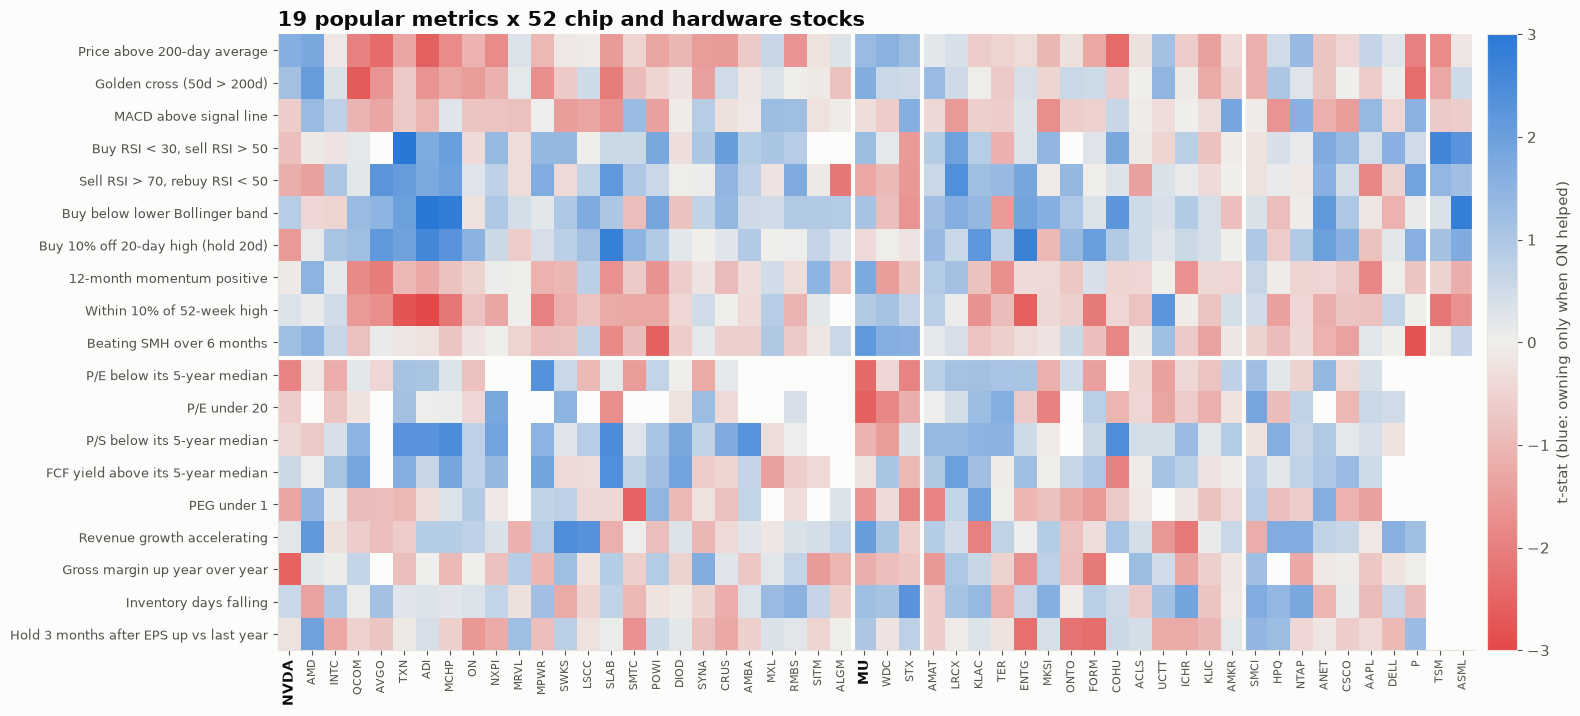

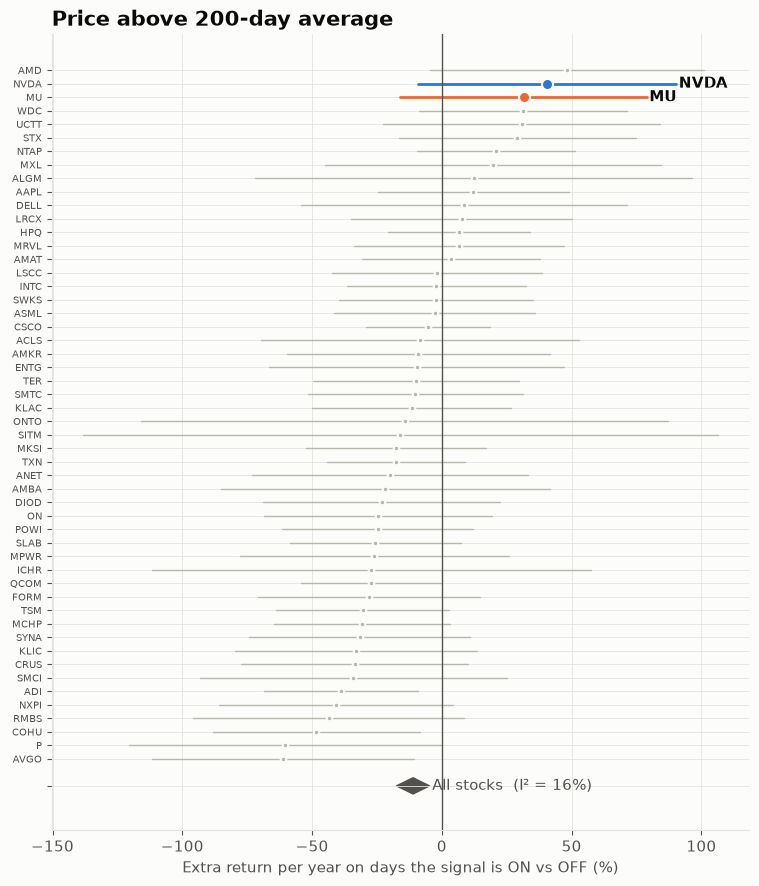

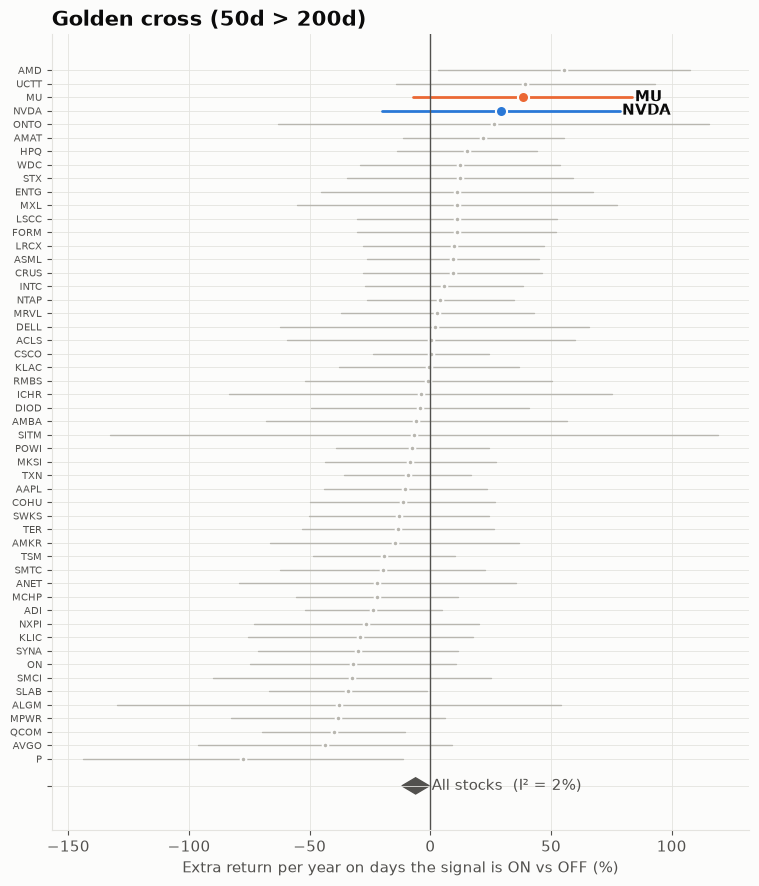

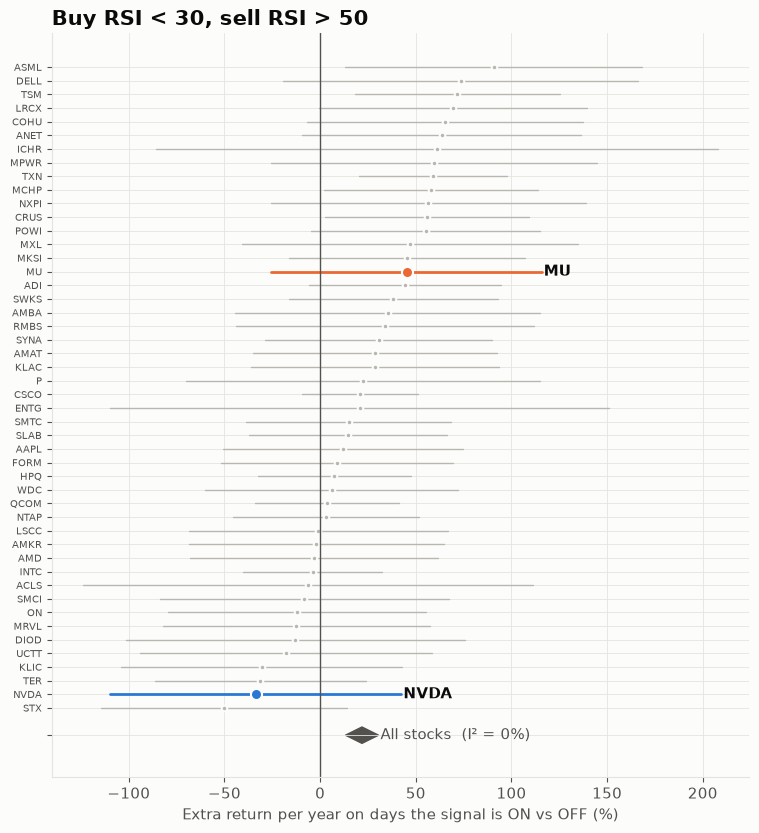

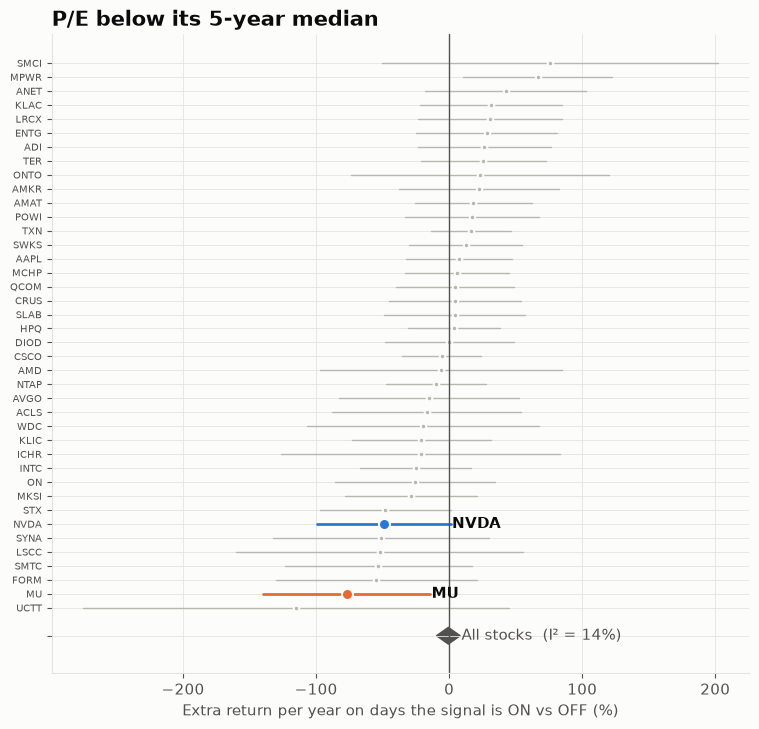

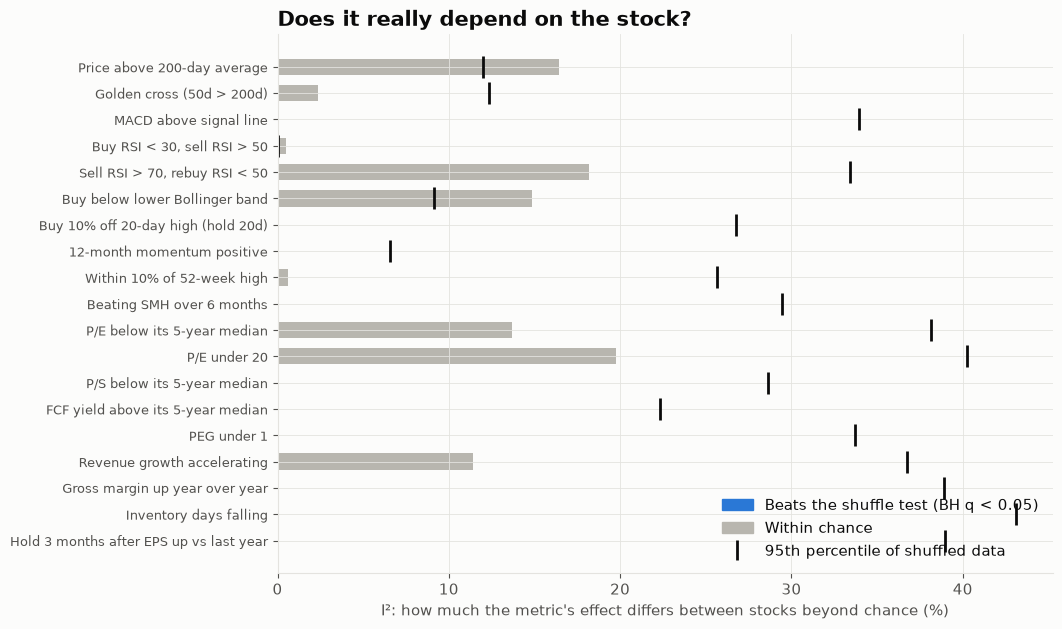

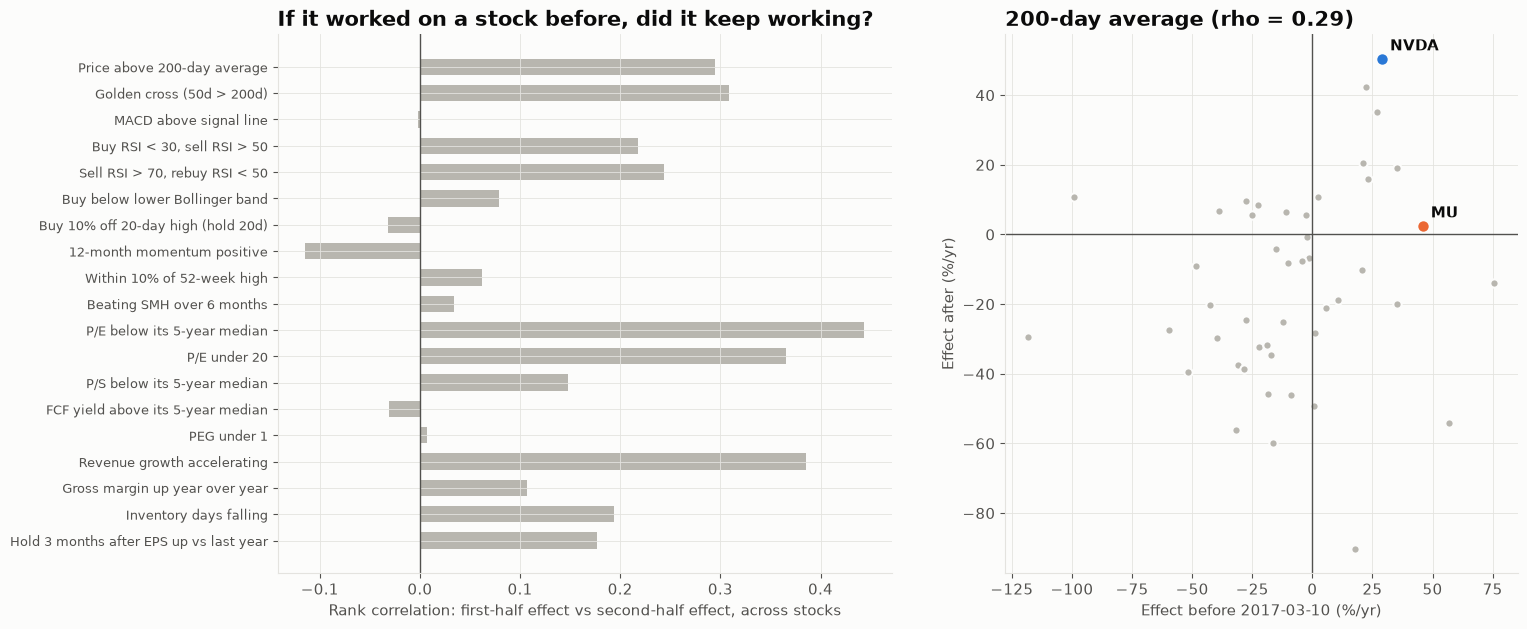

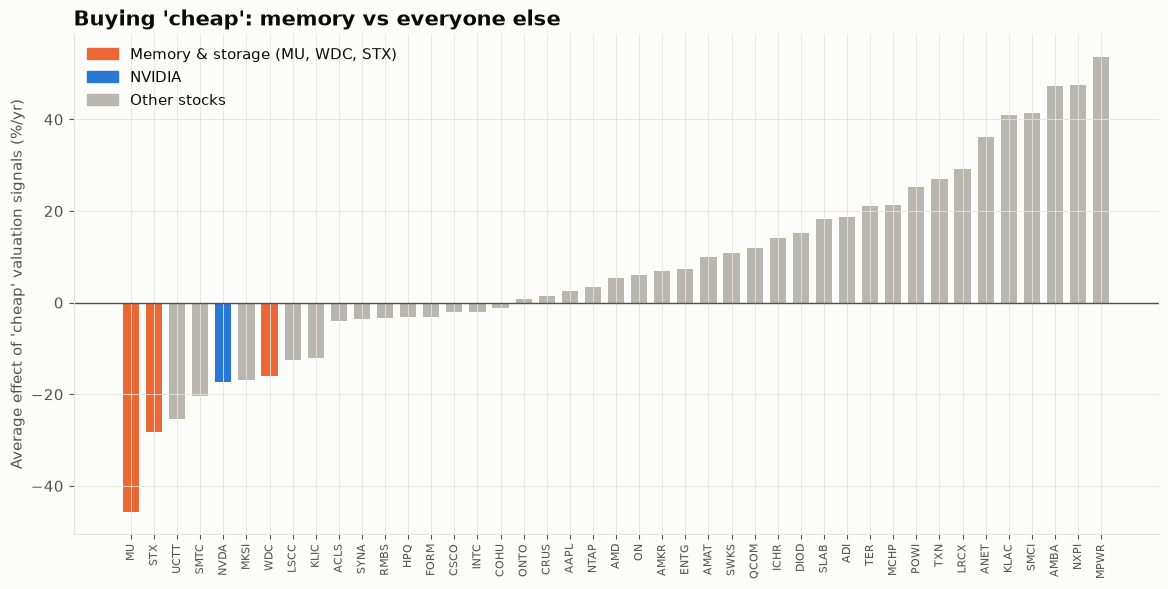

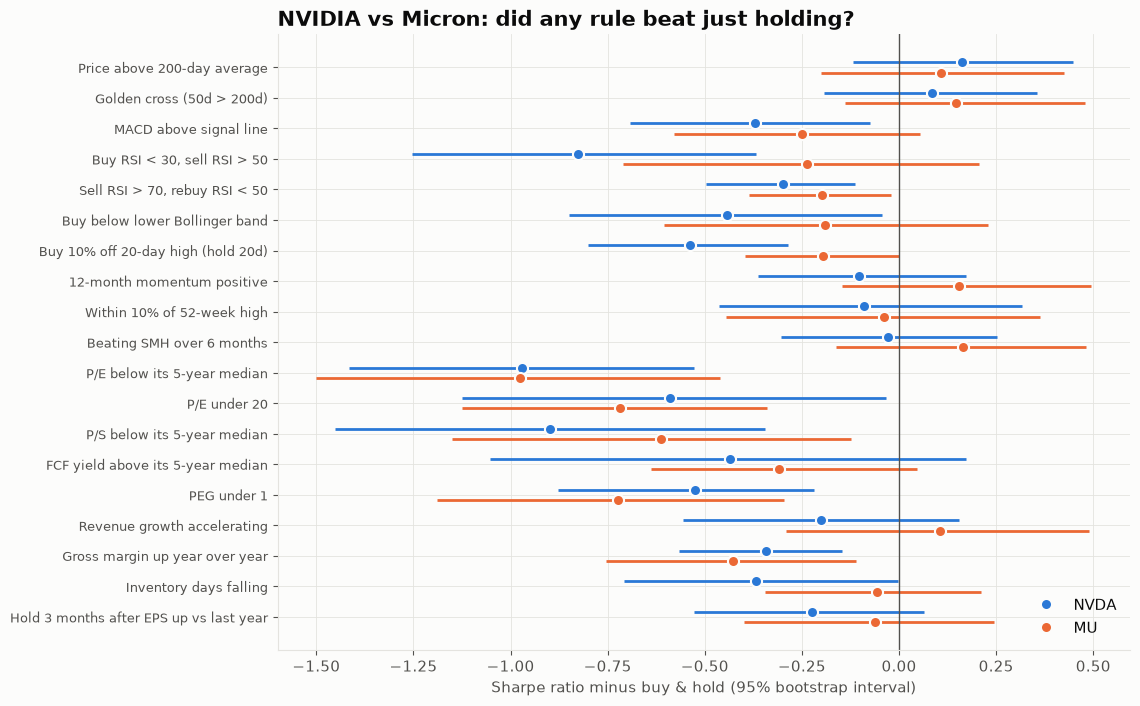

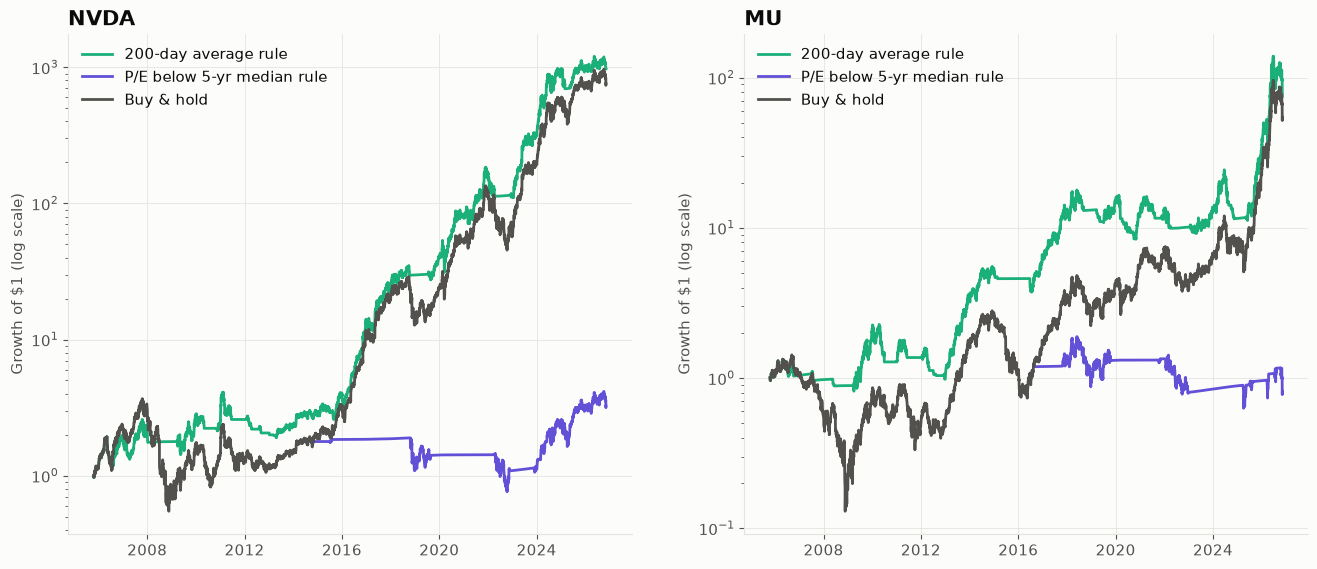

In [30]:
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
NV_C, MU_C, OTHER_C = "#2a78d6", "#eb6834", "#b8b6af"
AQUA, VIOLET = "#1baf7a", "#6250d6"
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
mpl.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11, "axes.titlesize": 15,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})
def save(fig, name):
    fig.savefig(CAM_DIR / name, dpi=200, bbox_inches="tight"); plt.show()
def color_of(t):
    return NV_C if t == "NVDA" else (MU_C if t == "MU" else OTHER_C)

# 01: every metric x every stock
order = [t for g in GROUPS for t in GROUPS[g] if t in TICKERS]
H = EFF.pivot(index="metric", columns="ticker", values="t").reindex(index=METRICS, columns=order)
fig, ax = plt.subplots(figsize=(16, 8))
im = ax.imshow(H.clip(-3, 3).values, cmap=DIV, vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_yticks(range(len(METRICS))); ax.set_yticklabels([LABEL[m] for m in METRICS], fontsize=9)
for lbl in ax.get_xticklabels():
    if lbl.get_text() in FOCUS:
        lbl.set_fontweight("bold"); lbl.set_fontsize(10); lbl.set_color(INK)
ax.grid(False)
x0 = 0
for g in GROUPS:
    n = len([t for t in GROUPS[g] if t in TICKERS]); x0 += n
    ax.axvline(x0 - 0.5, color="#fcfcfb", lw=3)
ax.axhline(len(TECH) - 0.5, color="#fcfcfb", lw=3)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("t-stat (blue: owning only when ON helped)")
ax.set_title(f"19 popular metrics x {len(order)} chip and hardware stocks")
save(fig, "01_heatmap_metric_by_stock.png")

# 02: forest plots
def forest(m, fname=None, show_fig=True):
    sub = EFF[(EFF.metric == m) & EFF.b.notna()].sort_values("b")
    r = META.set_index("metric").loc[m]
    fig, ax = plt.subplots(figsize=(9, max(6, 0.17 * len(sub) + 1.5)))
    y = np.arange(len(sub))
    for yi, row in zip(y, sub.itertuples()):
        c = color_of(row.ticker); lw = 2 if row.ticker in FOCUS else 1
        ax.plot([100 * (row.b - 1.96 * row.se), 100 * (row.b + 1.96 * row.se)], [yi, yi], color=c, lw=lw, solid_capstyle="round")
        ax.plot(100 * row.b, yi, "o", color=c, ms=8 if row.ticker in FOCUS else 4, mec="#fcfcfb", mew=1.5)
        if row.ticker in FOCUS:
            ax.text(100 * (row.b + 1.96 * row.se) + 1, yi, row.ticker, va="center", fontweight="bold", color=INK)
    yp = -2
    ax.fill([100 * (r.mu - 1.96 * r.se_mu), 100 * r.mu, 100 * (r.mu + 1.96 * r.se_mu), 100 * r.mu],
            [yp, yp + 0.6, yp, yp - 0.6], color=INK2)
    ax.text(100 * (r.mu + 1.96 * r.se_mu) + 1, yp, f"All stocks  (I² = {100 * r.I2:.0f}%)", va="center", color=INK2)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(list(y) + [yp]); ax.set_yticklabels(list(sub.ticker) + [""], fontsize=7)
    ax.set_xlabel("Extra return per year on days the signal is ON vs OFF (%)")
    ax.set_title(LABEL[m])
    if fname: fig.savefig(CAM_DIR / fname, dpi=200, bbox_inches="tight")
    plt.show() if show_fig else plt.close(fig)

for i, m in enumerate(METRICS):
    forest(m, f"02_forest_{i:02d}_{m}.png", show_fig=m in ["above_200dma", "golden_cross", "pe_cheap_own", "rsi_oversold"])

# 03: heterogeneity vs the shift null
d = META.set_index("metric").reindex(METRICS)
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(METRICS))[::-1]
real_hit = (d.q_Q < 0.05).values
ax.barh(y, 100 * d.I2, color=[NV_C if h else OTHER_C for h in real_hit], height=0.62)
ax.plot(100 * d.I2_null95, y, "|", color=INK, ms=16, mew=2)
ax.set_yticks(y); ax.set_yticklabels([LABEL[m] for m in METRICS], fontsize=9)
ax.set_xlabel("I²: how much the metric's effect differs between stocks beyond chance (%)")
ax.set_title("Does it really depend on the stock?")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=NV_C, label="Beats the shuffle test (BH q < 0.05)"), Patch(color=OTHER_C, label="Within chance"),
                   Line2D([], [], color=INK, marker="|", ls="", ms=14, mew=2, label="95th percentile of shuffled data")],
          loc="lower right")
save(fig, "03_heterogeneity_vs_null.png")

# 04: persistence
p_ = PERS.set_index("metric").reindex(METRICS)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.barh(y, p_.rho, color=[NV_C if q < 0.05 else OTHER_C for q in p_.q.fillna(1)], height=0.62)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y); ax.set_yticklabels([LABEL[m] for m in METRICS], fontsize=9)
ax.set_xlabel("Rank correlation: first-half effect vs second-half effect, across stocks")
ax.set_title("If it worked on a stock before, did it keep working?")
ax = axes[1]
hh = HALVES["above_200dma"]
for row in hh.itertuples():
    ax.plot(100 * row.b1, 100 * row.b2, "o", color=color_of(row.ticker), ms=9 if row.ticker in FOCUS else 6, mec="#fcfcfb", mew=1.5)
    if row.ticker in FOCUS:
        ax.annotate(row.ticker, (100 * row.b1, 100 * row.b2), xytext=(6, 6), textcoords="offset points", fontweight="bold")
ax.axhline(0, color=INK2, lw=1); ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel(f"Effect before {PERS.set_index('metric').loc['above_200dma', 'split']} (%/yr)")
ax.set_ylabel("Effect after (%/yr)")
ax.set_title(f"200-day average (rho = {p_.loc['above_200dma', 'rho']:.2f})")
save(fig, "04_persistence.png")

# 05: valuation effect by stock
v5 = H4.sort_values("valuation_effect")
fig, ax = plt.subplots(figsize=(14, 6.5))
cols5 = [MU_C if g == "memory_storage" else (NV_C if t == "NVDA" else OTHER_C) for t, g in zip(v5.index, v5.group)]
ax.bar(range(len(v5)), 100 * v5.valuation_effect, color=cols5, width=0.7)
ax.set_xticks(range(len(v5))); ax.set_xticklabels(v5.index, rotation=90, fontsize=8)
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("Average effect of 'cheap' valuation signals (%/yr)")
ax.set_title("Buying 'cheap': memory vs everyone else")
ax.legend(handles=[Patch(color=MU_C, label="Memory & storage (MU, WDC, STX)"), Patch(color=NV_C, label="NVIDIA"),
                   Patch(color=OTHER_C, label="Other stocks")], loc="upper left")
save(fig, "05_valuation_memory_vs_rest.png")

# 06: NVDA vs MU, Sharpe vs buy & hold
fig, ax = plt.subplots(figsize=(11, 8))
for t, c, off in [("NVDA", NV_C, 0.17), ("MU", MU_C, -0.17)]:
    s6 = SC[SC.ticker == t].set_index("metric").reindex(METRICS)
    yy = np.arange(len(METRICS))[::-1] + off
    ax.hlines(yy, s6.d_sharpe_lo, s6.d_sharpe_hi, color=c, lw=2)
    ax.plot(s6.d_sharpe, yy, "o", color=c, ms=8, mec="#fcfcfb", mew=1.5, label=t)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(np.arange(len(METRICS))[::-1]); ax.set_yticklabels([LABEL[m] for m in METRICS], fontsize=9)
ax.set_xlabel("Sharpe ratio minus buy & hold (95% bootstrap interval)")
ax.set_title("NVIDIA vs Micron: did any rule beat just holding?")
ax.legend(loc="lower right")
save(fig, "06_nvda_mu_sharpe_vs_hold.png")

# 07: equity curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=False)
for ax, t in zip(axes, FOCUS):
    bh_curve = (1 + strategy(t, "above_200dma")[1]).cumprod()
    for m, c, lab in [("above_200dma", AQUA, "200-day average rule"), ("pe_cheap_own", VIOLET, "P/E below 5-yr median rule")]:
        out = strategy(t, m)
        if out is None: continue
        s = out[0]
        start_level = bh_curve.asof(s.index[0]) if s.index[0] > bh_curve.index[0] else 1.0
        ax.plot(start_level * (1 + s).cumprod(), color=c, lw=2, label=lab)
    ax.plot(bh_curve, color=INK2, lw=2, label="Buy & hold")
    ax.set_yscale("log"); ax.set_title(t); ax.set_ylabel("Growth of $1 (log scale)")
    ax.legend(loc="upper left")
save(fig, "07_equity_curves_nvda_mu.png")

## 11b. Camera figures for Part B

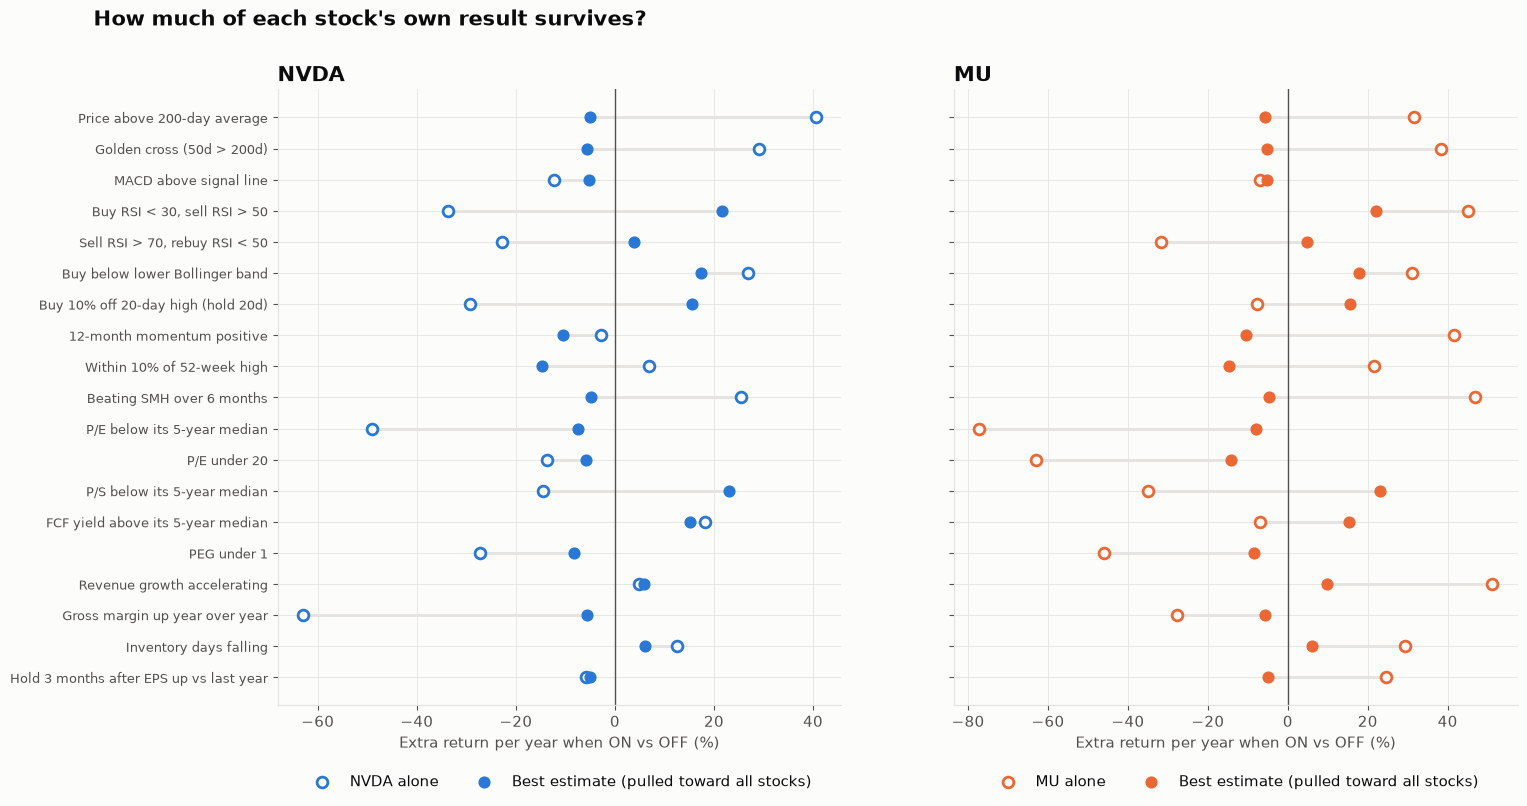

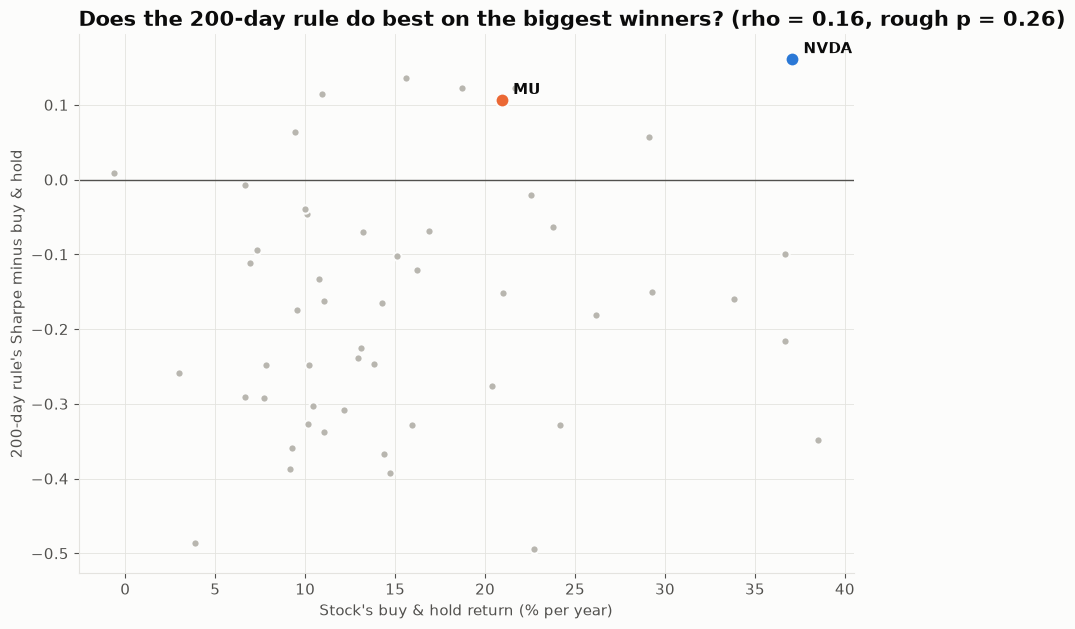

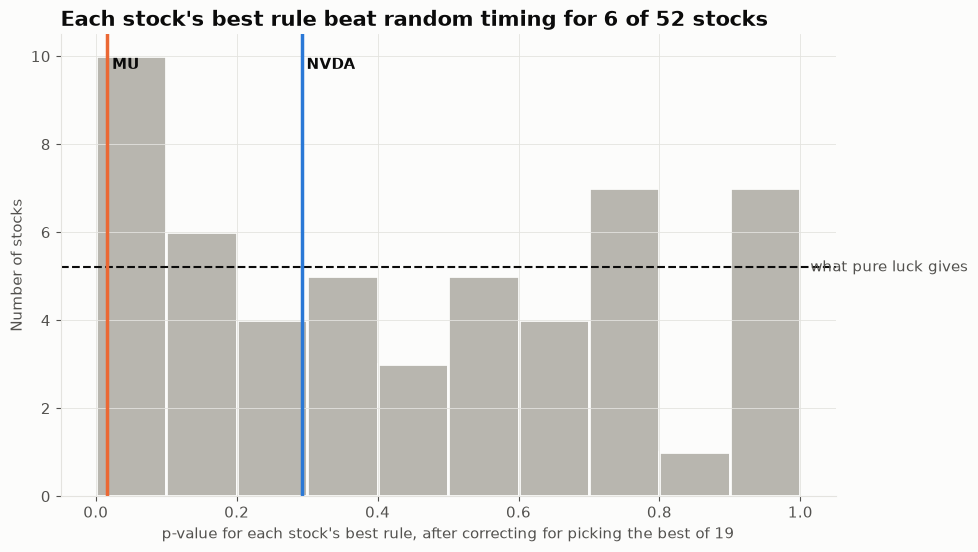

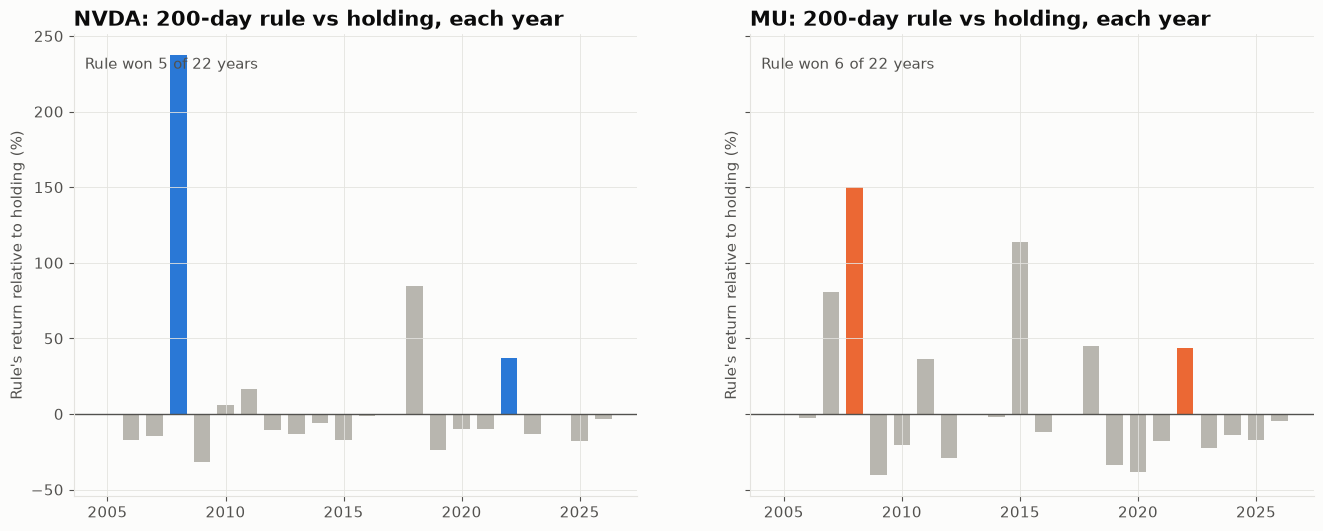

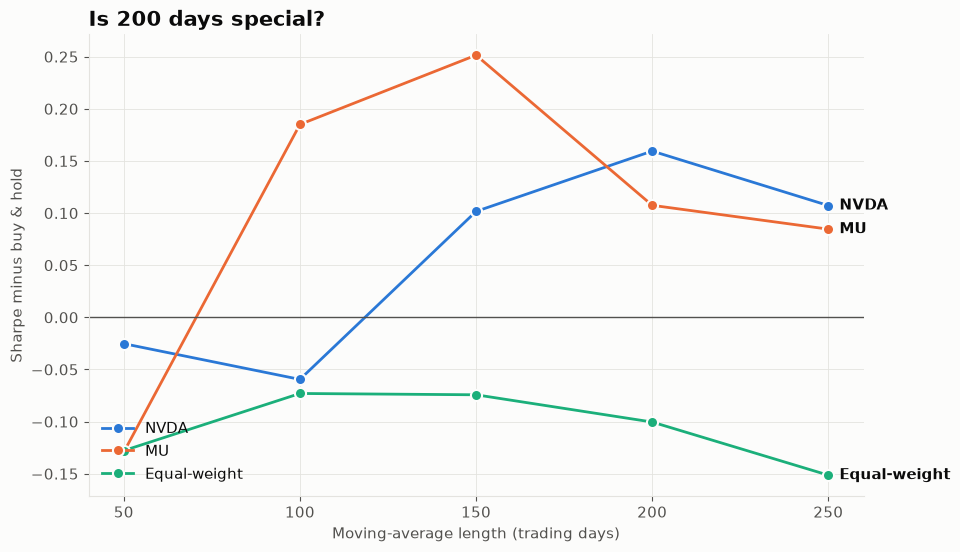

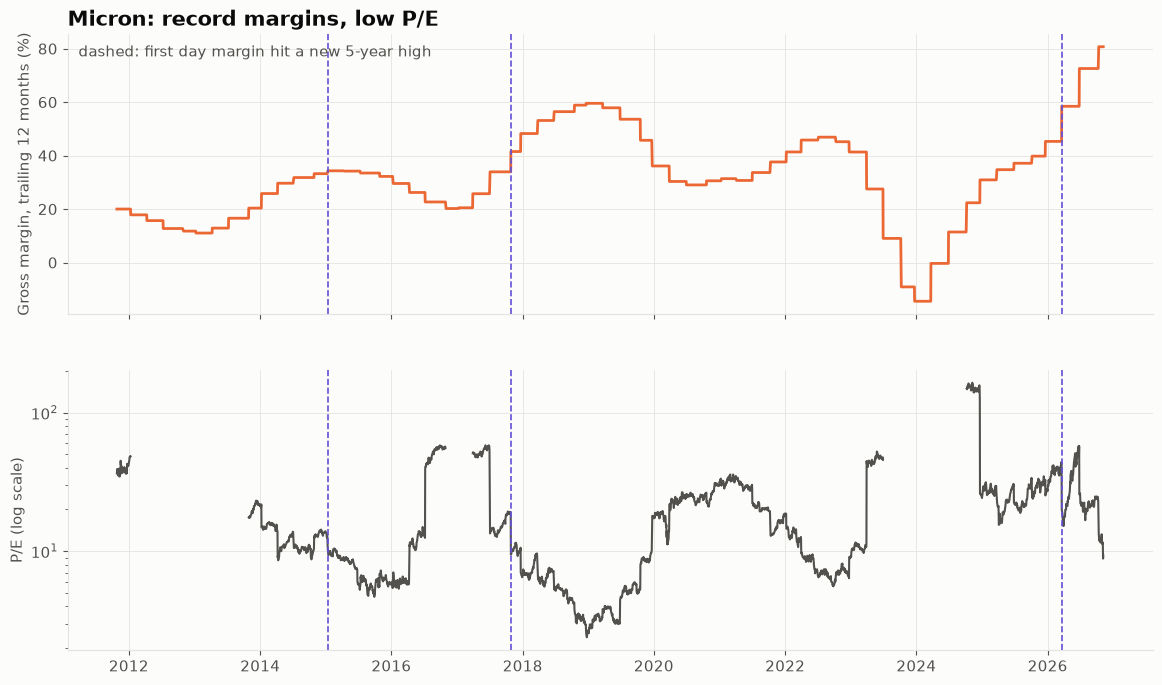

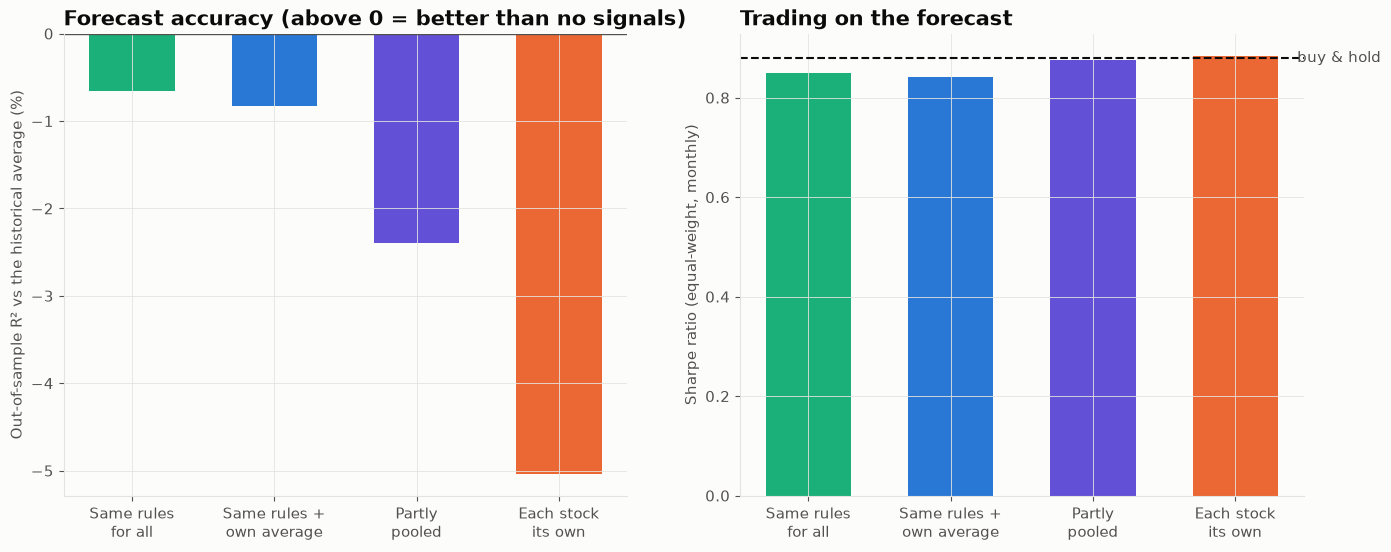

In [31]:
# 08: raw vs shrunk effects for NVDA and MU
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
yy = np.arange(len(METRICS))[::-1]
for ax, t, c in zip(axes, FOCUS, [NV_C, MU_C]):
    sub = SHR[SHR.ticker == t].set_index("metric").reindex(METRICS)
    for yi, (raw_, shr_) in zip(yy, zip(100 * sub.raw, 100 * sub.shrunk)):
        if np.isfinite(raw_):
            ax.plot([raw_, shr_], [yi, yi], color=GRID, lw=2, zorder=1)
    ax.scatter(100 * sub.raw, yy, s=60, facecolors="#fcfcfb", edgecolors=c, linewidths=2, zorder=2, label=f"{t} alone")
    ax.scatter(100 * sub.shrunk, yy, s=60, color=c, zorder=3, label="Best estimate (pulled toward all stocks)")
    ax.axvline(0, color=INK2, lw=1)
    ax.set_title(t); ax.set_xlabel("Extra return per year when ON vs OFF (%)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
axes[0].set_yticks(yy); axes[0].set_yticklabels([LABEL[m] for m in METRICS], fontsize=9)
fig.suptitle("How much of each stock's own result survives?", x=0.01, ha="left", fontweight="bold", fontsize=15)
save(fig, "08_shrinkage_nvda_mu.png")

# 09: selection bias
sub = EFF[(EFF.metric == "above_200dma") & EFF.b.notna()]
fig, ax = plt.subplots(figsize=(10, 7))
for r in sub.itertuples():
    big = r.ticker in FOCUS
    ax.plot(100 * r.bh_cagr, r.d_sharpe, "o", color=color_of(r.ticker), ms=10 if big else 6, mec="#fcfcfb", mew=1.5, zorder=3 if big else 2)
    if big:
        ax.annotate(r.ticker, (100 * r.bh_cagr, r.d_sharpe), xytext=(8, 4), textcoords="offset points", fontweight="bold")
ax.axhline(0, color=INK2, lw=1)
rr = SEL.set_index("metric").loc["above_200dma"]
ax.set_xlabel("Stock's buy & hold return (% per year)")
ax.set_ylabel("200-day rule's Sharpe minus buy & hold")
ax.set_title(f"Does the 200-day rule do best on the biggest winners? (rho = {rr.rho_dsharpe:.2f}, rough p = {rr.p_dsharpe:.2f})")
save(fig, "09_selection_bias_200dma.png")

# 10: best rule per stock vs random timing
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 1, 11)
ax.hist(BEST.p_best_of_all, bins=bins, color=OTHER_C, edgecolor="#fcfcfb", linewidth=2)
ax.axhline(len(BEST) / 10, color=INK, lw=1.5, ls="--")
ax.text(1.0, len(BEST) / 10, "  what pure luck gives", va="center", ha="left", color=INK2)
for t, c in zip(FOCUS, [NV_C, MU_C]):
    pv = BEST.set_index("ticker").loc[t, "p_best_of_all"]
    ax.axvline(pv, color=c, lw=2.5)
    ax.text(pv, ax.get_ylim()[1] * 0.95, f" {t}", color=INK, fontweight="bold", va="top")
ax.set_xlabel("p-value for each stock's best rule, after correcting for picking the best of 19")
ax.set_ylabel("Number of stocks")
ax.set_title(f"Each stock's best rule beat random timing for {BEST_SUM['n_sig']} of {BEST_SUM['n']} stocks")
save(fig, "10_best_rule_vs_luck.png")

# 11: year-by-year excess for the 200-day rule
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, t, c in zip(axes, FOCUS, [NV_C, MU_C]):
    yv = YEARLY[(t, "above_200dma")]
    ex = 100 * (np.exp(yv.log_excess) - 1)
    ax.bar(yv.index, ex, color=[c if y in CRASH_YEARS else OTHER_C for y in yv.index], width=0.7)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_title(f"{t}: 200-day rule vs holding, each year")
    ax.set_ylabel("Rule's return relative to holding (%)")
    won = int((yv.log_excess > 0).sum())
    ax.text(0.02, 0.95, f"Rule won {won} of {len(yv)} years", transform=ax.transAxes, va="top", color=INK2)
save(fig, "11_year_by_year_200dma.png")

# 12: lookback sensitivity
fig, ax = plt.subplots(figsize=(10, 6))
for who, c in [("NVDA", NV_C), ("MU", MU_C), ("Equal-weight", AQUA)]:
    d = LB[LB.who == who]
    ax.plot(d.lookback, d.d_sharpe, "-o", color=c, lw=2, ms=8, mec="#fcfcfb", mew=1.5, label=who)
    ax.annotate(who, (d.lookback.iloc[-1], d.d_sharpe.iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontweight="bold")
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(LOOKBACKS)
ax.set_xlabel("Moving-average length (trading days)")
ax.set_ylabel("Sharpe minus buy & hold")
ax.set_title("Is 200 days special?")
ax.legend(loc="lower left")
save(fig, "12_lookback_sensitivity.png")

# 13: Micron gross margin and P/E with new-high episodes
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
cs = CASE_SERIES["MU"]
axes[0].plot(cs["gm"], color=MU_C, lw=2)
axes[0].set_ylabel("Gross margin, trailing 12 months (%)")
axes[0].set_title("Micron: record margins, low P/E")
axes[1].plot(cs["pe"], color=INK2, lw=1.5)
axes[1].set_yscale("log"); axes[1].set_ylabel("P/E (log scale)")
for ax in axes:
    for sd in cs["starts"]:
        ax.axvline(sd, color=VIOLET, lw=1.2, ls="--")
axes[0].text(0.01, 0.92, "dashed: first day margin hit a new 5-year high", transform=axes[0].transAxes, color=INK2)
save(fig, "13_micron_margin_pe.png")

# 14: model comparison
order4 = ["pooled", "pooled_stock_avg", "partial", "stock"]
d = MODELS_T[MODELS_T.features == "technical_10"].set_index("model").reindex(order4)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
names = ["Same rules\nfor all", "Same rules +\nown average", "Partly\npooled", "Each stock\nits own"]
cols4 = [AQUA, NV_C, VIOLET, MU_C]
axes[0].bar(names, d.oos_r2_vs_mean_pct, color=cols4, width=0.6)
axes[0].axhline(0, color=INK2, lw=1)
axes[0].set_ylabel("Out-of-sample R² vs the historical average (%)")
axes[0].set_title("Forecast accuracy (above 0 = better than no signals)")
axes[1].bar(names, d.ew_sharpe, color=cols4, width=0.6)
axes[1].axhline(d.ew_bh_sharpe.iloc[0], color=INK, lw=1.5, ls="--")
axes[1].text(3.4, d.ew_bh_sharpe.iloc[0], " buy & hold", va="center", color=INK2)
axes[1].set_ylabel("Sharpe ratio (equal-weight, monthly)")
axes[1].set_title("Trading on the forecast")
save(fig, "14_pooled_vs_stock_models.png")

## 11c. Camera figures for Part C

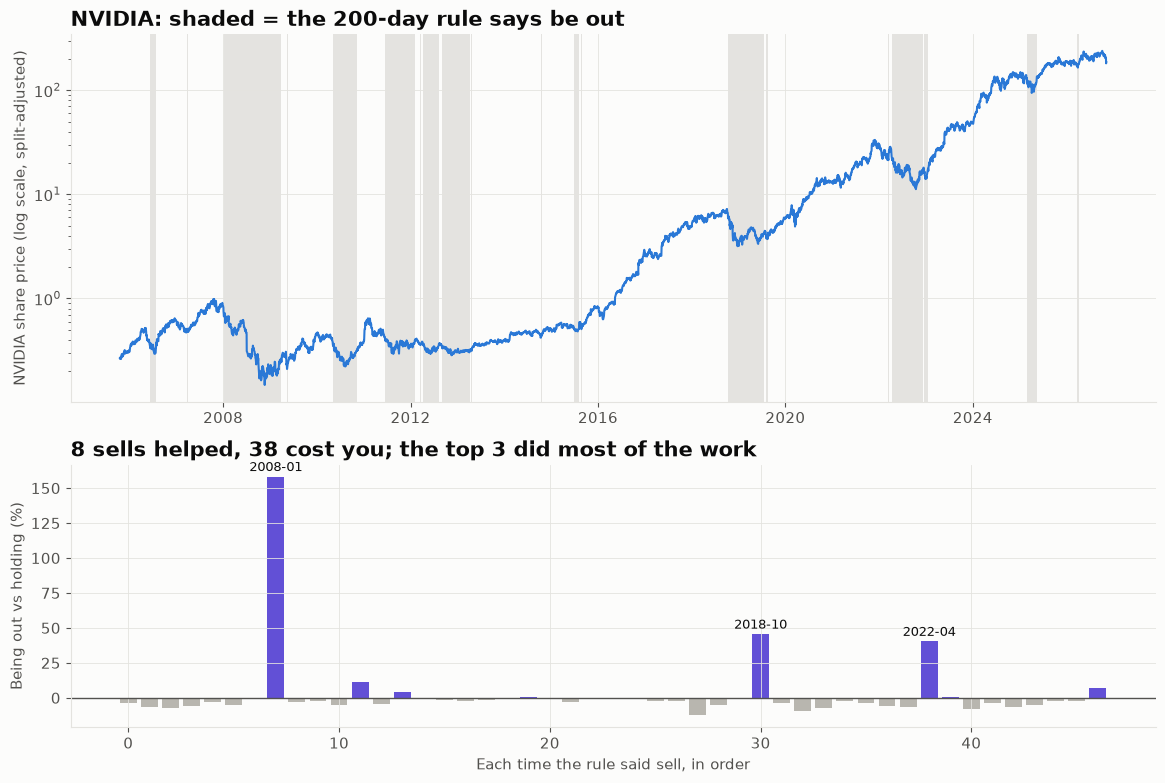

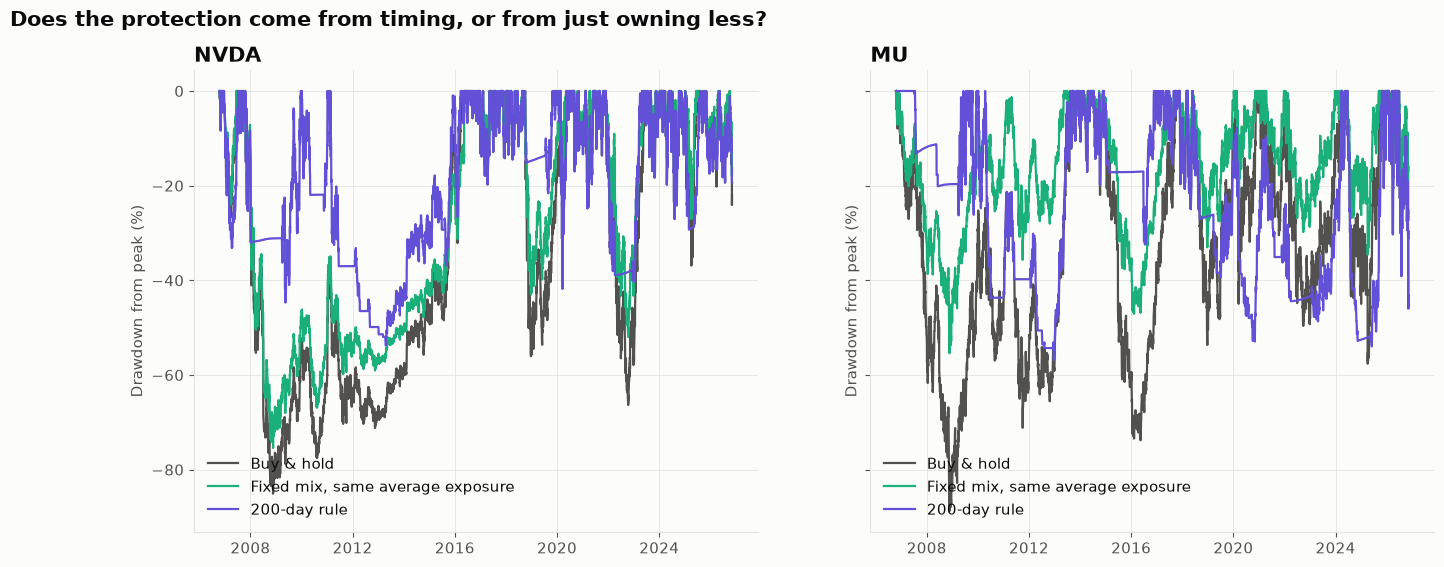

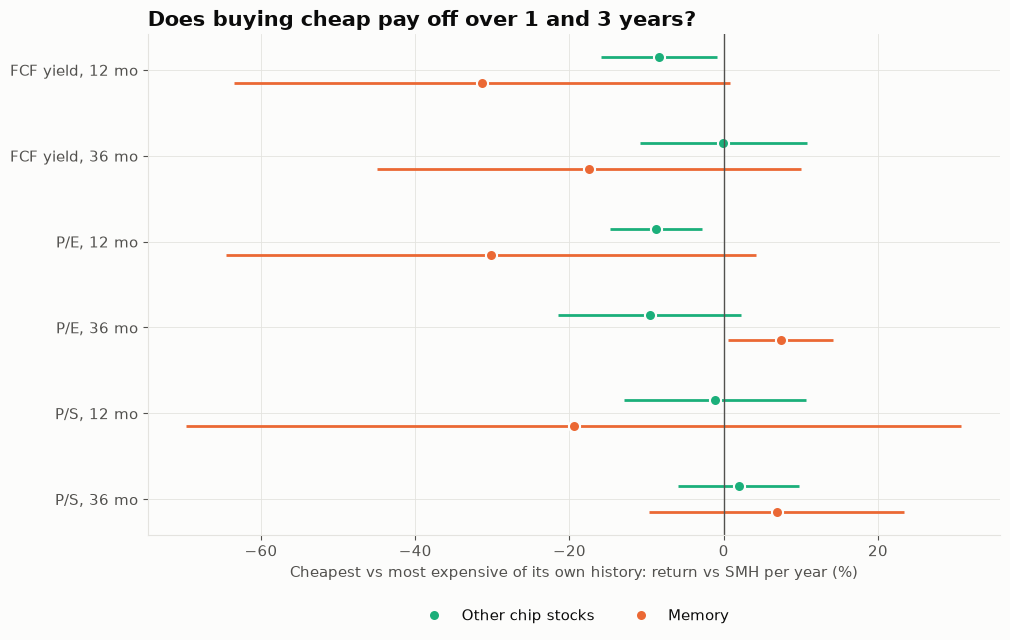

In [32]:
# 15: NVDA price with the 200-day rule's OFF periods, and what each one did
fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={"height_ratios": [1.4, 1]})
ax = axes[0]
_, d15 = off_episodes("NVDA", "above_200dma")
ax.plot(d15.c, color=NV_C, lw=1.5)
ax.set_yscale("log"); ax.set_ylabel("NVIDIA share price (log scale, split-adjusted)")
e15 = EPIS[(EPIS.ticker == "NVDA") & (EPIS.metric == "above_200dma")]
for r in e15.itertuples():
    ax.axvspan(pd.Timestamp(r.start), pd.Timestamp(r.end), color=OTHER_C, alpha=0.35, lw=0)
ax.set_title("NVIDIA: shaded = the 200-day rule says be out")
ax = axes[1]
c15 = e15[e15.status != "initial"].reset_index(drop=True)
gain = 100 * (np.exp(c15.log_benefit) - 1)
ax.bar(range(len(c15)), gain, color=[VIOLET if g > 0 else OTHER_C for g in gain], width=0.8)
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("Being out vs holding (%)")
ax.set_xlabel("Each time the rule said sell, in order")
s15 = EPSUM[(EPSUM.ticker == "NVDA") & (EPSUM.metric == "above_200dma")].iloc[0]
ax.set_title(f"{s15.helped} sells helped, {s15.hurt} cost you; the top 3 did most of the work")
for i in gain.nlargest(3).index:
    ax.annotate(str(c15.loc[i, "start"])[:7], (i, gain[i]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
save(fig, "15_nvda_off_episodes.png")

# 16: drawdowns, rule vs hold vs a fixed mix with the same average exposure
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, t in zip(axes, FOCUS):
    cv = ALLOC_CURVES[(t, "above_200dma")]
    for name, c, lab in [("hold", INK2, "Buy & hold"), ("fixed mix, same avg exposure (real time)", AQUA, "Fixed mix, same average exposure"),
                         ("rule", VIOLET, "200-day rule")]:
        w = (1 + cv[name]).cumprod()
        ax.plot(100 * (w / w.cummax() - 1), color=c, lw=1.6, label=lab)
    ax.set_title(t); ax.set_ylabel("Drawdown from peak (%)")
    ax.legend(loc="lower left")
fig.suptitle("Does the protection come from timing, or from just owning less?", x=0.01, ha="left", fontweight="bold", fontsize=15)
save(fig, "16_drawdowns_rule_vs_fixed_mix.png")

# 17: valuation over 12 and 36 months, vs SMH
d17 = VALH[VALH.outcome == "fwd_vs_smh"].copy()
d17["label"] = d17.metric + ", " + d17.horizon_m.astype(str) + " mo"
labels = list(dict.fromkeys(d17.sort_values(["metric", "horizon_m"]).label))
fig, ax = plt.subplots(figsize=(11, 6.5))
y0 = np.arange(len(labels))[::-1]
for grp, c, off in [("other chip stocks", AQUA, 0.15), ("memory", MU_C, -0.15)]:
    g = d17[d17.group == grp].set_index("label").reindex(labels)
    k = 12 / g.horizon_m
    ax.hlines(y0 + off, 100 * k * (g.slope - 1.96 * g.se), 100 * k * (g.slope + 1.96 * g.se), color=c, lw=2)
    ax.plot(100 * k * g.slope, y0 + off, "o", color=c, ms=8, mec="#fcfcfb", mew=1.5, label=grp.capitalize())
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y0); ax.set_yticklabels(labels)
ax.set_xlabel("Cheapest vs most expensive of its own history: return vs SMH per year (%)")
ax.set_title("Does buying cheap pay off over 1 and 3 years?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
save(fig, "17_valuation_long_horizon.png")

## 11d. Camera figure for Part D

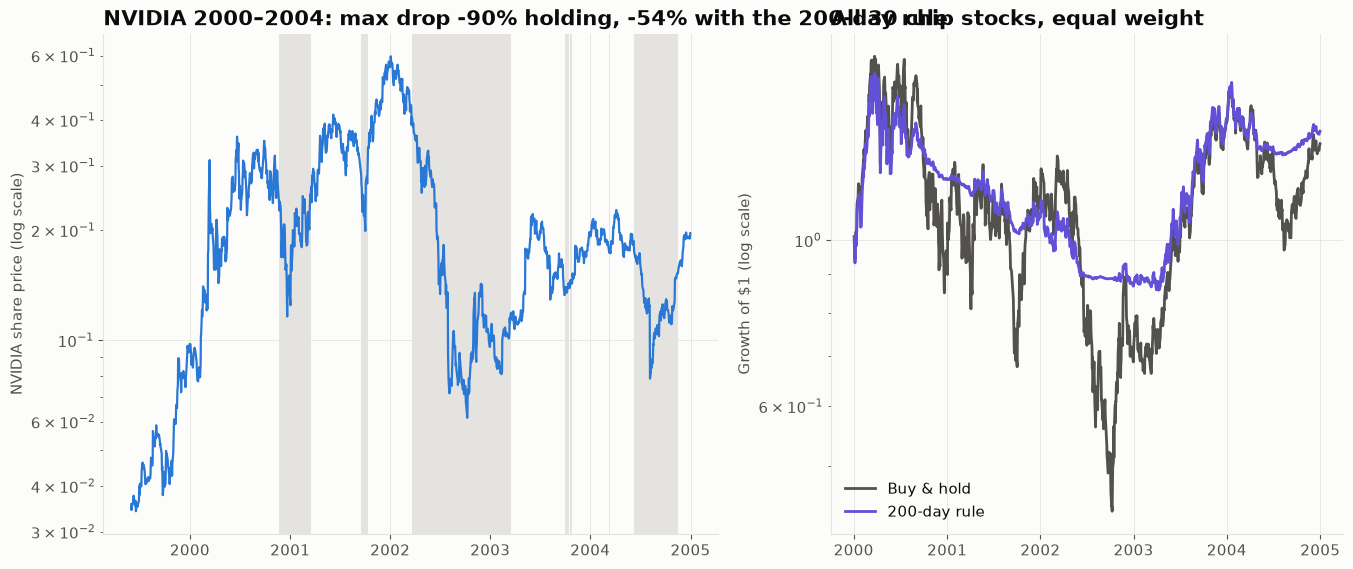

In [33]:
# 18: the dot-com crash, out of sample
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
c18 = D_CLOSE["NVDA"].loc["1999-06-01":DOT_END]
ax.plot(c18, color=NV_C, lw=1.6)
ax.set_yscale("log"); ax.set_ylabel("NVIDIA share price (log scale)")
p18 = D_POS["NVDA"]["above_200dma"].loc[DOT_START:DOT_END]
off = (p18 == 0)
grp = (off != off.shift()).cumsum()
for _, seg in p18[off].groupby(grp[off]):
    ax.axvspan(seg.index[0], seg.index[-1], color=OTHER_C, alpha=0.35, lw=0)
r18 = DOT[(DOT.ticker == "NVDA") & (DOT.metric == "above_200dma")].iloc[0]
ax.set_title(f"NVIDIA 2000–2004: max drop {100 * r18.bh_max_dd:.0f}% holding, {100 * r18.max_dd:.0f}% with the 200-day rule")
ax = axes[1]
s, b = DOT_EW_CURVES["above_200dma"]
ax.plot((1 + b).cumprod(), color=INK2, lw=2, label="Buy & hold")
ax.plot((1 + s).cumprod(), color=VIOLET, lw=2, label="200-day rule")
ax.set_yscale("log"); ax.set_ylabel("Growth of $1 (log scale)")
ax.set_title(f"All {len(D_TICK)} chip stocks, equal weight")
ax.legend(loc="lower left")
save(fig, "18_dotcom_out_of_sample.png")

## 12. Checks, results file and recording brief

In [34]:
check("Every metric has at least 20 usable stocks", (META.k >= 20).all(),
      META.loc[META.k < 20, ["metric", "k"]].to_dict("records"))
check("NVDA and MU have every technical metric", EFF[EFF.ticker.isin(FOCUS) & EFF.metric.isin(TECH)].b.notna().all())
check("NVDA and MU have at least 7 fundamental metrics",
      all(EFF[(EFF.ticker == t) & EFF.metric.isin(FUND)].b.notna().sum() >= 7 for t in FOCUS),
      {t: int(EFF[(EFF.ticker == t) & EFF.metric.isin(FUND)].b.notna().sum()) for t in FOCUS})
check("Shift null has no failed draws", all(np.isfinite(NULL[m]["Q"]).mean() > 0.99 for m in METRICS))
check("Memory group has all 3 stocks in H4", len(mem) == 3, mem)
check("Pick-your-metric test has 30+ stocks", len(PICK) >= 30, len(PICK))
check("B1 shrinkage weights between 0 and 1", SHR.weight_own.between(0, 1).all())
check("B3 random-timing test covers 45+ stocks", len(BEST) >= 45, len(BEST))
check("C1 every allocation variant evaluated on the same dates", ALLOC.groupby(["who", "metric"]).start.nunique().eq(1).all())
check("C3 valuation panel covers 40+ stocks", VP.ticker.nunique() >= 40, VP.ticker.nunique())
check("B4 forecasts cover 40+ stocks", FC["technical_10"].ticker.nunique() >= 40, FC["technical_10"].ticker.nunique())
check("B6 200-day lookback close to section 9 for NVDA (within 0.10 Sharpe; B6 starts ~50 days later)",
      abs(LB[(LB.who == "NVDA") & (LB.lookback == 200)].d_sharpe.iloc[0] - SC[(SC.ticker == "NVDA") & (SC.metric == "above_200dma")].d_sharpe.iloc[0]) < 0.10)
CHK = pd.DataFrame(CHECKS)
CHK.to_csv(OUT_DIR / "checks.csv", index=False)
print(f"\n{CHK.passed.sum()} of {len(CHK)} checks passed")

def f(x, n=2): return None if x is None or (isinstance(x, float) and not np.isfinite(x)) else round(float(x), n)
RESULTS = dict(
    run_date=str(pd.Timestamp.today().date()), data_through=str(CAL[-1].date()), rf_source=RF_SRC,
    n_stocks=len(TICKERS), n_metrics=len(METRICS), cost_bps=COST_BPS,
    meta=META.drop(columns=["label"]).round(5).to_dict("records"),
    persistence=dict(rows=PERS.drop(columns=["label"]).astype({"split": str}).round(4).to_dict("records"),
                     mean_rho=f(obs_mean, 4), p_mean_joint=f(p_mean, 4), p_mean_v1=f(p_mean_v1, 4),
                     mean_rho_vol_scaled=f(obs_mean_s, 4), p_mean_vol_scaled=f(p_mean_s, 4)),
    pick_your_metric={k: (f(v, 4) if isinstance(v, (float, np.floating)) else v) for k, v in PICK_SUM.items()},
    h4={k: (f(v, 4) if isinstance(v, (float, np.floating)) else v) for k, v in H4_SUM.items()},
    scorecard=SC.astype({"since": str}).round(4).to_dict("records"),
    portfolios=PORTS.astype({"since": str}).drop(columns=["label"]).round(4).to_dict("records"),
    current=CUR.round(3).to_dict("records"), since_huang_report=EV.astype(str).to_dict("records"),
    gone=GONE, renamed=RENAMED,
    b1_shrinkage=SHR[SHR.ticker.isin(FOCUS)].round(5).to_dict("records"), b1_median_weight=SHR_W.round(4).to_dict(),
    b2_selection=SEL.round(4).to_dict("records"), b2_summary=SEL_SUM,
    b3_best_rule=BEST.round(4).to_dict("records"), b3_summary=BEST_SUM,
    b3_focus={t: v.round(4).to_dict("records") for t, v in BEST_FOCUS.items()},
    b4_models=MODELS_T.round(5).to_dict("records"), b4_focus=MODELS_F.round(4).to_dict("records"),
    b4_pooled_coef=POOLED_COEF.round(4).to_dict(),
    b5_year_by_year=YR.round(4).to_dict("records"), b6_lookbacks=LB.round(4).to_dict("records"),
    b7_costs=COST.round(4).to_dict("records"), b8_episodes=CASE.astype(str).to_dict("records"), b8_summary=CASE_SUM,
    c0_delay=LAG.round(4).to_dict("records"), c0_delay_pooled=LAGP.round(5).to_dict("records"),
    c1_alloc=ALLOC.astype({"start": str}).round(4).to_dict("records"),
    c2_summary=EPSUM.round(4).to_dict("records"), c2_episodes=EPIS.astype({"start": str, "end": str}).round(4).to_dict("records"),
    c3_valuation=VALH.round(4).to_dict("records"), c3_focus=VALF.round(4).to_dict("records"),
    d1_dotcom=DOT.round(4).to_dict("records"), d1_dotcom_ew=DOT_EW.round(4).to_dict("records"), d1_summary=DOT_SUM,
    checks=CHECKS)
(OUT_DIR / "results.json").write_text(json.dumps(RESULTS, indent=1, default=str))

L = []
P = lambda s="": L.append(s)
pct = lambda x: f"{100 * x:+.1f}%"
P(f"RECORDING BRIEF  (data through {CAL[-1].date()}, {len(TICKERS)} stocks, {len(METRICS)} metrics, {COST_BPS} bps per switch)")
P("\n1) THE HOOK: what each metric says about NVIDIA and Micron right now")
for r in CUR.itertuples():
    P(f"   {r.label:38s} NVDA {r.NVDA_signal:4s} | MU {r.MU_signal:4s}")
for t in FOCUS:
    s_ = SC[(SC.ticker == t) & SC.b.notna()]
    P(f"\n2) {t}: which rules beat buy & hold on Sharpe (95% interval above 0)?")
    beat = s_[s_.d_sharpe_lo > 0]
    P("   " + (", ".join(f"{r.label} ({r.d_sharpe:+.2f})" for r in beat.itertuples()) if len(beat) else "none"))
    P(f"   Effects with q < 0.05 among this stock's 19: {int((s_.q_effect < 0.05).sum())}")
    best = s_.sort_values("d_sharpe").iloc[-1]
    P(f"   Best by Sharpe: {best['label']}: Sharpe {best['sharpe']:.2f} vs {best['bh_sharpe']:.2f} hold, "
      f"CAGR {pct(best['cagr'])} vs {pct(best['bh_cagr'])}, max DD {pct(best['max_dd'])} vs {pct(best['bh_max_dd'])}, "
      f"timing alpha vs holding {t} {pct(best['timing_alpha'])} (t {best['timing_alpha_t']:.1f})")
    dd = s_[s_.metric.isin(["above_200dma", "golden_cross"])]
    for r in dd.itertuples():
        P(f"   {r.label}: max drawdown {pct(r.max_dd)} vs {pct(r.bh_max_dd)} holding; CAGR {pct(r.cagr)} vs {pct(r.bh_cagr)}")
P("\n3) ACROSS ALL STOCKS: does any metric work at all? (naive z treats stocks as independent; p uses the shift test)")
for r in META.sort_values("z", ascending=False).itertuples():
    P(f"   {r.label:38s} pooled {pct(r.mu)}/yr  naive z {r.z:+.2f}  honest p {r.p_mu_shift:.3f}  q {r.q_mu:.3f}")
P("\n4) DOES IT DEPEND ON THE STOCK? (I² vs shuffled data)")
for r in META.sort_values("I2", ascending=False).itertuples():
    P(f"   {r.label:38s} I² {100 * r.I2:4.0f}%  (shuffled 95th pct {100 * r.I2_null95:4.0f}%)  q {r.q_Q:.3f}")
P("\n5) CAN YOU KNOW IN ADVANCE?")
P(f"   Average first-half vs second-half rho across metrics: {obs_mean:.2f} (joint p = {p_mean:.3f}; v1's p = {p_mean_v1:.4f})")
P(f"   Same with volatility-scaled effects: rho {obs_mean_s:.2f} (joint p = {p_mean_s:.3f})")
P(f"   Metrics with persistence q < 0.05: {int((PERS.q < 0.05).sum())} of {len(PERS)}")
P(f"   Pick each stock's best technical rule before {PICK_SPLIT}: after, it beat buy & hold for "
  f"{100 * PICK_SUM['share_best_beats_bh']:.0f}% of {PICK_SUM['n']} stocks; Sharpe vs hold {PICK_SUM['mean_best_minus_bh']:+.2f}; "
  f"vs a random rule {PICK_SUM['mean_best_minus_avg']:+.2f} (p {PICK_SUM['p_best_vs_avg']:.3f})")
P(f"   One rule for everyone, biggest pre-{PICK_SPLIT[:4]} effect ({LABEL[PICK_SUM['one_size_metric']]}): "
  f"Sharpe vs hold {PICK_SUM['mean_onesize_minus_bh']:+.2f}, beat hold for {100 * PICK_SUM['share_onesize_beats_bh']:.0f}%")
P(f"   One rule for everyone, best pre-{PICK_SPLIT[:4]} Sharpe gain ({LABEL[PICK_SUM['one_size_sharpe_metric']]}): "
  f"Sharpe vs hold {PICK_SUM['mean_onesize_sh_minus_bh']:+.2f}, beat hold for {100 * PICK_SUM['share_onesize_sh_beats_bh']:.0f}%; "
  f"stock-specific pick minus this {PICK_SUM['mean_best_minus_onesize_sh']:+.2f} (p {PICK_SUM['p_best_vs_onesize_sh']:.3f})")
for r in PICK[PICK.ticker.isin(FOCUS)].itertuples():
    P(f"   {r.ticker}: would have picked {LABEL[r.best_before]}; after: Sharpe {r.sharpe_after_best:.2f} vs hold {r.sharpe_after_bh:.2f}")
P("\n6) THE CYCLICAL P/E TRAP")
P(f"   'Cheap' valuation signals: memory {pct(H4_SUM['memory_mean'])}/yr vs others {pct(H4_SUM['others_mean'])}/yr; "
  f"difference {pct(H4_SUM['diff'])} (exact p two-sided {H4_SUM['p_two_exact']:.3f}, predicted direction {H4_SUM['p_one_predicted_direction']:.3f})")
P(f"   Correlation with revenue cyclicality: rho {H4_SUM['rho_cyclicality']:.2f} (p {H4_SUM['p_rho']:.3f}); "
  f"NVDA cyclicality percentile {100 * H4_SUM['nvda_cyc_pctile']:.0f}, MU {100 * H4_SUM['mu_cyc_pctile']:.0f}")
P(f"   Volatility-scaled: gap {H4_SUM['vol_scaled_diff']:+.2f} (exact p {H4_SUM['vol_scaled_p_two']:.3f}); "
  f"average t: gap {H4_SUM['mean_t_diff']:+.2f} (exact p {H4_SUM['mean_t_p_two']:.3f})")
mu_now = CUR.set_index("metric")
P(f"   Micron now: P/E {mu_now.loc['pe_cheap_own', 'MU_value']:.1f} vs its 5-yr median {mu_now.loc['pe_cheap_own', 'MU_reference']:.1f}; "
  f"gross margin {mu_now.loc['gm_up', 'MU_value']:.0f}% vs {mu_now.loc['gm_up', 'MU_reference']:.0f}% a year earlier; "
  f"TTM EPS growth {mu_now.loc['peg_below_1', 'MU_reference']:.0f}%")
P("\n7) STRATEGY LEVEL: every rule on all stocks, equal-weight, vs equal-weight buy & hold")
for r in PORTS.sort_values("d_sharpe", ascending=False).itertuples():
    P(f"   {r.label:38s} Sharpe {r.sharpe:.2f} vs {r.bh_sharpe:.2f} [{r.d_sharpe_lo:+.2f}, {r.d_sharpe_hi:+.2f}]  "
      f"timing alpha {pct(r.timing_alpha)} (t {r.timing_alpha_t:.1f})  max DD {pct(r.max_dd)} vs {pct(r.bh_max_dd)}")
smh_win = pd.concat({"r": SMH_R, "rf": RF}, axis=1).dropna().loc["2005-10-18":]
ps_smh = perf(smh_win.r, smh_win.rf)
P(f"\n   For comparison, just holding SMH (chip ETF) since 2005-10-18: Sharpe {ps_smh['sharpe']:.2f}, "
  f"CAGR {pct(ps_smh['cagr'])}, max drawdown {pct(ps_smh['max_dd'])}")

P("\n10) B1 SHRINKAGE: best estimate of each rule on NVDA and MU")
P(f"   Metrics where the best estimate keeps more than half of a stock's own result: {int((SHR_W > 0.5).sum())} of {len(SHR_W)}")
for m in ["above_200dma", "golden_cross", "pe_cheap_own", "rel_strength_6m"]:
    rr = SHR[(SHR.metric == m) & SHR.ticker.isin(FOCUS)].set_index("ticker")
    P(f"   {LABEL[m]:38s} " + " | ".join(f"{t} alone {pct(rr.loc[t, 'raw'])}/yr -> best estimate {pct(rr.loc[t, 'shrunk'])}/yr"
                                         for t in FOCUS if t in rr.index))
P("\n11) B2 SELECTION BIAS")
r2 = SEL.set_index("metric").loc["above_200dma"]
P(f"   NVDA has the #{SEL_SUM['nvda_return_rank']} and MU the #{SEL_SUM['mu_return_rank']} buy & hold return of {SEL_SUM['n']} stocks")
P(f"   200-day rule: correlation between a stock's return and the rule's Sharpe gain rho {r2.rho_dsharpe:.2f} (rough p {r2.p_dsharpe:.3f})")
P(f"   Average rho, technical rules {SEL_SUM['mean_rho_dsharpe_tech']:.2f}; fundamental rules {SEL_SUM['mean_rho_dsharpe_fund']:.2f}")
P("\n12) B3 EACH STOCK'S BEST RULE vs 19 RULES WITH RANDOM TIMING")
P(f"   Best rule beat random timing (min-p corrected, p < 0.05) for {BEST_SUM['n_sig']} of {BEST_SUM['n']} stocks; "
  f"luck alone gives ~{BEST_SUM['expected']:.1f} (binomial p {BEST_SUM['p_binom']:.3f}; stocks aren't independent, so rough)")
P(f"   ...and also beat holding: {BEST_SUM['n_sig_and_beats_holding']}. Which rules: {BEST_SUM['sig_rules']}")
P(f"   Ignoring that you picked the best of 19: {BEST_SUM['n_sig_if_you_ignore_picking']} stocks. v3 max-statistic version: {BEST_SUM['n_sig_v3_max']}")
for t in FOCUS:
    bb = BEST.set_index("ticker").loc[t]
    P(f"   {t}: best rule {LABEL[bb.best_rule]} (Sharpe {bb.best_d_sharpe:+.2f} vs holding); p alone {bb.p_best_alone:.3f}, "
      f"p after picking the best of {int(bb.n_rules)} {bb.p_best_of_all:.3f}")
P("\n13) B4 COMBINING ALL SIGNALS: same rules for all vs each stock its own (walk-forward from 2011)")
P("   R² vs the historical average; DM t: positive = bigger errors than that benchmark")
for r in MODELS_T.itertuples():
    dmp = "   —  " if not np.isfinite(r.dm_t) else f"{r.dm_t:+.2f}"
    dmm = "   —  " if not np.isfinite(r.dm_t_vs_mean) else f"{r.dm_t_vs_mean:+.2f}"
    P(f"   [{r.features}] {r.model:16s} R² {r.oos_r2_vs_mean_pct:+.2f}%  DM t vs mean {dmm}  vs pooled {dmp}  "
      f"IC {r.mean_ic:+.3f} (t {r.ic_t:.1f})  EW Sharpe {r.ew_sharpe:.2f} vs hold {r.ew_bh_sharpe:.2f} "
      f"[{r.ew_d_lo:+.2f}, {r.ew_d_hi:+.2f}]  in market {100 * r.frac_in:.0f}%")
for r in MODELS_F[MODELS_F.features == "technical_10"].itertuples():
    P(f"   {r.ticker} {r.model:16s} Sharpe {r.sharpe:.2f} vs hold {r.bh_sharpe:.2f}, in market {100 * r.frac_in:.0f}%")
P("\n14) B5 YEAR BY YEAR (log excess vs holding; crash years 2008, 2022 named in advance)")
for r in YR.itertuples():
    P(f"   {r.who:12s} {r.label:30s} won {r.years_rule_won}/{r.years} years; total {r.total_log_excess:+.2f}, "
      f"from 2008+2022 {r.crash_years_log_excess:+.2f}, other years {r.other_years_log_excess:+.2f}; "
      f"Sharpe gain {r.d_sharpe_all:+.2f} -> {r.d_sharpe_without_crash_years:+.2f} without 2008/2022")
P("\n15) B6 IS 200 DAYS SPECIAL? (Sharpe minus holding)")
for who in FOCUS + ["Equal-weight"]:
    d_ = LB[LB.who == who]
    P(f"   {who:12s} " + "  ".join(f"{int(r.lookback)}d {r.d_sharpe:+.2f}" for r in d_.itertuples()))
P("\n16) B7 TRADING COSTS (Sharpe minus holding at 0 / 10 / 25 / 50 bps)")
for (who, lab), g in COST.groupby(["who", "label"], sort=False):
    P(f"   {who:12s} {lab:36s} " + " / ".join(f"{v:+.2f}" for v in g.sort_values("bps").d_sharpe)
      + f"   ({g.switches_per_yr.iloc[0]:.1f} switches/yr)")
P("\n17) B8 MEMORY MARGINS (descriptive)")
P(f"   Micron TTM gross margin now {CASE_SUM['mu_gm_now']:.0f}% vs prior peak {CASE_SUM['mu_gm_prior_peak']:.0f}% "
  f"({CASE_SUM['mu_gm_prior_peak_date']}); P/E {CASE_SUM['mu_pe_now']:.1f}")
for r in CASE.itertuples():
    fw = "still open" if r.censored else f"next 12m {pct(r.fwd_12m)} (worst drop {pct(r.fwd_12m_worst_drop)}; SMH {pct(r.smh_fwd_12m)})"
    P(f"   {r.ticker} {r.start}: margin {r.gross_margin:.0f}% (prior 5-yr high {r.prior_5y_max:.0f}%), P/E {r.pe:.1f} -> {fw}")

P("\n20) C0 EXECUTION ONE DAY LATER (Sharpe minus holding: at the signal close -> next day)")
for r in LAG[LAG.metric.isin(["above_200dma", "golden_cross", "rel_strength_6m", "momentum_12_1", "macd"])].itertuples():
    P(f"   {r.ticker:5s} {r.label:36s} {r.d_sharpe_same_close:+.2f} -> {r.d_sharpe_next_day:+.2f}   "
      f"max DD {pct(r.max_dd_same_close)} -> {pct(r.max_dd_next_day)}")
big = LAGP.assign(chg=(LAGP.mu_next_day - LAGP.mu_same_close).abs()).sort_values("chg", ascending=False).head(4)
P("   Pooled effects that moved most: " + "; ".join(f"{r.label} {pct(r.mu_same_close)} -> {pct(r.mu_next_day)}" for r in big.itertuples()))
P("\n21) C1 TIMING vs OWNING LESS (real-time weights, same dates)")
for (who, m), g in ALLOC.groupby(["who", "metric"], sort=False):
    g = g.set_index("variant")
    rr, hh, fx = g.loc["rule"], g.loc["hold"], g.loc["fixed mix, same avg exposure (real time)"]
    fv = g.loc["fixed mix, same volatility (real time)"]
    P(f"   {who:12s} {LABEL[m]:28s} rule: CAGR {pct(rr.cagr)}, Sharpe {rr.sharpe:.2f}, max DD {pct(rr.max_dd)}, worst 12m {pct(rr.worst_12m)}")
    P(f"   {'':12s} {'':28s} hold: CAGR {pct(hh.cagr)}, Sharpe {hh.sharpe:.2f}, max DD {pct(hh.max_dd)}, worst 12m {pct(hh.worst_12m)}")
    P(f"   {'':12s} {'':28s} same exposure ({100 * fx.avg_weight:.0f}% stock): CAGR {pct(fx.cagr)}, Sharpe {fx.sharpe:.2f}, "
      f"max DD {pct(fx.max_dd)}, worst 12m {pct(fx.worst_12m)}; rule Sharpe minus this {fx.rule_minus_this_sharpe:+.2f} [{fx.ci_lo:+.2f}, {fx.ci_hi:+.2f}]")
    P(f"   {'':12s} {'':28s} same volatility ({100 * fv.avg_weight:.0f}% stock): CAGR {pct(fv.cagr)}, max DD {pct(fv.max_dd)}")
P("\n22) C2 EVERY SELL SIGNAL")
for r in EPSUM.itertuples():
    P(f"   {r.ticker:5s} {r.label:28s} {r.completed} completed sells: {r.helped} helped, {r.hurt} cost you "
      f"({100 * r.share_false_alarm:.0f}% false alarms); median {r.median_days_out:.0f} trading days out; "
      f"bought back higher than you sold {100 * r.share_reentry_higher:.0f}% of the time")
    P(f"   {'':34s} top 3 sells ({r.top3_starts}) {r.top3_log_benefit:+.2f} log pts; all the others {r.rest_log_benefit:+.2f}")
    if r.open_start:
        P(f"   {'':34s} open now since {r.open_start} ({r.open_days} days): stock {pct(r.open_stock_ret)} while out")
P("\n23) C3 VALUATION OVER 12 AND 36 MONTHS (cheapest vs most expensive of own history, vs SMH, per year)")
for r in VALH[VALH.outcome == "fwd_vs_smh"].sort_values(["group", "metric", "horizon_m"]).itertuples():
    P(f"   {r.group:18s} {r.metric:10s} {r.horizon_m:2d} mo: {pct(r.slope_per_year)}/yr (t {r.t:+.1f}, q {r.q:.2f}; "
      f"{r.stocks} stocks, {r.months} months)")
for r in VALF[VALF.horizon_m == 12].itertuples():
    P(f"   {r.ticker:5s} {r.metric:10s} next 12m vs SMH: cheap third {pct(r.cheap_third_vs_smh)} (n {r.n_cheap}), "
      f"expensive third {pct(r.expensive_third_vs_smh)} (n {r.n_exp})")

P(f"\n24) D1 OUT OF SAMPLE: THE DOT-COM CRASH, {DOT_START[:4]}-{DOT_END[:4]} ({len(D_TICK)} stocks; prediction written before running)")
for m, d_ in DOT_SUM.items():
    P(f"   {LABEL[m]:28s} cut max drawdown for {d_['dd_better']} of {d_['n']} stocks (median {pct(d_['median_dd'])} vs {pct(d_['median_bh_dd'])} holding); "
      f"beat holding on Sharpe for {d_['sharpe_better']} of {d_['n']} (rough sign-test p {d_['p_sign_sharpe']:.3f})")
for r in DOT_EW.itertuples():
    P(f"   Equal-weight {r.label:28s} CAGR {pct(r.cagr)} vs {pct(r.bh_cagr)}; Sharpe {r.sharpe:.2f} vs {r.bh_sharpe:.2f} "
      f"[{r.d_lo:+.2f}, {r.d_hi:+.2f}]; max DD {pct(r.max_dd)} vs {pct(r.bh_max_dd)}")
for r in DOT[DOT.ticker.isin(FOCUS)].itertuples():
    P(f"   {r.ticker:5s} {r.label:28s} CAGR {pct(r.cagr)} vs {pct(r.bh_cagr)}; max DD {pct(r.max_dd)} vs {pct(r.bh_max_dd)}; "
      f"Sharpe {r.sharpe:.2f} vs {r.bh_sharpe:.2f}; {r.sells} sells")

P("\n18) SINCE THE HUANG REPORT (descriptive, one event, not a test)")
for r in EV.itertuples():
    P(f"   {r.ticker} {r.from_close} to {r.to_close}: {pct(r.stock)} vs SMH {pct(r.smh)} (gap {pct(r.stock_minus_smh)}), "
      f"vs beta x SPY {pct(r.vs_beta_spy)}")
P("\n19) SURVIVORSHIP NOTES")
for k, v in {**GONE, **RENAMED}.items():
    P(f"   {k}: {v}")
P(f"\nChecks: {CHK.passed.sum()} of {len(CHK)} passed")
brief = "\n".join(L)
(OUT_DIR / "recording_brief.txt").write_text(brief)
print(brief)

PASS Every metric has at least 20 usable stocks
PASS NVDA and MU have every technical metric
PASS NVDA and MU have at least 7 fundamental metrics  ({'NVDA': 9, 'MU': 9})
PASS Shift null has no failed draws
PASS Memory group has all 3 stocks in H4  (['MU', 'WDC', 'STX'])
PASS Pick-your-metric test has 30+ stocks  (44)
PASS B1 shrinkage weights between 0 and 1
PASS B3 random-timing test covers 45+ stocks  (52)
PASS C1 every allocation variant evaluated on the same dates
PASS C3 valuation panel covers 40+ stocks  (50)
PASS B4 forecasts cover 40+ stocks  (52)
PASS B6 200-day lookback close to section 9 for NVDA (within 0.10 Sharpe; B6 starts ~50 days later)

32 of 33 checks passed
RECORDING BRIEF  (data through 2026-11-06, 52 stocks, 19 metrics, 10 bps per switch)

1) THE HOOK: what each metric says about NVIDIA and Micron right now
   Price above 200-day average            NVDA OFF  | MU OFF 
   Golden cross (50d > 200d)              NVDA ON   | MU ON  
   MACD above signal line          